# Forecasting mortgage default with machine learning: replication on Freddie Mac data

**Research Seminar "Data Analysis in Finance" · Group 17**
Maria Chistiakova · Sofia Rudko · Liya Meyzler · Maria Samoilova

| Part | Who | What |
|---|---|---|
| 1 | Maria Chistiakova | Data preparation: cleaning, first defaults, features, protocols R and E |
| 2 | Sofia Rudko | Replication on protocol R: logit vs gradient boosting vs XGBoost in 51 regions |
| 3 | Liya Meyzler | Our extension on protocol E: future default and regional calibration |
| 4 | Maria Samoilova | Independent evaluation, H-measure, bootstrap intervals and a 1% review budget |

**About running this notebook.** We worked in Google Colab, and every part was run in its own session (some loops in part 2 took hours), so the execution numbers are cleared. Long cells that only save files have no output here; their results are loaded again later. Part 3 was run separately as well, so its main numbers are read back from the saved files in section 3.15. Raw data are not included (Freddie Mac terms of use); the README of the repository lists the files to upload to `/content` before *Run all*.

## Setup

In [ ]:
import importlib.util
import importlib.metadata
import subprocess
import sys

packages = {
    "numpy": "numpy>=1.26,<3",
    "pandas": "pandas>=2.2,<3",
    "pyarrow": "pyarrow>=17,<27",
    "duckdb": "duckdb==2.0.0",
    "matplotlib": "matplotlib>=3.8,<4",
}
missing = [requirement for name, requirement in packages.items()
           if importlib.util.find_spec(name) is None]
if importlib.util.find_spec("duckdb") is not None and importlib.metadata.version("duckdb") != "2.0.0":
    missing.append("duckdb==2.0.0")
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("Libraries for data preparation are ready.")
try:
    from IPython import get_ipython
    ip = get_ipython()
    if ip is not None:
        ip.run_line_magic("matplotlib", "inline")
except ImportError:
    pass


Libraries for data preparation are ready.


### Settings and data access
The cell looks for the prepared package `participant_1_data_preparation.zip` in `/content` first, then in Google Drive ("My Drive", `FreddieMac`, `Colab Notebooks`), and unpacks it.

In [ ]:
from pathlib import Path
import importlib.util
import json
import os
import tempfile
import zipfile
MODE = "prepared"
DATA_SOURCE = "drive"
PROJECT_PATH = ""
ARCHIVE_PATH = ""
RAW_SOURCE_ROOT = ""
REGION_FOR_EXAMPLE = "CA"
USE_EXTERNAL_SNAPSHOT = True
try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
assert MODE in {"prepared", "rebuild"}
assert DATA_SOURCE in {"drive", "local"}
DRIVE_MOUNT = Path("/content/drive")
DRIVE_ROOT = DRIVE_MOUNT / "MyDrive"
ARCHIVE_NAME = "participant_1_data_preparation.zip"
LOCAL_DESTINATION = Path("/content/mortgage_project") if IN_COLAB else Path.cwd()/"mortgage_project"

def is_project(path):
    required = ["config.json", "data/replication_R.parquet", "data/forecast_E.parquet",
                "reports/summary.json", "reports/checks.json"]
    return all((path/name).is_file() for name in required)

def connect_drive():
    if not DRIVE_ROOT.is_dir():
        from google.colab import drive
        drive.mount(str(DRIVE_MOUNT))

def project_from_archive(archive):
    archive = Path(archive).expanduser()
    if not archive.is_file():
        raise FileNotFoundError(f"Archive not found: {archive}. Check the path.")
    destination = LOCAL_DESTINATION
    destination.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive) as z:
        required = {"data_preparation/config.json", "data_preparation/data/replication_R.parquet",
                    "data_preparation/data/forecast_E.parquet"}
        if not required.issubset(z.namelist()):
            raise ValueError("Need participant_1_data_preparation.zip with the loan tables.")
        for item in z.infolist():
            target = (destination/item.filename).resolve()
            if not target.is_relative_to(destination.resolve()):
                raise ValueError("Unsafe path inside the zip.")
        print("Reading the prepared data (the first run needs to unpack the zip).")
        z.extractall(destination)
    project = destination/"data_preparation"
    if not is_project(project):
        raise ValueError("The data zip is incomplete. Use the original participant_1_data_preparation.zip.")
    return project.resolve()

def locate_project():
    if PROJECT_PATH:
        project = Path(PROJECT_PATH).expanduser()
        if IN_COLAB and project.is_relative_to(DRIVE_MOUNT):
            connect_drive()
        if is_project(project):
            return project.resolve()
        if MODE == "rebuild":
            project.mkdir(parents=True, exist_ok=True)
            return project.resolve()
        raise FileNotFoundError("PROJECT_PATH should point to the unpacked data_preparation folder.")

    candidates = [Path.cwd(), Path.cwd()/"data_preparation", Path.cwd().parent/"data_preparation",
                  Path.cwd()/"outputs"/"data_preparation", LOCAL_DESTINATION/"data_preparation"]
    for project in candidates:
        if is_project(project):
            return project.resolve()

    for archive in [Path("/content")/ARCHIVE_NAME, Path.cwd()/ARCHIVE_NAME]:
        if archive.is_file():
            return project_from_archive(archive)

    if ARCHIVE_PATH:
        archive = Path(ARCHIVE_PATH).expanduser()
        if IN_COLAB and archive.is_relative_to(DRIVE_MOUNT):
            connect_drive()
        return project_from_archive(archive)

    if MODE == "rebuild":
        project = LOCAL_DESTINATION/"data_preparation"
        project.mkdir(parents=True, exist_ok=True)
        return project.resolve()

    if IN_COLAB and DATA_SOURCE == "drive":
        connect_drive()
        folders = [DRIVE_ROOT, DRIVE_ROOT/"FreddieMac", DRIVE_ROOT/"Colab Notebooks"]
        for folder in folders:
            archive = folder/ARCHIVE_NAME
            if archive.is_file():
                return project_from_archive(archive)
        for folder in folders:
            project = folder/"data_preparation"
            if is_project(project):
                return project.resolve()
        raise FileNotFoundError(
            "Put participant_1_data_preparation.zip into My Drive on Google Drive once, "
            "wait until the upload finishes and run this cell again. "
            "For another folder, fill in ARCHIVE_PATH."
        )

    raise FileNotFoundError(
        "Set PROJECT_PATH to the unpacked data_preparation or ARCHIVE_PATH to the zip. "
        "Automatic Google Drive access only works in Colab."
    )

PROJECT_DIR = locate_project()
CACHE_DIR = Path(tempfile.gettempdir())/"freddie_notebook_cache"
RESULTS_DIR = PROJECT_DIR/"team_results"
RESULTS_DIR.mkdir(exist_ok=True)
print("Mode:", MODE)
print("Prepared data:", PROJECT_DIR.name)


Reading the prepared data (the first run needs to unpack the zip).
Mode: prepared
Prepared data: data_preparation


# Part 1. Data preparation
### 1.1 Regional data

In [ ]:
from __future__ import annotations
import argparse, hashlib, json, shutil, zipfile
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timezone
from pathlib import Path
from urllib.request import Request,urlopen
import pandas as pd

FIPS = dict(AL='01',AK='02',AZ='04',AR='05',CA='06',CO='08',CT='09',DE='10',DC='11',FL='12',GA='13',HI='15',ID='16',IL='17',IN='18',IA='19',KS='20',KY='21',LA='22',ME='23',MD='24',MA='25',MI='26',MN='27',MS='28',MO='29',MT='30',NE='31',NV='32',NH='33',NJ='34',NM='35',NY='36',NC='37',ND='38',OH='39',OK='40',OR='41',PA='42',RI='44',SC='45',SD='46',TN='47',TX='48',UT='49',VT='50',VA='51',WA='53',WV='54',WI='55',WY='56')

def fetch(url,path,data=None):
    if path.exists(): return path
    headers={'User-Agent':'Mozilla/5.0 (university mortgage research)'}
    if data is not None: headers['Content-Type']='application/json'
    request=Request(url,headers=headers,data=data)
    with urlopen(request,timeout=90) as r:
        b=r.read(100_000_000)
    if len(b)>=100_000_000: raise ValueError('Source exceeds download cap')
    path.write_bytes(b)
    return path

def prepare_public_sources(out):
    raw=out/'external'/'raw';raw.mkdir(parents=True,exist_ok=True)
    ext=out/'external'
    hpi_url='https://www.freddiemac.com/fmac-resources/research/docs/fmhpi_master_file.csv'
    hpi_path=raw/'fmhpi_master_file.csv'
    # An already downloaded official snapshot can be reused offline.
    probe=Path('work/macro_probe/hpi.csv')
    if probe.exists() and not hpi_path.exists(): shutil.copyfile(probe,hpi_path)
    fetch(hpi_url,hpi_path)
    hpi=pd.read_csv(hpi_path,low_memory=False)
    hpi=hpi[(hpi.GEO_Type=='State') & hpi.GEO_Name.isin(FIPS)].copy()
    hpi['month_ord']=hpi.Year*12+hpi.Month-1
    hpi=hpi[hpi.Year.between(2008,2018)]
    hpi=hpi.rename(columns={'GEO_Name':'state','Index_NSA':'hpi_nsa','Index_SA':'hpi_sa'})
    hpi[['state','month_ord','hpi_nsa','hpi_sa']].to_parquet(ext/'hpi_state_monthly.parquet',index=False)
    print('HPI:',len(hpi),'rows;',hpi.state.nunique(),'states',flush=True)
    by_series={f'LAUST{f}0000000000003':s for s,f in FIPS.items()}
    items=list(by_series)
    def bls_chunk(i):
        ids=items[i:i+25]
        body={'seriesid':ids,'startyear':'2009','endyear':'2018','annualaverage':True}
        p=raw/f'bls_states_{i//25+1}.json'
        fetch('https://api.bls.gov/publicAPI/v2/timeseries/data/',p,json.dumps(body).encode())
        obj=json.loads(p.read_text())
        if obj.get('status')!='REQUEST_SUCCEEDED':raise ValueError(obj)
        rows=[]
        for series in obj['Results']['series']:
            for x in series['data']:
                if x['period']=='M13':
                    rows.append({'state':by_series[series['seriesID']],'year':int(x['year']),'unemployment_rate_pct':float(x['value'])})
        return rows
    rows=[]
    with ThreadPoolExecutor(max_workers=3) as pool:
        for chunk in pool.map(bls_chunk,range(0,len(items),25)):rows.extend(chunk)
    u=pd.DataFrame(rows).sort_values(['state','year'])
    if len(u)!=51*10 or u.duplicated(['state','year']).any():raise ValueError(f'Incomplete BLS annual data: {len(u)} rows')
    u['unemployment_change_pp']=u.groupby('state').unemployment_rate_pct.diff()
    u.to_parquet(ext/'unemployment_state_annual.parquet',index=False)
    print('BLS:',len(u),'annual rows',flush=True)
    gdp_url='https://apps.bea.gov/regional/zip/SAGDP.zip'
    gdp_path=raw/'SAGDP.zip';fetch(gdp_url,gdp_path)
    if not zipfile.is_zipfile(gdp_path):raise ValueError('BEA returned non-ZIP content')
    with zipfile.ZipFile(gdp_path) as z:
        candidates=[n for n in z.namelist() if ('SAGDP9N__ALL_AREAS' in n or 'SAGDP9__ALL_AREAS' in n) and n.endswith('.csv')]
        if len(candidates)!=1:raise ValueError(f'Cannot choose real GDP table: {candidates}')
        member=candidates[0]
        with z.open(member) as f:g=pd.read_csv(f,dtype=str,encoding='utf-8-sig',low_memory=False)
    g['fips_clean']=g.GeoFIPS.str.replace('"','',regex=False).str.strip()
    rev={v+'000':k for k,v in FIPS.items()}
    g=g[(g.LineCode.str.strip()=='1') & g.fips_clean.isin(rev)].copy()
    year_cols=[c for c in g if c.isdigit() and 2009<=int(c)<=2018]
    g=g.melt(id_vars=['fips_clean'],value_vars=year_cols,var_name='year',value_name='real_gdp')
    g['state']=g.fips_clean.map(rev);g['year']=g.year.astype(int)
    g['real_gdp']=pd.to_numeric(g.real_gdp.str.replace(',','',regex=False),errors='coerce')
    g=g.sort_values(['state','year'])
    g['gdp_growth_pct']=g.groupby('state').real_gdp.pct_change(fill_method=None)*100
    if len(g)!=510 or g.real_gdp.isna().any():raise ValueError(f'Incomplete BEA GDP: {len(g)} rows')
    g[['state','year','real_gdp','gdp_growth_pct']].to_parquet(ext/'gdp_state_annual.parquet',index=False)
    print('BEA:',len(g),'annual rows; table',member,flush=True)
    (ext/'state_fips.json').write_text(json.dumps(FIPS,indent=2))
    sources=[]
    for p in sorted(raw.iterdir()):
        if p.is_file():sources.append({'file':p.name,'bytes':p.stat().st_size,'sha256':hashlib.sha256(p.read_bytes()).hexdigest()})
    manifest={'retrieved_utc':datetime.now(timezone.utc).isoformat(),'hpi_url':hpi_url,'bls_url':'https://api.bls.gov/publicAPI/v2/timeseries/data/','bls_series':by_series,'bls_startyear':2009,'bls_endyear':2018,'bea_url':gdp_url,'bea_member':member,'files':sources,'vintage_note':'Current revised historical series, not historical releases. Calendar lags do not remove revision look-ahead.'}
    (ext/'source_manifest.json').write_text(json.dumps(manifest,indent=2))
    annual=u.merge(g[['state','year','gdp_growth_pct']],on=['state','year'],validate='one_to_one')
    annual.to_parquet(ext/'state_annual.parquet',index=False)


### 1.2 Reading and cleaning the loan files

In [ ]:
from __future__ import annotations
import argparse, csv, hashlib, json, time
from pathlib import Path
import duckdb

ORIG = ['fico','first_payment_ym','first_time_buyer','maturity_ym','msa','mi_pct','units','occupancy','orig_cltv','orig_dti','orig_upb','orig_ltv','orig_rate','channel','prepayment_penalty','amortization','state','property_type','zip3','loan_id','purpose','orig_term','borrowers','seller','super_conforming','pre_harp_id','program','harp','valuation_method','interest_only','vantage_score']
PERF = ['loan_id','report_ym','current_upb','delinquency','loan_age','remaining_term','defect_ym','modification','zero_code','zero_ym','current_rate','noninterest_upb','last_paid_ym','mi_recoveries','net_sales','nonmi_recoveries','total_expenses','legal_costs','maintenance','taxes_insurance','misc_expenses','actual_loss','cumulative_modification_cost','rate_step','deferral','eltv','zero_removal_upb','delinquent_interest','disaster','assistance','current_modification_cost','interest_bearing_upb','mi_cancellation','servicer','cramdown_cost']

def literal(s):
    return "'" + str(s).replace("'", "''") + "'"

def csv_scan(path, fields):
    cols = '{' + ','.join(f'{literal(x)}: \'VARCHAR\'' for x in fields) + '}'
    return f"read_csv({literal(path)}, delim='|', header=false, columns={cols}, nullstr='', strict_mode=true, parallel=true)"

def setup(db, temp):
    con = duckdb.connect(str(db))
    con.execute("SET threads=4")
    con.execute("SET memory_limit='2GB'")
    con.execute(f"SET temp_directory={literal(temp)}")
    con.execute("SET preserve_insertion_order=false")
    return con

def ingest(source_root, work, out):
    work.mkdir(parents=True, exist_ok=True)
    (out/'data').mkdir(parents=True, exist_ok=True)
    (out/'reports').mkdir(parents=True, exist_ok=True)
    con = setup(work/'prep.duckdb', work/'duckdb_temp')
    inventory=[]
    fingerprint_path=work/'cache_sources.json'
    fingerprints=json.loads(fingerprint_path.read_text()) if fingerprint_path.exists() else {}
    for year in range(2010,2019):
        t0=time.time()
        op=source_root/f'sample_{year}'/f'sample_orig_{year}.txt'
        pp=source_root/f'sample_{year}'/f'sample_perf_{year}.txt'
        for kind,p,ncols in [('orig',op,31),('perf',pp,35)]:
            with p.open() as f:
                first=f.readline().rstrip('\r\n').split('|')
            if len(first)!=ncols:
                raise ValueError(f'{p.name}: expected {ncols} columns, got {len(first)}')
            h=hashlib.sha256()
            with p.open('rb') as f:
                while b:=f.read(8*1024*1024): h.update(b)
            inventory.append(dict(file=p.name,year=year,kind=kind,bytes=p.stat().st_size,sha256=h.hexdigest(),columns=ncols))
        orig_out=work/f'orig_{year}.parquet'
        perf_out=work/f'perf_{year}.parquet'
        fingerprint={x['kind']:x['sha256'] for x in inventory if x['year']==year}
        changed=fingerprints.get(str(year))!=fingerprint
        if not orig_out.exists() or changed:
            con.execute(f"COPY (SELECT *, {year}::SMALLINT vintage FROM {csv_scan(op,ORIG)}) TO {literal(orig_out)} (FORMAT PARQUET, COMPRESSION ZSTD)")
        if not perf_out.exists() or changed:
            con.execute(f"""COPY (
                SELECT loan_id, try_cast(report_ym AS INTEGER) report_ym,
                    try_cast(current_upb AS DOUBLE) current_upb,
                    coalesce(upper(delinquency),'XX') delinquency_raw,
                    try_cast(delinquency AS SMALLINT) delinquency_months,
                    try_cast(loan_age AS SMALLINT) loan_age_reported,
                    try_cast(remaining_term AS SMALLINT) remaining_term,
                    coalesce(zero_code,'') zero_code,
                    try_cast(zero_ym AS INTEGER) zero_ym,
                    try_cast(current_rate AS DOUBLE) current_rate,
                    try_cast(noninterest_upb AS DOUBLE) noninterest_upb,
                    try_cast(eltv AS SMALLINT) eltv,
                    coalesce(modification,'') modification,
                    coalesce(disaster,'') disaster,
                    coalesce(assistance,'') assistance,
                    {year}::SMALLINT vintage
                FROM {csv_scan(pp,PERF)}
                WHERE try_cast(report_ym AS INTEGER)<=201812
            ) TO {literal(perf_out)} (FORMAT PARQUET, COMPRESSION ZSTD)""")
        n=con.execute(f'SELECT count(*) FROM read_parquet({literal(orig_out)})').fetchone()[0]
        nperf,lo,mx=con.execute(f'SELECT count(*),min(report_ym),max(report_ym) FROM read_parquet({literal(perf_out)})').fetchone()
        print(json.dumps(dict(vintage=year,loans=n,monthly_rows_through_2018=nperf,min_month=lo,max_month=mx,seconds=round(time.time()-t0,1))),flush=True)
        fingerprints[str(year)]=fingerprint
    fingerprint_path.write_text(json.dumps(fingerprints,indent=2))
    (out/'reports'/'source_files.json').write_text(json.dumps(inventory,indent=2))
    con.execute(f"CREATE OR REPLACE TABLE orig_raw AS SELECT * FROM read_parquet({literal(work/'orig_*.parquet')})")
    if con.execute('SELECT count(*)-count(DISTINCT loan_id) FROM orig_raw').fetchone()[0]:
        raise ValueError('Origination loan identifiers are not unique')
    con.execute(f"CREATE OR REPLACE VIEW perf_raw AS SELECT * FROM read_parquet({literal(work/'perf_*.parquet')})")
    con.execute("""CREATE OR REPLACE TABLE monthly AS
        SELECT DISTINCT *, (report_ym//100*12+report_ym%100-1)::INTEGER month_ord,
            ((report_ym//100)*4+(report_ym%100-1)//3)::INTEGER quarter_ord,
            (coalesce(delinquency_months BETWEEN 3 AND 99,false) OR delinquency_raw='RA')::BOOLEAN is_default,
            (coalesce(delinquency_months BETWEEN 0 AND 99,false) OR delinquency_raw='RA')::BOOLEAN status_known
        FROM perf_raw WHERE report_ym%100 BETWEEN 1 AND 12""")
    conflicts=con.execute('SELECT count(*) FROM (SELECT loan_id,month_ord FROM monthly GROUP BY ALL HAVING count(*)>1)').fetchone()[0]
    if conflicts:
        raise ValueError(f'{conflicts} conflicting monthly keys; do not arbitrarily keep the last row')
    bad_ids=con.execute('SELECT count(*) FROM monthly m ANTI JOIN orig_raw o USING(loan_id)').fetchone()[0]
    if bad_ids: raise ValueError(f'{bad_ids} performance rows without origination data')
    print('Monthly unique rows:',con.execute('SELECT count(*) FROM monthly').fetchone()[0],flush=True)
    con.execute("""CREATE OR REPLACE TABLE history AS
        SELECT loan_id,min(month_ord) first_report_month,max(month_ord) last_report_month,
            min(month_ord) FILTER(WHERE is_default) first_default_month,
            min(month_ord) FILTER(WHERE delinquency_months BETWEEN 3 AND 99) first_90plus_month,
            min(month_ord) FILTER(WHERE delinquency_raw='RA') first_reo_month,
            min(month_ord) FILTER(WHERE zero_code='01') first_payoff_month,
            min(month_ord) FILTER(WHERE zero_code NOT IN ('','01')) first_other_exit_month,
            count(*) n_months_through_2018,
            count(*) FILTER(WHERE NOT status_known) unknown_status_months
        FROM monthly GROUP BY loan_id""")
    con.execute("""CREATE OR REPLACE TABLE loans AS
        SELECT o.loan_id,o.vintage,o.state,o.msa,o.zip3,
            try_strptime(o.first_payment_ym,'%Y%m')::DATE first_payment_date,
            (try_cast(left(first_payment_ym,4) AS INTEGER)*12+try_cast(right(first_payment_ym,2) AS INTEGER)-1)::INTEGER first_payment_month,
            CASE WHEN try_cast(fico AS INTEGER) BETWEEN 300 AND 850 THEN try_cast(fico AS SMALLINT) END fico,
            CASE WHEN try_cast(orig_dti AS INTEGER) BETWEEN 0 AND 65 THEN try_cast(orig_dti AS FLOAT) END orig_dti_pct,
            CASE WHEN try_cast(orig_ltv AS INTEGER) BETWEEN 1 AND 998 THEN try_cast(orig_ltv AS FLOAT) END orig_ltv_pct,
            CASE WHEN try_cast(orig_cltv AS INTEGER) BETWEEN 1 AND 998 THEN try_cast(orig_cltv AS FLOAT) END orig_cltv_pct,
            CASE WHEN try_cast(orig_upb AS DOUBLE)>0 THEN try_cast(orig_upb AS DOUBLE) END orig_upb,
            CASE WHEN try_cast(orig_rate AS DOUBLE) BETWEEN 0 AND 30 THEN try_cast(orig_rate AS FLOAT) END orig_rate_pct,
            CASE WHEN try_cast(orig_term AS INTEGER) BETWEEN 1 AND 600 THEN try_cast(orig_term AS SMALLINT) END orig_term_months,
            CASE WHEN try_cast(borrowers AS INTEGER) BETWEEN 1 AND 10 THEN try_cast(borrowers AS SMALLINT) END borrowers,
            CASE WHEN try_cast(units AS INTEGER) BETWEEN 1 AND 4 THEN try_cast(units AS SMALLINT) END units,
            CASE WHEN try_cast(mi_pct AS INTEGER) BETWEEN 0 AND 55 THEN try_cast(mi_pct AS FLOAT) END mi_pct,
            CASE WHEN property_type IN ('CP','CO','PU','SF','MH') THEN property_type ELSE 'UNKNOWN' END property_type,
            CASE WHEN occupancy IN ('P','I','S') THEN occupancy ELSE 'UNKNOWN' END occupancy,
            CASE WHEN purpose IN ('P','C','N','R') THEN purpose ELSE 'UNKNOWN' END purpose,
            amortization,channel,coalesce(seller,'OTHER') seller,harp,first_time_buyer,
            h.* EXCLUDE(loan_id)
        FROM orig_raw o LEFT JOIN history h USING(loan_id)""")
    con.execute(f"COPY loans TO {literal(out/'data'/'loans.parquet')} (FORMAT PARQUET,COMPRESSION ZSTD)")
    audit={
        'origination_loans':con.execute('SELECT count(*) FROM loans').fetchone()[0],
        'monthly_rows_through_2018':con.execute('SELECT count(*) FROM monthly').fetchone()[0],
        'monthly_rows_2013_2018':con.execute('SELECT count(*) FROM monthly WHERE report_ym BETWEEN 201301 AND 201812').fetchone()[0],
        'duplicate_rows_removed':con.execute('SELECT (SELECT count(*) FROM perf_raw)-(SELECT count(*) FROM monthly)').fetchone()[0],
        'defaults_before_2013':con.execute('SELECT count(*) FROM history WHERE first_default_month<2013*12').fetchone()[0],
        'defaults_2013_2018':con.execute('SELECT count(*) FROM history WHERE first_default_month BETWEEN 2013*12 AND 2019*12-1').fetchone()[0],
        'reo_without_prior_90plus_through_2018':con.execute('SELECT count(*) FROM history WHERE first_reo_month IS NOT NULL AND (first_90plus_month IS NULL OR first_reo_month<first_90plus_month)').fetchone()[0],
        'unknown_delinquency_codes':con.execute("SELECT delinquency_raw,count(*) n FROM monthly WHERE NOT status_known GROUP BY 1 ORDER BY n DESC").fetchall(),
        'state_counts':con.execute('SELECT state,count(*) FROM loans GROUP BY 1 ORDER BY 1').fetchall(),
    }
    (out/'reports'/'ingestion_audit.json').write_text(json.dumps(audit,indent=2))
    print(json.dumps(audit,indent=2),flush=True)
    con.close()

### 1.3 Features, outcomes and splits

In [ ]:
from __future__ import annotations
import argparse,json,time
from pathlib import Path
import numpy as np
import pandas as pd
SEED=20261116
START=2013*12
END=2019*12-1
CORE_NUMERIC=['orig_dti_pct','current_rate_pct','current_ltv_proxy_pct','seniority_months','log_orig_property_value_proxy','gdp_growth_lag2y_pct','unemployment_change_lag2y_pp','hpi_growth_lag3m_pct','regional_default_rate_lag4q']
CORE_CATEGORICAL=['property_type']
OPTIONAL_NUMERIC=['fico','orig_ltv_pct','orig_cltv_pct','orig_rate_pct','orig_term_months','borrowers','units','seller_mean_ltv_lag4q','seller_mean_dti_lag4q','seller_mean_balance_change_lag4q']
OPTIONAL_CATEGORICAL=['occupancy','purpose','channel']
def split_loans(df,seed=SEED):
    d=df.sort_values('loan_id').reset_index(drop=True).copy()
    d['stratum_default']=d.first_default_month.notna().astype('int8')
    d['split_R']=''
    rng=np.random.default_rng(seed)
    for _,ix in d.groupby(['state','stratum_default'],dropna=False).groups.items():
        ix=np.asarray(ix);ix=ix[rng.permutation(len(ix))]
        n=len(ix);a=int(n*.6);b=int(n*.8)
        d.loc[ix[:a],'split_R']='train';d.loc[ix[a:b],'split_R']='validation';d.loc[ix[b:],'split_R']='test'
    return d[['loan_id','state','stratum_default','split_R']]
def temporal_role(quarter):
    if 2013*4<=quarter<=2014*4+3:return 'train'
    if 2015*4+1<=quarter<=2015*4+2:return 'validation'
    if 2016*4<=quarter<=2016*4+1:return 'calibration_fit'
    if quarter==2016*4+3:return 'calibration_select'
    if 2017*4+1<=quarter<=2018*4+2:return 'test'
    return 'purged'
def label_future(current_month,first_default,first_payoff,first_other_exit,future):
    if first_default is not None and current_month<first_default<=current_month+3:return 1,'default'
    if first_other_exit is not None and current_month<first_other_exit<=current_month+3:return None,'other_exit'
    by_month={m:(known,z) for m,known,z in future}
    if first_payoff is not None and current_month<first_payoff<=current_month+3:
        needed=range(current_month+1,first_payoff+1)
        if all(m in by_month and (by_month[m][0] or (m==first_payoff and by_month[m][1]=='01')) for m in needed):return 0,'payoff'
    if all(m in by_month and by_month[m][0] for m in range(current_month+1,current_month+4)):return 0,'complete'
    return None,'incomplete_followup'

def prepare_model_datasets(out,work):
    t0=time.time()
    con=setup(work/'prep.duckdb',work/'duckdb_temp')
    data=out/'data';reports=out/'reports';ext=out/'external'
    states=','.join(literal(x) for x in FIPS)
    loans=con.execute(f'SELECT loan_id,state,first_default_month FROM loans WHERE state IN ({states})').df()
    split=split_loans(loans);split.to_parquet(data/'loan_splits_R.parquet',index=False)
    con.register('split_frame',split)
    con.execute('CREATE OR REPLACE TABLE splits AS SELECT * FROM split_frame')
    con.execute(f"CREATE OR REPLACE TABLE hpi AS SELECT * FROM read_parquet({literal(ext/'hpi_state_monthly.parquet')})")
    con.execute(f"CREATE OR REPLACE TABLE annual AS SELECT * FROM read_parquet({literal(ext/'state_annual.parquet')})")
    con.execute(f"""CREATE OR REPLACE TABLE risk_monthly AS
        SELECT m.*,l.state,l.seller,h.first_default_month,h.first_payoff_month,h.first_other_exit_month,
            (m.month_ord-h.first_report_month)::INTEGER observed_seasoning_months
        FROM monthly m JOIN loans l USING(loan_id) JOIN history h USING(loan_id)
        WHERE l.state IN ({states})
          AND (h.first_default_month IS NULL OR m.month_ord<=h.first_default_month)
          AND (h.first_payoff_month IS NULL OR m.month_ord<=h.first_payoff_month)
          AND (h.first_other_exit_month IS NULL OR m.month_ord<=h.first_other_exit_month)""")
    con.execute("""CREATE OR REPLACE TABLE quarter_snapshots AS
        SELECT * EXCLUDE(rn) FROM (
          SELECT *,row_number() OVER(PARTITION BY loan_id,quarter_ord ORDER BY month_ord DESC) rn
          FROM risk_monthly WHERE status_known AND (current_upb>0 OR is_default)
        ) WHERE rn=1""")
    con.execute("""CREATE OR REPLACE TABLE aggregate_inputs AS
        SELECT q.*,l.orig_ltv_pct,l.orig_dti_pct,s.split_R,
            CASE WHEN p.current_upb>0 THEN q.current_upb/p.current_upb-1 END balance_change_12m
        FROM quarter_snapshots q JOIN loans l USING(loan_id) JOIN splits s USING(loan_id)
        LEFT JOIN monthly p ON q.loan_id=p.loan_id AND p.month_ord=q.month_ord-12""")
    for role,condition in [('R',"split_R='train'"),('E','true')]:
        con.execute(f"""CREATE OR REPLACE TABLE regional_{role} AS
            SELECT state,quarter_ord+4 quarter_ord,avg(is_default::INTEGER)::FLOAT regional_default_rate_lag4q,
                   count(*)::INTEGER regional_history_exposure
            FROM aggregate_inputs WHERE {condition} GROUP BY state,quarter_ord""")
        con.execute(f"""CREATE OR REPLACE TABLE seller_{role} AS
            SELECT seller,quarter_ord+4 quarter_ord,avg(orig_ltv_pct)::FLOAT seller_mean_ltv_lag4q,
                avg(orig_dti_pct)::FLOAT seller_mean_dti_lag4q,
                avg(balance_change_12m)::FLOAT seller_mean_balance_change_lag4q,
                count(*)::INTEGER seller_history_exposure
            FROM aggregate_inputs WHERE {condition} AND seller<>'OTHER' GROUP BY seller,quarter_ord""")
    con.execute(f"""CREATE OR REPLACE TABLE replication_base AS
        SELECT q.*,q.is_default::TINYINT target_default,s.split_R
        FROM quarter_snapshots q JOIN splits s USING(loan_id)
        WHERE q.month_ord BETWEEN {START} AND {END}""")
    lead_expr=',\n'.join(f"lead({c},{k}) OVER w AS f{k}_{c}" for k in range(1,4) for c in ['month_ord','status_known','zero_code'])
    con.execute(f"""CREATE OR REPLACE TABLE forecast_base AS
        WITH future AS (SELECT *,{lead_expr} FROM risk_monthly WINDOW w AS(PARTITION BY loan_id ORDER BY month_ord)),
        anchors AS (
            SELECT * FROM future
            WHERE month_ord BETWEEN {START} AND {END-3} AND (month_ord+1)%3=0
                AND NOT is_default AND status_known AND current_upb>0 AND zero_code=''
        ), labeled AS (
            SELECT *,
              CASE
                WHEN first_default_month>month_ord AND first_default_month<=month_ord+3 THEN 1
                WHEN first_other_exit_month>month_ord AND first_other_exit_month<=month_ord+3 THEN NULL
                WHEN first_payoff_month=month_ord+1 AND f1_month_ord=month_ord+1 AND f1_zero_code='01' THEN 0
                WHEN first_payoff_month=month_ord+2 AND f2_month_ord=month_ord+2 AND f2_zero_code='01' AND f1_status_known THEN 0
                WHEN first_payoff_month=month_ord+3 AND f3_month_ord=month_ord+3 AND f3_zero_code='01' AND f1_status_known AND f2_status_known THEN 0
                WHEN f3_month_ord=month_ord+3 AND f1_status_known AND f2_status_known AND f3_status_known THEN 0
              END::TINYINT target_default,
              CASE
                WHEN first_default_month>month_ord AND first_default_month<=month_ord+3 THEN 'default'
                WHEN first_other_exit_month>month_ord AND first_other_exit_month<=month_ord+3 THEN 'other_exit'
                WHEN first_payoff_month BETWEEN month_ord+1 AND month_ord+3 THEN 'payoff'
                ELSE 'complete_or_incomplete'
              END label_reason
            FROM anchors
        ) SELECT * FROM labeled""")
    role_rows=[{'quarter_ord':q,'split_E':temporal_role(q)} for q in range(2013*4,2019*4)]
    con.register('roles_frame',pd.DataFrame(role_rows))
    con.execute('CREATE OR REPLACE TABLE temporal_roles AS SELECT * FROM roles_frame')
    pd.DataFrame(role_rows).to_csv(reports/'temporal_roles.csv',index=False)

    feature_select="""
        b.loan_id,b.state,b.vintage,b.quarter_ord,b.month_ord,
        last_day(make_date(b.report_ym//100,b.report_ym%100,1)) AS report_date,
        b.target_default,
        l.orig_dti_pct,
        CASE WHEN b.current_rate BETWEEN 0 AND 30 THEN b.current_rate::FLOAT END current_rate_pct,
        greatest(b.month_ord-l.first_payment_month+2,0)::SMALLINT seniority_months,
        CASE WHEN l.orig_ltv_pct>0 THEN ln(l.orig_upb/(l.orig_ltv_pct/100))::FLOAT END log_orig_property_value_proxy,
        (l.orig_ltv_pct*b.current_upb/l.orig_upb)::FLOAT amortization_ltv_proxy_pct,
        (l.orig_ltv_pct*b.current_upb/l.orig_upb *
            CASE WHEN b.month_ord-3>=l.first_payment_month-2 AND ho.hpi_nsa>0 AND ht.hpi_nsa>0
                THEN ho.hpi_nsa/ht.hpi_nsa ELSE 1 END)::FLOAT current_ltv_proxy_pct,
        (ht.hpi_nsa/hy.hpi_nsa-1)::FLOAT*100 hpi_growth_lag3m_pct,
        (b.month_ord-3)::INTEGER hpi_reference_month,
        (b.report_ym//100-2)::SMALLINT macro_reference_year,
        a.gdp_growth_pct::FLOAT gdp_growth_lag2y_pct,
        a.unemployment_change_pp::FLOAT unemployment_change_lag2y_pp,
        a.unemployment_rate_pct::FLOAT unemployment_rate_lag2y_pct,
        l.property_type,l.amortization,l.fico,l.orig_ltv_pct,l.orig_cltv_pct,l.orig_rate_pct,
        l.orig_term_months,l.borrowers,l.units,l.occupancy,l.purpose,l.channel,
        r.regional_default_rate_lag4q,r.regional_history_exposure,
        s.seller_mean_ltv_lag4q,s.seller_mean_dti_lag4q,s.seller_mean_balance_change_lag4q,s.seller_history_exposure
    """
    for protocol,base in [('R','replication_base'),('E','forecast_base')]:
        extra="b.split_R" if protocol=='R' else "t.split_E,b.label_reason,(b.month_ord+3)::INTEGER label_end_month,last_day(make_date((b.month_ord+3)//12,(b.month_ord+3)%12+1,1)) label_end_date"
        joins='' if protocol=='R' else 'JOIN temporal_roles t ON t.quarter_ord=b.quarter_ord'
        role_filter='' if protocol=='R' else "AND t.split_E<>'purged'"
        con.execute(f"""CREATE OR REPLACE TABLE dataset_{protocol} AS
            SELECT {feature_select},{extra}
            FROM {base} b JOIN loans l USING(loan_id)
            LEFT JOIN hpi ho ON b.state=ho.state AND ho.month_ord=l.first_payment_month-2
            LEFT JOIN hpi ht ON b.state=ht.state AND ht.month_ord=b.month_ord-3
            LEFT JOIN hpi hy ON b.state=hy.state AND hy.month_ord=b.month_ord-15
            LEFT JOIN annual a ON a.state=b.state AND a.year=b.report_ym//100-2
            LEFT JOIN regional_{protocol} r ON r.state=b.state AND r.quarter_ord=b.quarter_ord
            LEFT JOIN seller_{protocol} s ON s.seller=b.seller AND s.quarter_ord=b.quarter_ord
            {joins}
            WHERE b.target_default IS NOT NULL {role_filter}""")
        con.execute(f"COPY dataset_{protocol} TO {literal(data/('replication_R.parquet' if protocol=='R' else 'forecast_E.parquet'))} (FORMAT PARQUET, COMPRESSION ZSTD)")
    con.execute(f"""COPY (SELECT q.loan_id,q.report_ym,q.first_default_month,h.first_90plus_month,h.first_reo_month,
          q.first_payoff_month,q.first_other_exit_month,q.delinquency_raw,q.zero_code,q.modification,q.disaster,q.assistance,
          CASE WHEN q.eltv BETWEEN 1 AND 998 THEN q.eltv END reported_eltv
        FROM risk_monthly q JOIN history h USING(loan_id)
        WHERE q.month_ord BETWEEN {START} AND {END}
        AND ((q.month_ord+1)%3=0 OR q.is_default)
    ) TO {literal(data/'audit_only.parquet')} (FORMAT PARQUET,COMPRESSION ZSTD)""")
    config={'seed':SEED,'region':'US state and DC; territories excluded','origination_vintages':list(range(2010,2019)),
        'observation_start':'2013-01','observation_end':'2018-12','horizon_months':3,
        'target_definition':'First observed numeric delinquency status >=3 (90+ days proxy) or RA (REO acquisition fallback).',
        'R':{'file':'replication_R.parquet','target':'target_default','split':'split_R','numeric':CORE_NUMERIC,'categorical':CORE_CATEGORICAL},
        'E':{'file':'forecast_E.parquet','target':'target_default','split':'split_E','numeric':CORE_NUMERIC,'categorical':CORE_CATEGORICAL,'monitoring_existing_loans':True,'exclude_roles':['purged']},
        'optional_extended_features':{'numeric':OPTIONAL_NUMERIC,'categorical':OPTIONAL_CATEGORICAL},
        'do_not_use_as_features':['loan_id','state (when fitting separate regional models)','vintage','quarter_ord','month_ord','report_date','target_default','split_R','split_E','label_reason','label_end_month','label_end_date','hpi_reference_month','macro_reference_year','regional_history_exposure','seller_history_exposure','amortization (constant FRM)','all columns in audit_only.parquet'],
        'availability_limit':'Revised historical releases. HPI lagged 3 months; annual GDP/unemployment lagged 2 calendar years. Not a fully vintage-correct real-time backtest.',
        'preprocessing':'Missing values preserved. Fit imputers, scaling, category encoders and optional tail trimming on each model training split only. No balancing of validation/calibration/test.'}
    (out/'config.json').write_text(json.dumps(config,indent=2))
    checks={}
    for p in ['R','E']:
        checks[f'{p}_unique_loan_quarter']=con.execute(f'SELECT count(*)=count(DISTINCT (loan_id,quarter_ord)) FROM dataset_{p}').fetchone()[0]
        checks[f'{p}_feature_period']=con.execute(f'SELECT min(month_ord)>={START} AND max(month_ord)<={END} FROM dataset_{p}').fetchone()[0]
        checks[f'{p}_macro_lag']=con.execute(f'SELECT bool_and(macro_reference_year<=year(report_date)-2 AND hpi_reference_month<=month_ord-3) FROM dataset_{p}').fetchone()[0]
        checks[f'{p}_hpi_coverage']=con.execute(f'SELECT count(*) FILTER(WHERE hpi_growth_lag3m_pct IS NULL)=0 FROM dataset_{p}').fetchone()[0]
        checks[f'{p}_gdp_coverage']=con.execute(f'SELECT count(*) FILTER(WHERE gdp_growth_lag2y_pct IS NULL)=0 FROM dataset_{p}').fetchone()[0]
    checks['R_no_cross_split_loan']=con.execute('SELECT count(*)=0 FROM (SELECT loan_id FROM dataset_R GROUP BY 1 HAVING count(DISTINCT split_R)>1)').fetchone()[0]
    checks['R_one_positive_per_loan']=con.execute('SELECT count(*)=0 FROM (SELECT loan_id FROM dataset_R GROUP BY 1 HAVING sum(target_default)>1)').fetchone()[0]
    checks['E_no_existing_default']=con.execute('SELECT count(*)=0 FROM dataset_E d JOIN history h USING(loan_id) WHERE h.first_default_month<=d.month_ord').fetchone()[0]
    checks['E_positive_horizon']=con.execute('SELECT count(*)=0 FROM dataset_E d JOIN history h USING(loan_id) WHERE d.target_default=1 AND NOT(h.first_default_month>d.month_ord AND h.first_default_month<=d.label_end_month)').fetchone()[0]
    checks['E_negative_no_default_in_horizon']=con.execute('SELECT count(*)=0 FROM dataset_E d JOIN history h USING(loan_id) WHERE d.target_default=0 AND h.first_default_month>d.month_ord AND h.first_default_month<=d.label_end_month').fetchone()[0]
    checks['E_outcomes_before_cutoff']=con.execute(f'SELECT bool_and(label_end_month<={END}) FROM dataset_E').fetchone()[0]
    stages=['train','validation','calibration_fit','calibration_select','test']
    bounds={}
    for role in stages:
        bounds[role]=con.execute(f'SELECT min(month_ord),max(label_end_month) FROM dataset_E WHERE split_E={literal(role)}').fetchone()
    checks['E_no_label_time_overlap']=all(bounds[stages[i]][1]<bounds[stages[i+1]][0] for i in range(len(stages)-1))
    (reports/'checks.json').write_text(json.dumps(checks,indent=2))
    if not all(checks.values()):raise ValueError(f'Dataset checks failed: {checks}')
    tables={
        'splits_R':"SELECT split_R,count(*) rows,count(DISTINCT loan_id) loans,sum(target_default) positive_rows,avg(target_default) positive_rate FROM dataset_R GROUP BY 1 ORDER BY 1",
        'splits_E':"SELECT split_E,count(*) rows,count(DISTINCT loan_id) loans,sum(target_default) positive_rows,avg(target_default) positive_rate,min(report_date) first_date,max(report_date) last_date,max(label_end_date) last_label_date FROM dataset_E GROUP BY 1 ORDER BY 1",
        'quarters_R':"SELECT quarter_ord,min(report_date) first_date,max(report_date) last_date,count(*) rows,sum(target_default) defaults,avg(target_default) default_rate FROM dataset_R GROUP BY 1 ORDER BY 1",
        'quarters_E':"SELECT quarter_ord,split_E,count(*) rows,sum(target_default) positive_rows,avg(target_default) positive_rate FROM dataset_E GROUP BY 1,2 ORDER BY 1",
        'states_R':"SELECT state,count(DISTINCT loan_id) loans,sum(target_default) defaults,sum(target_default) FILTER(WHERE split_R='train') train_defaults,sum(target_default) FILTER(WHERE split_R='validation') validation_defaults,sum(target_default) FILTER(WHERE split_R='test') test_defaults FROM dataset_R GROUP BY 1 ORDER BY train_defaults DESC",
        'states_E':"SELECT state,sum(target_default) FILTER(WHERE split_E='train') train_positives,sum(target_default) FILTER(WHERE split_E='calibration_fit') calibration_fit_positives,sum(target_default) FILTER(WHERE split_E='calibration_select') calibration_select_positives,sum(target_default) FILTER(WHERE split_E='test') test_positives FROM dataset_E GROUP BY 1 ORDER BY train_positives DESC",
        'censoring_E':"SELECT label_reason,target_default,count(*) rows FROM forecast_base GROUP BY 1,2 ORDER BY 1,2",
    }
    for name,sql in tables.items():con.execute(sql).df().to_csv(reports/f'{name}.csv',index=False)
    missing=[]
    for p in ['R','E']:
        total=con.execute(f'SELECT count(*) FROM dataset_{p}').fetchone()[0]
        for col in CORE_NUMERIC+CORE_CATEGORICAL+OPTIONAL_NUMERIC+OPTIONAL_CATEGORICAL:
            n,lo,hi=con.execute(f'SELECT count(*) FILTER(WHERE {col} IS NULL),min({col}),max({col}) FROM dataset_{p}').fetchone()
            missing.append({'protocol':p,'feature':col,'missing_rows':n,'missing_fraction':n/total,'min':lo,'max':hi})
    pd.DataFrame(missing).to_csv(reports/'feature_missingness.csv',index=False)
    summary={'R':con.execute('SELECT count(*) rows,count(DISTINCT loan_id) loans,sum(target_default) positives FROM dataset_R').df().to_dict('records')[0],
             'E':con.execute('SELECT count(*) rows,count(DISTINCT loan_id) loans,sum(target_default) positives FROM dataset_E').df().to_dict('records')[0],
             'E_censored_anchors':con.execute('SELECT count(*) FROM forecast_base WHERE target_default IS NULL').fetchone()[0],
             'E_purged_anchors':con.execute("SELECT count(*) FROM forecast_base f JOIN temporal_roles t USING(quarter_ord) WHERE target_default IS NOT NULL AND split_E='purged'").fetchone()[0],
             'elapsed_seconds':round(time.time()-t0,1),'checks_passed':len(checks)}
    (reports/'summary.json').write_text(json.dumps(summary,indent=2))
    print(json.dumps(summary,indent=2),flush=True)
    con.close()

### 1.4 Independent label check
To be sure the labels are right, we recheck 884 forecast windows directly against the raw monthly records, plus the historical regional aggregates used in R. Nothing is trained here.

In [ ]:
import argparse,json
from pathlib import Path
import numpy as np
import pandas as pd
def validate_model_datasets(work,out):
    con=setup(work/'prep.duckdb',work/'duckdb_temp')
    selections=[]
    for condition,n in [("target_default=1",200),("target_default=0 AND label_reason='payoff'",100),("target_default=0 AND label_reason='complete_or_incomplete'",200),("target_default IS NULL",1000)]:
        selections.append(con.execute(f"SELECT loan_id,month_ord,target_default FROM forecast_base WHERE {condition} ORDER BY hash(loan_id),month_ord LIMIT {n}").df())
    a=pd.concat(selections,ignore_index=True)
    ids=pd.DataFrame({'loan_id':a.loan_id.unique()});con.register('audit_ids',ids)
    m=con.execute('SELECT m.loan_id,m.month_ord,m.status_known,m.zero_code FROM monthly m JOIN audit_ids a USING(loan_id) ORDER BY m.loan_id,m.month_ord').df()
    histories=con.execute('SELECT h.* FROM history h JOIN audit_ids a USING(loan_id)').df().set_index('loan_id')
    grouped={k:list(g[['month_ord','status_known','zero_code']].itertuples(index=False,name=None)) for k,g in m.groupby('loan_id')}
    def nullable(x):return None if pd.isna(x) else int(x)
    failures=[]
    for row in a.itertuples(index=False):
        h=histories.loc[row.loan_id]
        future=[x for x in grouped[row.loan_id] if x[0]>row.month_ord][:3]
        expected,_=label_future(int(row.month_ord),nullable(h.first_default_month),nullable(h.first_payoff_month),nullable(h.first_other_exit_month),future)
        got=nullable(row.target_default)
        if got!=expected:failures.append({'loan_id':row.loan_id,'month_ord':int(row.month_ord),'actual':got,'expected':expected})
    regional_errors=con.execute("""WITH expected AS (
        SELECT state,quarter_ord+4 quarter_ord,avg(is_default::INT) rate
        FROM aggregate_inputs WHERE split_R='train' GROUP BY 1,2)
        SELECT count(*) FROM dataset_R d JOIN expected e USING(state,quarter_ord)
        WHERE abs(d.regional_default_rate_lag4q-e.rate)>1e-7""").fetchone()[0]
    config=json.loads((out/'config.json').read_text())
    finite={}
    for p in ['R','E']:
        cols=config[p]['numeric']
        expr=' OR '.join(f'(isnan({c}) OR isinf({c}))' for c in cols)
        finite[p]=con.execute(f'SELECT count(*) FROM dataset_{p} WHERE {expr}').fetchone()[0]==0
    result={'actual_anchors_checked':len(a),'label_mismatches':failures,'training_only_regional_feature_errors':regional_errors,'no_infinite_features':finite}
    (out/'reports'/'independent_checks.json').write_text(json.dumps(result,indent=2))
    print(json.dumps(result,indent=2))
    assert not failures and regional_errors==0 and all(finite.values())
    con.close()


### 1.5 Data report and figures

In [ ]:

from __future__ import annotations
import argparse,base64,html,json,os,tempfile
from pathlib import Path
os.environ.setdefault('MPLCONFIGDIR',tempfile.mkdtemp(prefix='freddie_mpl_'))
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DESCRIPTIONS={
 'orig_dti_pct':('Отношение ежемесячных долговых платежей к ежемесячному доходу при выдаче','%','999 заменен пропуском. Не равен DTI в статье.'),
 'current_rate_pct':('Ставка в отчетном месяце','% годовых','В Standard Dataset преобладают фиксированные ставки.'),
 'current_ltv_proxy_pct':('Индексированный расчетный LTV','%','OLTV * текущий долг / исходный долг * HPI при выдаче / доступный HPI. HPI отстает на три месяца.'),
 'seniority_months':('Приближенный возраст кредита','месяцы','Месяц выдачи приближен первым платежом минус два месяца. Возраст ограничен снизу нулем.'),
 'log_orig_property_value_proxy':('Логарифм расчетной стоимости залога при выдаче','ln(USD)','Расчетная стоимость = исходный долг / (OLTV / 100). Не исходная оценка недвижимости.'),
 'gdp_growth_lag2y_pct':('Рост реального ВВП штата за год, отстающий на два календарных года','%','BEA SAGDP9, вся экономика. Современная пересмотренная версия.'),
 'unemployment_change_lag2y_pp':('Изменение среднегодовой безработицы штата за год, отстающий на два года','процентные пункты','BLS LAUS, M13, без сезонной корректировки.'),
 'hpi_growth_lag3m_pct':('Годовой рост индекса цен жилья штата, отстающий на три месяца','%','FMHPI, Index_NSA. Современная пересмотренная версия.'),
 'regional_default_rate_lag4q':('Доля первых дефолтов среди наблюдаемых кредитов штата четыре квартала назад','доля от 0 до 1','R: только обучающие кредиты. E: ранее наблюдаемая история портфеля.'),
 'property_type':('Тип недвижимости','категория','CO, CP, PU, SF, MH. Неизвестные значения обозначены UNKNOWN.'),
 'fico':('Classic FICO при выдаче','баллы','Только диапазон от 300 до 850. 9999 заменен пропуском.'),
 'orig_ltv_pct':('LTV при выдаче','%','999 заменен пропуском. Высокие значения HARP сохранены.'),
 'orig_cltv_pct':('Совокупный LTV при выдаче','%','999 заменен пропуском.'),
 'orig_rate_pct':('Процентная ставка при выдаче','% годовых','Дополнительный признак.'),
 'orig_term_months':('Срок кредита при выдаче','месяцы','Дополнительный признак.'),
 'borrowers':('Число заемщиков','человек','До второго квартала 2018 код 2 означает два и более. Нельзя интерпретировать весь столбец как точный счет.'),
 'units':('Число жилых единиц объекта','единицы','99 заменен пропуском.'),
 'seller_mean_ltv_lag4q':('Средний исходный LTV по кредитору четыре квартала назад','%','OTHER не объединен в псевдобанк. Пропуски сохранены.'),
 'seller_mean_dti_lag4q':('Средний исходный DTI по кредитору четыре квартала назад','%','R: обучение. E: прошлая история. Пропуски сохранены.'),
 'seller_mean_balance_change_lag4q':('Среднее годовое изменение долга по кредитору четыре квартала назад','доля','Требуется наблюдение того же кредита ровно 12 месяцев назад.'),
 'occupancy':('Назначение проживания','категория','P основное жилье, I инвестиционное, S второе жилье.'),
 'purpose':('Цель кредита','категория','P покупка, C рефинансирование с выдачей денег, N другое рефинансирование, R неуточненное.'),
 'channel':('Канал выдачи','категория','B, C, R, T по словарю источника.'),
}

def fmt(x):return f'{int(x):,}'.replace(',',' ')
def create_data_reports(out,work):
    reports=out/'reports';fig=reports/'figures';fig.mkdir(exist_ok=True)
    con=setup(work/'prep.duckdb',work/'duckdb_temp')
    stats=json.loads((reports/'summary.json').read_text())
    ingestion=json.loads((reports/'ingestion_audit.json').read_text())
    r=pd.read_csv(reports/'splits_R.csv');e=pd.read_csv(reports/'splits_E.csv')
    sr=pd.read_csv(reports/'states_R.csv');se=pd.read_csv(reports/'states_E.csv')
    sr['eligible_R_train_30']=sr.train_defaults>=30
    se['eligible_E_regional_calibration']=(se.train_positives>=30)&(se.calibration_fit_positives>=10)&(se.calibration_select_positives>=5)
    sr.to_csv(reports/'regional_eligibility_R.csv',index=False)
    se.to_csv(reports/'regional_eligibility_E.csv',index=False)
    flow=[('Исходные кредиты',450000),('Кредиты в 50 штатах и DC',con.execute('SELECT count(*) FROM splits').fetchone()[0]),('Кредиты в квартальной выборке R',stats['R']['loans']),('Квартальные наблюдения R',stats['R']['rows']),('Кредиты в прогнозной выборке E',stats['E']['loans']),('Квартальные прогнозы E',stats['E']['rows']),('Исключенные окна E с неполной/прерванной историей',stats['E_censored_anchors']),('Дополнительно исключенные окна E между временными блоками',stats['E_purged_anchors'])]
    pd.DataFrame(flow,columns=['step','count']).to_csv(reports/'data_flow.csv',index=False)
    dq=[]
    for c in CORE_NUMERIC+CORE_CATEGORICAL+OPTIONAL_NUMERIC+OPTIONAL_CATEGORICAL:
        title,unit,note=DESCRIPTIONS[c]
        dq.append({'column':c,'role':'core' if c in CORE_NUMERIC+CORE_CATEGORICAL else 'optional_extended','description_ru':title,'unit':unit,'note_ru':note})
    for c,title in [('loan_id','Идентификатор кредита'),('state','Штат или DC'),('report_date','Конец отчетного месяца'),('quarter_ord','Код календарного квартала: год * 4 + номер квартала от 0'),('target_default','Исход, определение зависит от протокола'),('split_R','Группа кредита в R'),('split_E','Календарный блок E'),('label_end_date','Конец будущего трехмесячного окна E')]:
        dq.append({'column':c,'role':'metadata_or_target','description_ru':title,'unit':'','note_ru':'Не использовать как автоматически выбранный признак модели.'})
    pd.DataFrame(dq).to_csv(out/'data_dictionary.csv',index=False)
    mapping=[
        ('DTI','orig_dti_pct','Изменено определение: платежи к доходу вместо долга к годовому доходу'),
        ('Interest rate type','amortization','FRM, константа. Исключено из основного набора'),
        ('Current interest rate','current_rate_pct','Ставка за отчетный месяц'),
        ('Current LTV','current_ltv_proxy_pct','Расчетный показатель для общего периода. ELTV источника оставлен только в аудите'),
        ('Property type','property_type','Категории источника'),
        ('Seniority','seniority_months','Приближенный возраст в месяцах'),
        ('Log valuation','log_orig_property_value_proxy','Стоимость восстановлена из UPB и OLTV'),
        ('Borrower employment','Нет','Данные не предоставлены. Не имитируются'),
        ('Log income','Нет','Данные не предоставлены. Не имитируются'),
        ('Regional GDP growth','gdp_growth_lag2y_pct','Штат вместо NUTS2, лаг два года'),
        ('Regional unemployment change','unemployment_change_lag2y_pp','Штат, изменение в процентных пунктах, лаг два года'),
        ('Regional house price growth','hpi_growth_lag3m_pct','Штат вместо NUTS3, годовой рост с лагом три месяца'),
        ('Regional default rate','regional_default_rate_lag4q','Лаг четыре квартала, строго исторический расчет'),
        ('Originator controls','seller_mean_*_lag4q','Дополнительные признаки. Объединенная категория OTHER не считается отдельным банком'),
    ]
    pd.DataFrame(mapping,columns=['article_variable','dataset_column','difference_ru']).to_csv(out/'article_feature_mapping.csv',index=False)
    plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':130})
    q=pd.read_csv(reports/'quarters_R.csv')
    labels=[f'{int(x)//4} Q{int(x)%4+1}' for x in q.quarter_ord]
    f,ax=plt.subplots(2,1,figsize=(10,6),sharex=True,layout='constrained')
    ax[0].plot(range(len(q)),q.rows/1000,color='#155f79',marker='o',markersize=3)
    ax[0].set_ylabel('Observed loans (thousands)');ax[0].set_title('Quarterly panel coverage and first observed defaults')
    ax[1].bar(range(len(q)),q.defaults,color='#d47e35');ax[1].set_ylabel('First defaults (loans)')
    ax[1].set_xticks(range(0,len(q),2),labels[::2],rotation=45,ha='right')
    f.savefig(fig/'quarterly_coverage.png',dpi=180);plt.close(f)
    top=sr.head(15).sort_values('train_defaults')
    f,ax=plt.subplots(figsize=(9,6),layout='constrained')
    ax.barh(top.state,top.train_defaults,color='#155f79');ax.set_xlabel('First defaults in R training loans')
    ax.set_title('Regional sample size: top 15 states by training events')
    f.savefig(fig/'regional_events.png',dpi=180);plt.close(f)
    f,ax=plt.subplots(figsize=(10,2.7),layout='constrained')
    names=['train','validation','calibration_fit','calibration_select','test']
    colors=['#155f79','#498998','#ce9b34','#dfbc69','#99593a']
    for i,(name,color) in enumerate(zip(names,colors)):
        row=e[e.split_E==name].iloc[0]
        start=pd.Timestamp(row.first_date);end=pd.Timestamp(row.last_date)
        x=start.year*4+(start.month-1)//3
        z=end.year*4+(end.month-1)//3
        ax.broken_barh([(x-2013*4-.4,z-x+.8)],(i-.3,.6),facecolors=color)
    ax.set_yticks(range(5),['Train','Validation','Calibration fit','Calibration selection','Final test'])
    ax.set_xticks([i*4 for i in range(6)],[str(2013+i) for i in range(6)])
    ax.set_xlim(-1,23);ax.set_title('Prospective protocol E: chronological blocks with purged gaps')
    ax.set_xlabel('Feature observation year; outcomes extend three months forward')
    f.savefig(fig/'temporal_splits.png',dpi=180);plt.close(f)
    missing=pd.read_csv(reports/'feature_missingness.csv')
    show=missing[(missing.protocol=='R') & (missing.missing_fraction>0)].sort_values('missing_fraction')
    f,ax=plt.subplots(figsize=(10,4),layout='constrained')
    ax.barh(show.feature,show.missing_fraction*100,color='#155f79')
    ax.set_xlabel('Missing observations (%)');ax.set_title('Missing values preserved for training-only imputation')
    f.savefig(fig/'missingness.png',dpi=180);plt.close(f)
    train=con.execute("SELECT current_ltv_proxy_pct,fico,target_default FROM dataset_R WHERE split_R='train' ORDER BY hash(loan_id,quarter_ord,42) LIMIT 100000").df()
    f,ax=plt.subplots(1,2,figsize=(10,3.4),layout='constrained')
    ax[0].hist(train.current_ltv_proxy_pct.dropna(),bins=60,range=(0,160),color='#155f79');ax[0].set_xlabel('Indexed LTV proxy (%)');ax[0].set_ylabel('Training observations')
    ax[1].hist(train.fico.dropna(),bins=35,color='#d47e35');ax[1].set_xlabel('Origination Classic FICO')
    f.suptitle('Training feature distributions (100,000-row descriptive sample)')
    f.savefig(fig/'training_distributions.png',dpi=180);plt.close(f)
    event_disaster=con.execute("""SELECT l.state,m.report_ym,m.disaster,count(*) events
      FROM history h JOIN monthly m ON h.loan_id=m.loan_id AND h.first_default_month=m.month_ord
      JOIN loans l ON h.loan_id=l.loan_id
      WHERE m.report_ym BETWEEN 201301 AND 201812
      GROUP BY 1,2,3 ORDER BY 2,1""").df()
    event_disaster.to_csv(reports/'event_disaster_audit.csv',index=False)
    comparison='\n'.join(f'| {a} | {b} | {c} |' for a,b,c in mapping)
    def mdtable(df,cols):
        lines=['| '+' | '.join(cols)+' |','| '+' | '.join(['---']*len(cols))+' |']
        for _,row in df.iterrows():
            lines.append('| '+' | '.join(str(row[c]) for c in cols)+' |')
        return '\n'.join(lines)
    text=f'''# Подготовка данных: результат участника 1

Дата подготовки: 16 ноября 2026 года. Преподаватель разрешил аналогичные данные при реализации и сравнении методов на одной выборке.

## Полученные данные

Использованы девять официальных Sample выгрузок Freddie Mac за годы выдачи с 2010 по 2018. Это {fmt(450000)} кредитов. Истории до конца 2018 содержат {fmt(ingestion['monthly_rows_through_2018'])} ежемесячных записей; в основном окне с 2013 по 2018 год находятся {fmt(ingestion['monthly_rows_2013_2018'])} записей.

В основном окне во всех территориях найден {fmt(ingestion['defaults_2013_2018'])} первый наблюдаемый дефолт. После исключения территорий и подготовки квартальной панели R сохранен {fmt(stats['R']['positives'])} первый дефолт. Дефолтный исход определен как первый наблюдаемый статус 90+ дней, включая редкий RA как признак приобретения недвижимости в REO. Это приближение порога более 90 дней из статьи, а не буквальное равенство порогов. В полной истории найдено только три случая RA без предшествующего наблюдаемого числового статуса 90+.

Выгрузки одинакового размера по годам выдачи не являются случайной выборкой всего ипотечного рынка. Веса, восстанавливающие рыночную структуру, не использовались.

## Два подготовленных протокола

**R, воспроизведение подхода:** {fmt(stats['R']['rows'])} квартальных наблюдений по {fmt(stats['R']['loans'])} кредитам. В квартале сохраняется последнее допустимое наблюдение до выхода или первое событие дефолта. После первого дефолта строки кредита исключены. Цель соответствует событию в наблюдаемом квартале и не объявляется будущим трехмесячным прогнозом.

Кредиты случайно распределены в пропорции около 60/20/20 с учетом штата и наличия дефолта. Идентификаторы кредитов между группами не пересекаются. Доля дефолтных кредитов в R составляет {stats['R']['positives']/stats['R']['loans']*100:.3f}%. Это доля среди кредитов за весь период. Доля положительных квартальных строк составляет {stats['R']['positives']/stats['R']['rows']*100:.3f}%. Эти две величины нельзя путать.

{mdtable(r,['split_R','rows','loans','positive_rows'])}

**E, собственное расширение:** {fmt(stats['E']['rows'])} прогнозных наблюдений по {fmt(stats['E']['loans'])} кредитам, {fmt(stats['E']['positives'])} положительных исходов. В конце квартала активный кредит без прежнего дефолта получает метку первого дефолта в следующих трех месяцах. Наблюдения с неизвестным дальнейшим исходом исключены. Подтвержденное полное погашение без дефолта считается отрицательным исходом до завершения кредита. Продажа, передача и прочие выходы без наблюдаемого дефолта не подменяются благополучным погашением.

Между обучением, валидацией, обучением калибраторов, выбором калибровки и тестом оставлены кварталы, предотвращающие пересечение целевых окон. Исключено {fmt(stats['E_purged_anchors'])} таких промежуточных наблюдений. Еще {fmt(stats['E_censored_anchors'])} прогнозных окон исключены из-за прерванной или неполной истории. В E один кредит может встречаться в разных календарных блоках: это мониторинг обслуживаемого портфеля. Для утверждений о новых кредитах потребуется отдельная проверка.

{mdtable(e,['split_E','rows','positive_rows','first_date','last_date','last_label_date'])}

Последняя дата признаков E: 30 сентября 2018 года. Последние целевые исходы наблюдаются до декабря 2018 включительно. Промежуточные кварталы уже исключены из основного файла E.

## Признаки и обработка

Основной набор включает девять численных признаков и тип недвижимости. Дополнительный набор содержит Classic FICO, исходные характеристики кредита, признаки назначения и исторические агрегаты кредитора. Два набора перечислены в config.json, одинаковый набор должен использоваться у сравниваемых моделей.

Специальные коды отсутствующих значений заменены пропусками. Доход и занятость не имитируются. Пропуски не заполнялись по всей выборке. Заполнение, масштабирование, кодирование категорий, выбор признаков и возможное отсечение хвостов выполняются участником 2 только по обучению. Валидация, калибровка и тест сохраняют естественную частоту дефолта.

Расчетный текущий LTV использует исходный LTV, отношение текущего долга к исходному и изменение FMHPI. Месяц выдачи для индекса приближен первым платежом минус два месяца. Текущий индекс отстает на три месяца. Пока индекс месяца выдачи еще не мог быть доступен с этим лагом, используется только корректировка на остаток долга. Это расчетная величина, чувствительная к приближению даты и региональному индексу. Официальный ELTV, доступный лишь с апреля 2017, сохранен отдельно для аудита, чтобы не ограничивать весь анализ поздним периодом.

Годовые ВВП и безработица отстают на два календарных года. Это консервативный лаг относительно полного годового показателя, отличающийся от статьи. Лаги не устраняют последующие пересмотры. Использованы современные исправленные исторические выгрузки, поэтому эксперимент является проверкой временного переноса на пересмотренных данных, а не полностью восстановленным real-time тестом. Отчетный месяц Freddie Mac также не равен точной дате публикации: исторические циклы учета могли сдвигать доступность записи.

Региональные дефолты и агрегаты кредиторов отстают на четыре квартала. Для R они рассчитываются только из обучающих кредитов. Для E используются уже наблюдаемые прошлые кварталы портфеля. Категория OTHER не объединяется в искусственный банк. Границы штатов используются вместо NUTS.

VantageScore 4.0, признаки дефолта, будущие даты, убытки, коды выхода, информация о последующем обслуживании и аудиторские признаки не входят в основной набор. Коды бедствий и помощи сохранены для отдельного аудита, а не автоматически добавлены в модели.

## Соответствие статье

| Переменная статьи | Подготовленное поле | Отличие |
| --- | --- | --- |
{comparison}

Standard Dataset содержит фиксированную полностью амортизируемую ипотеку. Выводы авторов о плавающей ставке на этой выборке непосредственно не проверяются. Годы выдачи ограничены 2010 и последующими годами, тогда как у авторов включены более старые кредиты. Общий календарный период наблюдений сохранен, популяция отличается.

## Достаточность региональных данных

В R {int(sr.eligible_R_train_30.sum())} штатов имеют не менее 30 обучающих дефолтов. Для E {int(se.eligible_E_regional_calibration.sum())} штатов одновременно имеют не менее 30 событий в обучении, 10 в C1 и 5 в C2. Это ориентир достаточности, зафиксированный без использования результатов моделей на тесте. Полные таблицы приведены в regional_eligibility_R.csv и regional_eligibility_E.csv. Нельзя предполагать, что все 51 регион одинаково пригодны для отдельного обучения и калибровки.

В остальных регионах для собственного расширения разумно использовать общий калибратор или регуляризованные поправки, а не свободно оценивать много параметров по единичным дефолтам. Проверка этого решения относится к участнику 3.

## Что передано команде

data/replication_R.parquet: готовая квартальная выборка R.

data/forecast_E.parquet: готовая выборка E с пятью календарными блоками.

data/loan_splits_R.parquet: единое распределение кредитов R.

data/loans.parquet и data/audit_only.parquet: происхождение и диагностика. Эти файлы не являются готовыми матрицами признаков.

config.json: основной и дополнительный наборы признаков, целевые поля и ограничения.

data_dictionary.csv и article_feature_mapping.csv: словарь полей и соответствие статье.

scripts/load_data.py: загрузка одной группы с явным списком разрешенных признаков.

reports/: численность, пропуски, число событий, правила разбиений и проверки.

## Проверки и границы результата

Пройдены 17 проверок структуры и хронологии на полных данных. Отдельно выполнены тесты граничных случаев целевой переменной и независимая сверка выборки прогнозных окон с исходной месячной историей. Итог независимой проверки сохранен в independent_checks.json.

Работа участника 1 завершает подготовку данных и протокола. Обучение Logistic, GB и XGB, калибровка и сравнение моделей еще не проводились. Полученные количества дефолтов не являются результатами качества моделей.

## Источники

Freddie Mac Single-Family Loan-Level Dataset, Release 48, October 2026: https://www.freddiemac.com/research/datasets/sf-loanlevel-dataset

Словарь Freddie Mac: https://www.freddiemac.com/fmac-resources/research/pdf/user_guide.pdf

FMHPI: https://www.freddiemac.com/research/indices/house-price-index

BLS LAUS, годовые средние M13: https://www.bls.gov/lau/ и https://api.bls.gov/publicAPI/v2/timeseries/data/

BEA SAGDP9: https://www.bea.gov/data/gdp/gdp-state и https://apps.bea.gov/regional/zip/SAGDP.zip

Исходная статья: https://doi.org/10.1093/jjfinec/nbab010

Файлы источников, размеры и SHA-256 сохранены в source_files.json и external/source_manifest.json. Официальные описания полей и текущая версия региональных рядов сохранены для воспроизводимости.
'''
    (reports/'data_report.md').write_text(text)
    def image(name):
        b=base64.b64encode((fig/name).read_bytes()).decode()
        return f'<img src="data:image/png;base64,{b}" alt="{html.escape(name)}">'
    sections=[]
    for paragraph in text.split('\n\n'):
        if paragraph.startswith('# '):sections.append('<h1>'+html.escape(paragraph[2:])+'</h1>')
        elif paragraph.startswith('## '):sections.append('<h2>'+html.escape(paragraph[3:])+'</h2>')
        elif paragraph.startswith('| '):
            rows=[x for x in paragraph.splitlines() if not x.startswith('| ---')]
            body=[]
            for i,row in enumerate(rows):
                cells=row.strip('|').split('|');tag='th' if i==0 else 'td'
                body.append('<tr>'+''.join(f'<{tag}>{html.escape(x.strip())}</{tag}>' for x in cells)+'</tr>')
            sections.append('<div class="table-wrap"><table>'+''.join(body)+'</table></div>')
        else:sections.append('<p>'+html.escape(paragraph).replace('**','')+'</p>')
    sections.insert(4,image('quarterly_coverage.png'))
    sections.append('<h2>Графики для презентации</h2>'+''.join(image(n) for n in ['temporal_splits.png','regional_events.png','missingness.png','training_distributions.png']))
    css='''body{font-family:Arial,sans-serif;color:#183340;background:#f2f5f6;margin:0;line-height:1.65}main{max-width:1080px;margin:32px auto;background:white;padding:44px 52px}h1{font-size:30px;line-height:1.2;color:#155f79}h2{font-size:21px;margin-top:35px;border-top:1px solid #dce5e9;padding-top:22px}p{font-size:15px}img{display:block;max-width:100%;height:auto;margin:28px auto}.table-wrap{overflow-x:auto}table{border-collapse:collapse;width:100%;font-size:13px;margin:16px 0}th,td{text-align:left;vertical-align:top;border-bottom:1px solid #dce5e9;padding:9px 10px}th{background:#edf4f6}p{overflow-wrap:anywhere}@media(max-width:700px){main{padding:22px;margin:0}h1{font-size:25px}}@media print{body{background:white}main{margin:0;padding:15px}img,table{break-inside:avoid}}'''
    (reports/'data_report.html').write_text('<!doctype html><html lang="ru"><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>Подготовка ипотечных данных</title><style>'+css+'</style><main>'+''.join(sections)+'</main></html>')
    print(json.dumps({'regional_R_eligible':int(sr.eligible_R_train_30.sum()),'regional_E_eligible':int(se.eligible_E_regional_calibration.sum()),'report':'data_report.html','figures':5},ensure_ascii=False),flush=True)
    con.close()


### 1.6 Optional full rebuild

In [ ]:
if MODE == "rebuild":
    if not RAW_SOURCE_ROOT:
        raise ValueError("For rebuild, set RAW_SOURCE_ROOT in the settings cell.")
    raw_root = Path(RAW_SOURCE_ROOT).expanduser()
    required_external = [PROJECT_DIR/"external"/name for name in
                         ["state_annual.parquet", "hpi_state_monthly.parquet"]]
    if not USE_EXTERNAL_SNAPSHOT or not all(p.exists() for p in required_external):
        prepare_public_sources(PROJECT_DIR)
    ingest(raw_root, CACHE_DIR, PROJECT_DIR)
    prepare_model_datasets(PROJECT_DIR, CACHE_DIR)
    validate_model_datasets(CACHE_DIR, PROJECT_DIR)
    create_data_reports(PROJECT_DIR, CACHE_DIR)
    print("Full rebuild finished.")
else:
    print("Using the prepared data, the raw files are not read again.")

Using the prepared data, the raw files are not read again.


### 1.7 Reading the prepared package

In [ ]:
import pandas as pd
import numpy as np
import pyarrow.parquet as pq

try:
    from IPython.display import display, Image as NotebookImage
except ImportError:
    def display(value):
        print(value.to_string(index=False) if hasattr(value, "to_string") else value)
    NotebookImage = None

CONFIG = json.loads((PROJECT_DIR/"config.json").read_text())
SUMMARY = json.loads((PROJECT_DIR/"reports/summary.json").read_text())
CHECKS = json.loads((PROJECT_DIR/"reports/checks.json").read_text())
assert all(CHECKS.values()), "Some data checks in the package did not pass."
for protocol in ["R", "E"]:
    path = PROJECT_DIR/"data"/CONFIG[protocol]["file"]
    assert pq.read_metadata(path).num_rows == SUMMARY[protocol]["rows"]

print("Data checks on the full dataset:", len(CHECKS), "- all passed")
display(pd.DataFrame(SUMMARY).T.loc[["R", "E"], ["rows", "loans", "positives"]].astype("int64"))
display(pd.read_csv(PROJECT_DIR/"reports/splits_R.csv"))
display(pd.read_csv(PROJECT_DIR/"reports/splits_E.csv"))


Data checks on the full dataset: 17 - all passed


,rows,loans,positives
R,5133739,414575,4831
E,3883166,396840,3958


,split_R,rows,loans,positive_rows,positive_rate
0,test,1028112,83014,987.0,0.000960
1,train,3080844,248693,2882.0,0.000935
2,validation,1024783,82868,962.0,0.000939


,split_E,rows,loans,positive_rows,positive_rate,first_date,last_date,last_label_date
0,calibration_fit,446273,233295,319.0,0.000715,2016-03-31,2016-06-30,2016-09-30
1,calibration_select,232387,232387,224.0,0.000964,2016-12-31,2016-12-31,2017-03-31
2,test,1559149,308075,1866.0,0.001197,2017-06-30,2018-09-30,2018-12-31
3,train,1237819,210055,1165.0,0.000941,2013-03-31,2014-12-31,2015-03-31
4,validation,407538,212959,384.0,0.000942,2015-06-30,2015-09-30,2015-12-31


### 1.8 Our variables vs the paper
This is what we could and could not reproduce (from `article_feature_mapping.csv`):

| Paper variable | Our column | Difference |
|---|---|---|
| DTI | `orig_dti_pct` | different definition: monthly debt payments / monthly income |
| Interest rate type | `amortization` | all loans are fixed-rate, so it is constant and dropped |
| Current interest rate | `current_rate_pct` | rate in the reporting month |
| Current LTV | `current_ltv_proxy_pct` | **calculated** from the balance and the house price index; Freddie's own ELTV is used only for checks |
| Property type | `property_type` | source categories |
| Seniority | `seniority_months` | approximate loan age in months |
| Log valuation | `log_orig_property_value_proxy` | value restored from the original balance and LTV |
| Borrower employment | — | not in the data, not imputed |
| Log income | — | not in the data, not imputed |
| Regional GDP growth | `gdp_growth_lag2y_pct` | state instead of NUTS2, two-year lag |
| Regional unemployment change | `unemployment_change_lag2y_pp` | state, change in p.p., two-year lag |
| Regional house price growth | `hpi_growth_lag3m_pct` | state instead of NUTS3, yearly growth with a three-month lag |
| Regional default rate | `regional_default_rate_lag4q` | four-quarter lag, only past data |
| Originator controls | `seller_mean_*_lag4q` | extra features; "OTHER" sellers are not treated as one bank |

The regional series are today's revised versions, not what was published at each date. We mention all of this as limitations.

### 1.9 Missing values and feature distributions

,feature,missing_fraction
0,orig_dti_pct,0.236979
1,current_rate_pct,0.000000
2,current_ltv_proxy_pct,0.000026
3,seniority_months,0.000000
4,log_orig_property_value_proxy,0.000026
5,gdp_growth_lag2y_pct,0.000000
6,unemployment_change_lag2y_pp,0.000000
7,hpi_growth_lag3m_pct,0.000000
8,regional_default_rate_lag4q,0.000000
9,property_type,0.000000


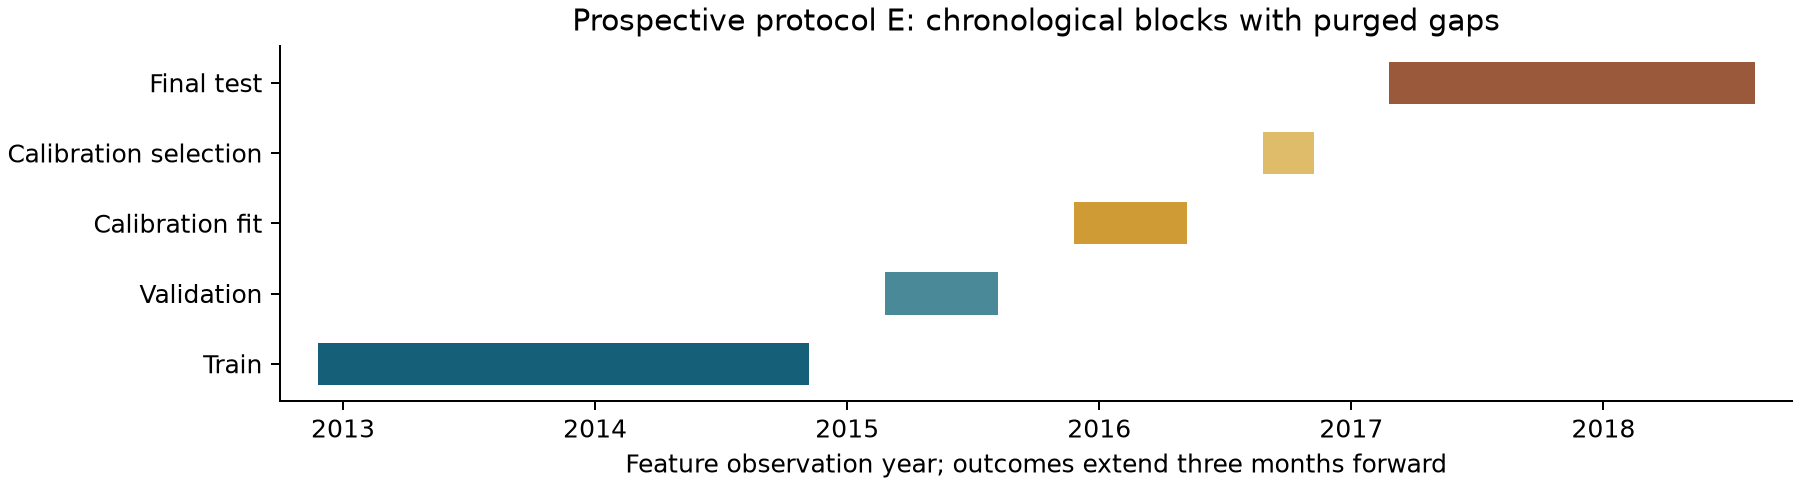

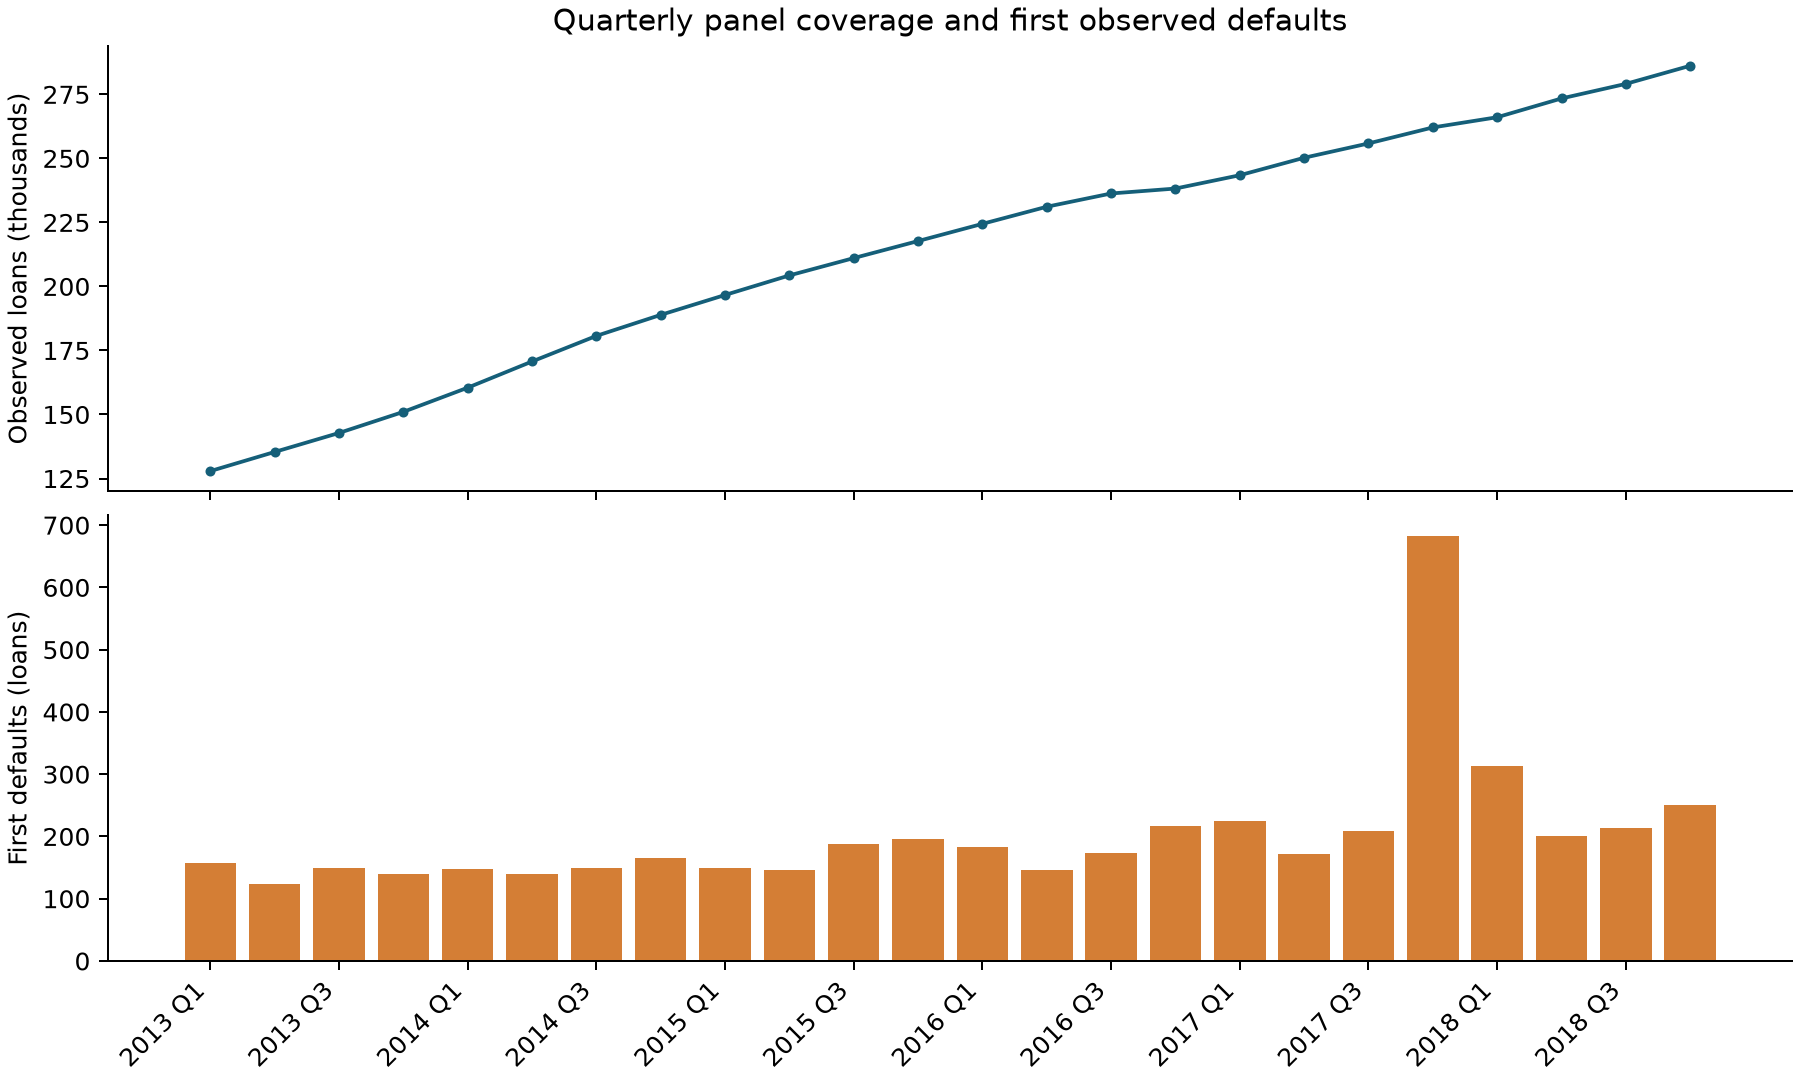

In [ ]:
display(pd.read_csv(PROJECT_DIR/"reports/feature_missingness.csv").query("protocol == 'R'")[["feature", "missing_fraction"]])
if NotebookImage is not None:
    display(NotebookImage(filename=str(PROJECT_DIR/"reports/figures/temporal_splits.png")))
    display(NotebookImage(filename=str(PROJECT_DIR/"reports/figures/quarterly_coverage.png")))


### 1.10 One loader for the whole team
`load_xy` reads one split (and, if needed, one state) instead of all the millions of rows. Only the allowed features go into `X`; ids, dates and groups go to `meta`, so nobody feeds them into a model by accident. Example for California:

In [ ]:
import json
from pathlib import Path
import pandas as pd

def load_xy(root,protocol='R',split='train',extended=False,state=None):
    root=Path(root)
    config=json.loads((root/'config.json').read_text())
    spec=config[protocol]
    numeric=list(spec['numeric']);categorical=list(spec['categorical'])
    if extended:
        numeric+=config['optional_extended_features']['numeric']
        categorical+=config['optional_extended_features']['categorical']
    features=numeric+categorical
    columns=list(dict.fromkeys(['loan_id','state','report_date',spec['target'],spec['split']]+features))
    filters=[(spec['split'],'=',split)]
    if state:filters.append(('state','=',state))
    d=pd.read_parquet(root/'data'/spec['file'],columns=columns,filters=filters)
    X=d[features].copy()
    for c in numeric:X[c]=X[c].astype('float32')
    for c in categorical:X[c]=X[c].fillna('UNKNOWN')
    y=d[spec['target']].astype('int8')
    metadata=d[['loan_id','state','report_date',spec['split']]].copy()
    return X,y,metadata


In [ ]:
NUMERIC_FEATURES = CONFIG["R"]["numeric"]
CATEGORICAL_FEATURES = CONFIG["R"]["categorical"]

X_train, y_train, meta_train = load_xy(PROJECT_DIR, protocol="R", split="train", state=REGION_FOR_EXAMPLE)
X_valid, y_valid, meta_valid = load_xy(PROJECT_DIR, protocol="R", split="validation", state=REGION_FOR_EXAMPLE)
assert list(X_train) == NUMERIC_FEATURES + CATEGORICAL_FEATURES
assert set(meta_train.loan_id).isdisjoint(set(meta_valid.loan_id))
print("Example load, state:", REGION_FOR_EXAMPLE)
print("Train:", X_train.shape, "- defaults:", int(y_train.sum()))
print("Validation:", X_valid.shape, "- defaults:", int(y_valid.sum()))
display(X_train.head())


Example load, state: CA
Train: (393048, 10) - defaults: 236
Validation: (133041, 10) - defaults: 79


,orig_dti_pct,current_rate_pct,current_ltv_proxy_pct,seniority_months,log_orig_property_value_proxy,gdp_growth_lag2y_pct,unemployment_change_lag2y_pp,hpi_growth_lag3m_pct,regional_default_rate_lag4q,property_type
0,47.0,4.750,69.161171,21.0,13.559791,4.829949,-1.4,6.564809,0.000444,PU
1,36.0,4.000,39.058109,36.0,13.614186,3.053135,-0.7,7.284570,0.000704,SF
2,32.0,3.625,24.773870,7.0,12.859999,3.774690,-1.4,7.654283,0.000527,SF
3,29.0,4.250,80.624451,9.0,12.990191,3.774690,-1.4,7.413194,0.000694,SF
4,18.0,4.125,50.438309,19.0,12.054842,4.829949,-1.4,6.564809,0.000444,SF


# Part 2. Replication of the paper on protocol R

This part compares penalized logistic regression, gradient boosting and XGBoost using the prepared Freddie Mac data. I start with California to check the full process before running it for more states.

All models will use the same features and loan splits. I will choose the settings on the validation set and use the test set for the final comparison.

In [ ]:
import pandas as pd

features = CONFIG["R"]["numeric"] + CONFIG["R"]["categorical"]

assert list(X_train.columns) == features
assert list(X_valid.columns) == features

assert len(X_train) == len(y_train) == len(meta_train)
assert len(X_valid) == len(y_valid) == len(meta_valid)

assert set(meta_train["loan_id"]).isdisjoint(meta_valid["loan_id"])
assert y_train.isin([0, 1]).all()
assert y_valid.isin([0, 1]).all()

info = pd.DataFrame(
    {
        "rows": [len(X_train), len(X_valid)],
        "loans": [
            meta_train["loan_id"].nunique(),
            meta_valid["loan_id"].nunique(),
        ],
        "defaults": [int(y_train.sum()), int(y_valid.sum())],
        "default_rate_pct": [100 * y_train.mean(), 100 * y_valid.mean()],
    },
    index=["train", "validation"],
)

print("State:", REGION_FOR_EXAMPLE)
display(info)

missing = pd.DataFrame(
    {
        "train": X_train.isna().mean(),
        "validation": X_valid.isna().mean(),
    }
)

display(missing)

State: CA


,rows,loans,defaults,default_rate_pct
train,393048,33369,236,0.060044
validation,133041,11093,79,0.059380


,train,validation
orig_dti_pct,0.210285,0.212100
current_rate_pct,0.000000,0.000000
current_ltv_proxy_pct,0.000061,0.000113
seniority_months,0.000000,0.000000
log_orig_property_value_proxy,0.000061,0.000113
gdp_growth_lag2y_pct,0.000000,0.000000
unemployment_change_lag2y_pp,0.000000,0.000000
hpi_growth_lag3m_pct,0.000000,0.000000
regional_default_rate_lag4q,0.000000,0.000000
property_type,0.000000,0.000000


### 2.1 Checking the California data

Before preparing the features, I check missing values and zeros in the training data. I also look at how many different values each feature has and count unknown property types.

In [ ]:
check = pd.DataFrame({
    "missing_train": X_train.isna().sum(),
    "missing_valid": X_valid.isna().sum(),
    "missing_train_pct": X_train.isna().mean() * 100,
    "zeros_train": X_train.eq(0).sum(),
    "unique_train": X_train.nunique()
})

display(check.round(4))

print(
    "Unknown property types in train:",
    X_train["property_type"].eq("UNKNOWN").sum()
)

print(
    "Unknown property types in validation:",
    X_valid["property_type"].eq("UNKNOWN").sum()
)

,missing_train,missing_valid,missing_train_pct,zeros_train,unique_train
orig_dti_pct,82652,28218,21.0285,0,55
current_rate_pct,0,0,0.0000,0,265
current_ltv_proxy_pct,24,15,0.0061,17,371971
seniority_months,0,0,0.0000,0,107
log_orig_property_value_proxy,24,15,0.0061,0,12591
gdp_growth_lag2y_pct,0,0,0.0000,0,6
unemployment_change_lag2y_pp,0,0,0.0000,0,4
hpi_growth_lag3m_pct,0,0,0.0000,0,72
regional_default_rate_lag4q,0,0,0.0000,0,24
property_type,0,0,0.0000,0,5


Unknown property types in train: 0
Unknown property types in validation: 0


I check whether zero LTV values are linked to default. Since LTV is calculated using the current loan balance, these zeros may reflect the loan's status around the default event.

In [ ]:
for name, X, y in [
    ("Train", X_train, y_train),
    ("Validation", X_valid, y_valid)
]:
    zero_ltv = X["current_ltv_proxy_pct"].eq(0)

    print(name)
    display(pd.crosstab(
        zero_ltv,
        y,
        rownames=["zero_ltv"],
        colnames=["default"]
    ))

Train


default,0,1
zero_ltv,,
False,392812,219
True,0,17


Validation


default,0,1
zero_ltv,,
False,132962,74
True,0,5


All zero LTV observations in the training and validation sets are defaults. I examine the monthly status and exit codes of the training cases to understand how these values were recorded.

In [ ]:
zero = X_train["current_ltv_proxy_pct"].eq(0)

cases = meta_train.loc[
    zero, ["loan_id", "report_date"]
].copy()

cases["report_ym"] = (
    pd.to_datetime(cases["report_date"])
    .dt.strftime("%Y%m")
    .astype(int)
)

audit = pd.read_parquet(
    PROJECT_DIR / "data" / "audit_only.parquet",
    columns=["loan_id", "report_ym", "delinquency_raw", "zero_code"],
    filters=[("loan_id", "in", cases["loan_id"].tolist())]
)

cases = cases.merge(
    audit,
    on=["loan_id", "report_ym"],
    how="left",
    validate="one_to_one",
    indicator=True
)

assert cases["_merge"].eq("both").all()

display(cases[
    ["loan_id", "report_date", "delinquency_raw", "zero_code"]
])

display(
    cases.groupby(["delinquency_raw", "zero_code"])
    .size()
    .reset_index(name="rows")
)

,loan_id,report_date,delinquency_raw,zero_code
0,F15Q10199616,2017-09-30,03,01
1,F11Q40077870,2017-09-30,03,01
2,F11Q30107664,2014-12-31,03,01
3,F12Q20145670,2015-08-31,03,01
4,F11Q30045259,2016-06-30,03,01
5,F16Q20305209,2018-05-31,03,01
6,F11Q10099213,2014-09-30,03,01
7,F14Q20123007,2018-06-30,03,01
8,F12Q20412380,2015-11-30,03,01
9,F14Q20115856,2016-04-30,03,01


,delinquency_raw,zero_code,rows
0,03,01,17


The R sample includes zero-balance observations with recorded delinquency. Its selection rule makes zero LTV a strong indicator of the event, so I will compare the models with and without current LTV using the same observations.

### 2.2 Preprocessing

I fill missing numerical values with training-set medians and add an indicator for missing DTI. The same medians are applied to the validation set.

In [ ]:
num = CONFIG["R"]["numeric"]

medians = X_train[num].median()
assert medians.notna().all()

train = X_train.copy()
valid = X_valid.copy()

train["dti_missing"] = X_train["orig_dti_pct"].isna().astype(int)
valid["dti_missing"] = X_valid["orig_dti_pct"].isna().astype(int)

train[num] = train[num].fillna(medians)
valid[num] = valid[num].fillna(medians)

assert train.notna().all().all()
assert valid.notna().all().all()

display(medians.to_frame("training_median"))

print("Train shape:", train.shape)
print("Validation shape:", valid.shape)

print("Missing DTI in train:", train["dti_missing"].sum())
print("Missing DTI in validation:", valid["dti_missing"].sum())

,training_median
orig_dti_pct,37.000000
current_rate_pct,4.125000
current_ltv_proxy_pct,52.560040
seniority_months,26.000000
log_orig_property_value_proxy,12.926619
gdp_growth_lag2y_pct,3.764148
unemployment_change_lag2y_pp,-1.400000
hpi_growth_lag3m_pct,7.320210
regional_default_rate_lag4q,0.000628


Train shape: (393048, 11)
Validation shape: (133041, 11)
Missing DTI in train: 82652
Missing DTI in validation: 28218


I use one-hot encoding for property type, creating a separate 0/1 column for each category. The training set defines the columns, and I align the validation set to the same structure.

In [ ]:
train_encoded = pd.get_dummies(
    train, columns=["property_type"], dtype=int
)

valid_encoded = pd.get_dummies(
    valid, columns=["property_type"], dtype=int
)

model_columns = train_encoded.columns.tolist()

valid_encoded = valid_encoded.reindex(
    columns=model_columns, fill_value=0
)

assert train_encoded.columns.equals(valid_encoded.columns)
assert train_encoded.index.equals(y_train.index)
assert valid_encoded.index.equals(y_valid.index)

assert train_encoded.select_dtypes(exclude="number").shape[1] == 0
assert valid_encoded.select_dtypes(exclude="number").shape[1] == 0

print("Train shape:", train_encoded.shape)
print("Validation shape:", valid_encoded.shape)

display(train_encoded.filter(like="property_type_").head())

Train shape: (393048, 15)
Validation shape: (133041, 15)


,property_type_CO,property_type_CP,property_type_MH,property_type_PU,property_type_SF
0,0,0,0,1,0
1,0,0,0,0,1
2,0,0,0,0,1
3,0,0,0,0,1
4,0,0,0,0,1


California was used to check the preprocessing steps. I now review the training and validation samples for all states and the District of Columbia before fitting regional models.

In [ ]:
r = pd.read_parquet(
    PROJECT_DIR / "data" / CONFIG["R"]["file"],
    columns=["state", "loan_id", "split_R", "target_default"],
    filters=[("split_R", "in", ["train", "validation"])]
)

states = (
    r.groupby(["state", "split_R"])
    .agg(
        rows=("loan_id", "size"),
        loans=("loan_id", "nunique"),
        defaults=("target_default", "sum")
    )
    .reset_index()
)

print("Number of regions:", states["state"].nunique())

display(
    states.pivot(
        index="state",
        columns="split_R",
        values=["rows", "loans", "defaults"]
    )
)

print("Totals:")
display(
    states.groupby("split_R")[["rows", "loans", "defaults"]].sum()
)

del r

Number of regions: 51


rows             loans            defaults           
split_R   train validation  train validation    train validation
state                                                           
AK         6556       2390    495        172        2          1
AL        30681       9874   2431        822       34         12
AR        20376       6504   1601        534       14          4
AZ        81090      27187   6969       2332       68         28
CA       393048     133041  33369      11093      236         79
CO        77781      25913   7201       2424       42         14
CT        36286      11677   2608        875       48         18
DC         7063       2495    583        200        5          2
DE        11186       3614    839        274       14          3
FL       171290      57122  14343       4766      404        137
GA        91647      30422   7389       2447       83         28
HI        12180       4050    906        307        7          2
IA        29538       9903   2300        777       17          6
ID        18841       6345   1617        548       17          5
IL       157038      51915  12243       4089      175         64
IN        72441      23629   5761       1907       59         20
KS        29944       9969   2352        779       20          7
KY        42842      14182   3359       1123       26          8
LA        27517       8949   2150        717       48         16
MA        76996      25419   6060       2050       51         16
MD        71649      24055   5285       1764       80         30
ME        13395       4650   1049        359       11          4
MI       116321      38742   9386       3130       93         30
MN        89044      29519   6733       2244       68         20
MO        68487      22974   5369       1782       58         17
MS         9586       3138    777        260       12          5
MT        11918       3856    939        318        9          3
NC       103030      34420   8065       2683       80         24
ND         7537       2617    622        206        5          2
NE        15306       5357   1210        419        8          3
NH        17443       5862   1356        453       15          5
NJ        82065      27383   6393       2133      104         38
NM        16049       5046   1188        390       15          5
NV        28938       9009   2558        848       25          9
NY       118829      39516   8630       2860      124         39
OH       116454      38850   8952       2976       87         27
OK        22143       7151   1804        597       20          6
OR        55907      18391   4670       1542       29          8
PA       102897      33950   7698       2563      109         33
RI        11201       3585    874        281       15          4
SC        42689      14164   3512       1178       39         13
SD         5353       1714    447        145        1          1
TN        51925      17105   4407       1465       35          9
TX       183582      61336  16176       5386      219         72
UT        41419      13556   3702       1245       30          9
VA        95234      31798   7189       2392       74         23
VT         9794       3269    736        240        5          2
WA        91077      30759   7632       2554       69         25
WI        73194      23904   5652       1855       62         22
WV         9170       2813    691        233        8          3
WY         4867       1694    415        131        3          1

Totals:


,rows,loans,defaults
split_R,,,
train,3080844,248693,2882
validation,1024783,82868,962


I standardize the numerical features for logistic regression because the penalty depends on their scale. The scaler is fitted on the training set and then applied to validation.

In [ ]:
import sklearn
from sklearn.preprocessing import StandardScaler

num = CONFIG["R"]["numeric"]

scaler = StandardScaler()

train_scaled = train_encoded.copy()
valid_scaled = valid_encoded.copy()

train_scaled[num] = scaler.fit_transform(train_encoded[num])
valid_scaled[num] = scaler.transform(valid_encoded[num])

check = pd.DataFrame({
    "mean": train_scaled[num].mean(),
    "std": train_scaled[num].std(ddof=0)
})

print("Current state:", REGION_FOR_EXAMPLE)
print("scikit-learn version:", sklearn.__version__)
print("Train shape:", train_scaled.shape)
print("Validation shape:", valid_scaled.shape)

display(check.round(4))

Current state: CA
scikit-learn version: 1.6.1
Train shape: (393048, 15)
Validation shape: (133041, 15)


,mean,std
orig_dti_pct,-0.0,1.0001
current_rate_pct,-0.0,1.0002
current_ltv_proxy_pct,0.0,0.9999
seniority_months,-0.0,0.9999
log_orig_property_value_proxy,0.0,1.0000
gdp_growth_lag2y_pct,-0.0,0.9995
unemployment_change_lag2y_pp,-0.0,1.0000
hpi_growth_lag3m_pct,-0.0,1.0000
regional_default_rate_lag4q,0.0,0.9997


### 2.3 Pilot models for California

I first fit an elastic-net logistic regression for California using the full training sample. This run uses one set of parameters to check convergence, validation performance and training time before tuning.

In [ ]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss
)

logit = LogisticRegression(
    penalty="elasticnet",
    solver="saga",
    l1_ratio=0.5,
    C=1.0,
    max_iter=2000,
    random_state=20261116
)

start = time.time()
logit.fit(train_scaled, y_train)

p_valid_logit = logit.predict_proba(valid_scaled)[:, 1]

print("Training time, seconds:", round(time.time() - start, 1))
print("Iterations:", logit.n_iter_[0])

scores = pd.Series({
    "ROC AUC": roc_auc_score(y_valid, p_valid_logit),
    "Average precision": average_precision_score(y_valid, p_valid_logit),
    "Brier score": brier_score_loss(y_valid, p_valid_logit),
    "Log loss": log_loss(y_valid, p_valid_logit),
    "Mean predicted probability": p_valid_logit.mean(),
    "Observed default rate": y_valid.mean()
})

display(scores.to_frame("validation"))

Training time, seconds: 105.1
Iterations: 316


,validation
ROC AUC,0.714205
Average precision,0.002059
Brier score,0.000593
Log loss,0.004810
Mean predicted probability,0.000596
Observed default rate,0.000594


I next fit a histogram-based gradient boosting model on the same training observations and features. The parameters are preliminary. I compare its validation predictions with logistic regression and a constant probability based on the training default rate.

In [ ]:
import time
import numpy as np
from sklearn.ensemble import HistGradientBoostingClassifier

gb = HistGradientBoostingClassifier(
    learning_rate=0.1,
    max_iter=60,
    max_depth=3,
    min_samples_leaf=100,
    early_stopping=False,
    random_state=20261116
)

start = time.time()

gb.fit(train_encoded, y_train)
p_valid_gb = gb.predict_proba(valid_encoded)[:, 1]

print("GB time, seconds:", round(time.time() - start, 1))
print("Boosting iterations:", gb.n_iter_)

p_constant = np.full(len(y_valid), y_train.mean())

results = []

for name, p in [
    ("Constant probability", p_constant),
    ("Logistic regression", p_valid_logit),
    ("Gradient boosting", p_valid_gb)
]:
    results.append({
        "model": name,
        "ROC AUC": roc_auc_score(y_valid, p),
        "Average precision": average_precision_score(y_valid, p),
        "Brier score": brier_score_loss(y_valid, p),
        "Log loss": log_loss(y_valid, p),
        "Mean probability": p.mean()
    })

comparison = pd.DataFrame(results).set_index("model")

with pd.option_context("display.float_format", "{:.8f}".format):
    display(comparison)

print("Observed default rate:", round(y_valid.mean(), 8))

GB time, seconds: 3.1
Boosting iterations: 60


,ROC AUC,Average precision,Brier score,Log loss,Mean probability
model,,,,,
Constant probability,0.50000000,0.00059380,0.00059345,0.00500500,0.00060044
Logistic regression,0.71420549,0.00205876,0.00059315,0.00481029,0.00059614
Gradient boosting,0.83483489,0.03307605,0.00064682,0.00438271,0.00067415


Observed default rate: 0.0005938


Gradient boosting gives a higher validation ROC AUC and average precision than logistic regression, but its Brier score is worse. I inspect the predictions that contribute most to this difference before fitting XGBoost.

In [ ]:
errors = pd.DataFrame({
    "default": y_valid.to_numpy(),
    "p_logit": p_valid_logit,
    "p_gb": p_valid_gb,
    "current_ltv": X_valid["current_ltv_proxy_pct"].to_numpy()
})

errors["zero_ltv"] = errors["current_ltv"].eq(0)

errors["error_logit"] = (errors["p_logit"] - errors["default"]) ** 2
errors["error_gb"] = (errors["p_gb"] - errors["default"]) ** 2

errors["extra_error"] = errors["error_gb"] - errors["error_logit"]

parts = errors.groupby("default").agg(
    rows=("default", "size"),
    brier_logit=("error_logit", "sum"),
    brier_gb=("error_gb", "sum"),
    mean_gb=("p_gb", "mean"),
    max_gb=("p_gb", "max")
)

parts[["brier_logit", "brier_gb"]] = (
    parts[["brier_logit", "brier_gb"]] / len(errors)
)

largest_errors = errors.sort_values(
    "extra_error", ascending=False
).head(10)

with pd.option_context("display.float_format", "{:.8f}".format):
    print("Brier contributions by outcome")
    display(parts)

    print("Largest increases in squared error")
    display(largest_errors[[
        "default", "p_logit", "p_gb",
        "current_ltv", "zero_ltv", "extra_error"
    ]])

Brier contributions by outcome


,rows,brier_logit,brier_gb,mean_gb,max_gb
default,,,,,
0,132962,0.00000079,0.00010307,0.00064576,0.98882252
1,79,0.00059235,0.00054375,0.04846437,0.50450363


Largest increases in squared error


,default,p_logit,p_gb,current_ltv,zero_ltv,extra_error
69702,0,0.00099225,0.98882252,3.96692657,False,0.97776899
45645,0,0.00196711,0.98671968,0.74806893,False,0.97361185
93980,0,0.00090988,0.95635839,0.14965016,False,0.91462053
90545,0,0.00198331,0.94299471,0.44412079,False,0.88923510
111996,0,0.00286090,0.74217344,105.36825562,False,0.55081323
4666,0,0.00088970,0.70289506,3.50537729,False,0.49406067
82141,0,0.00098966,0.70167985,2.36482954,False,0.49235363
56148,0,0.00115328,0.68059647,3.14670968,False,0.46321022
35318,0,0.00111998,0.66708310,2.73789930,False,0.44499861
31803,0,0.00115817,0.64279569,1.68583953,False,0.41318495


I fit XGBoost on the same training observations and features. I use 60 trees with a maximum depth of 3 and keep the original class distribution. I compare its validation performance with the previous models.

In [ ]:
import xgboost
from xgboost import XGBClassifier

print("XGBoost version:", xgboost.__version__)

xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=60,
    learning_rate=0.1,
    max_depth=3,
    min_child_weight=1,
    reg_lambda=1.0,
    subsample=1.0,
    colsample_bytree=1.0,
    scale_pos_weight=1.0,
    base_score=float(y_train.mean()),
    tree_method="hist",
    n_jobs=2,
    random_state=20261116
)

start = time.time()

xgb_model.fit(train_encoded, y_train)
p_valid_xgb = xgb_model.predict_proba(valid_encoded)[:, 1]

xgb_time = time.time() - start
print("XGBoost time, seconds:", round(xgb_time, 1))

comparison.loc["XGBoost"] = {
    "ROC AUC": roc_auc_score(y_valid, p_valid_xgb),
    "Average precision": average_precision_score(y_valid, p_valid_xgb),
    "Brier score": brier_score_loss(y_valid, p_valid_xgb),
    "Log loss": log_loss(y_valid, p_valid_xgb),
    "Mean probability": p_valid_xgb.mean()
}

with pd.option_context("display.float_format", "{:.8f}".format):
    display(comparison)

print("Observed default rate:", round(y_valid.mean(), 8))

XGBoost version: 3.4.1
XGBoost time, seconds: 1.9


,ROC AUC,Average precision,Brier score,Log loss,Mean probability
model,,,,,
Constant probability,0.50000000,0.00059380,0.00059345,0.00500500,0.00060044
Logistic regression,0.71420549,0.00205876,0.00059315,0.00481029,0.00059614
Gradient boosting,0.83483489,0.03307605,0.00064682,0.00438271,0.00067415
XGBoost,0.78022254,0.03918060,0.00058869,0.00452967,0.00059506


Observed default rate: 0.0005938


I repeat the three models without the current LTV proxy, using the same observations, labels and model settings. This check shows how much validation performance depends on this feature. The original models and predictions are kept for comparison.

In [ ]:
from sklearn.base import clone

remove = ["current_ltv_proxy_pct"]

train_no_ltv = train_encoded.drop(columns=remove)
valid_no_ltv = valid_encoded.drop(columns=remove)

train_no_ltv_scaled = train_scaled.drop(columns=remove)
valid_no_ltv_scaled = valid_scaled.drop(columns=remove)

models_no_ltv = {
    "Logistic regression": clone(logit),
    "Gradient boosting": clone(gb),
    "XGBoost": clone(xgb_model)
}

pred_no_ltv = {}
rows = []

for name, model in models_no_ltv.items():
    print("Fitting:", name, flush=True)
    start = time.time()

    if name == "Logistic regression":
        model.fit(train_no_ltv_scaled, y_train)
        p = model.predict_proba(valid_no_ltv_scaled)[:, 1]
    else:
        model.fit(train_no_ltv, y_train)
        p = model.predict_proba(valid_no_ltv)[:, 1]

    seconds = time.time() - start
    pred_no_ltv[name] = p

    print("Time, seconds:", round(seconds, 1), flush=True)

    if name == "Logistic regression":
        print("Iterations:", model.n_iter_[0], flush=True)

    rows.append({
        "model": name,
        "ROC AUC": roc_auc_score(y_valid, p),
        "Average precision": average_precision_score(y_valid, p),
        "Brier score": brier_score_loss(y_valid, p),
        "Log loss": log_loss(y_valid, p),
        "Mean probability": p.mean()
    })

no_ltv_scores = pd.DataFrame(rows).set_index("model")

print("\nWithout current LTV")
print("Train shape:", train_no_ltv.shape)
print("Validation shape:", valid_no_ltv.shape)

with pd.option_context("display.float_format", "{:.8f}".format):
    display(no_ltv_scores)

In [ ]:
from pathlib import Path
import joblib
import platform
import zipfile

# All part 2 files go to /content/mortgage_part2.
# If our saved part 2 results (Participant_4_Evaluation_R.zip) are in /content, they are unpacked first,
# so the long regional loop below skips the states that are already done.
PART2_DIR = Path("/content/mortgage_part2")
frozen_part2 = Path("/content/Participant_4_Evaluation_R.zip")
if frozen_part2.is_file() and not PART2_DIR.exists():
    with zipfile.ZipFile(frozen_part2) as z:
        z.extractall("/content")

save_dir = PART2_DIR / "CA_pilot"
save_dir.mkdir(parents=True, exist_ok=True)

models_full = {
    "Logistic regression": logit,
    "Gradient boosting": gb,
    "XGBoost": xgb_model
}

assert meta_valid.index.equals(y_valid.index)

pred = meta_valid.reset_index(drop=True).copy()
pred["protocol"] = "R"
pred["split"] = "validation"
pred["y_true"] = y_valid.to_numpy()
pred["constant"] = p_constant

pred["logit_full"] = p_valid_logit
pred["gb_full"] = p_valid_gb
pred["xgb_full"] = p_valid_xgb

pred["logit_no_ltv"] = pred_no_ltv["Logistic regression"]
pred["gb_no_ltv"] = pred_no_ltv["Gradient boosting"]
pred["xgb_no_ltv"] = pred_no_ltv["XGBoost"]

pilot = {
    "state": "CA",
    "protocol": "R",
    "stage": "pilot",
    "seed": 20261116,
    "training_sample": "natural",
    "models_full": models_full,
    "models_no_ltv": models_no_ltv,
    "medians": medians,
    "scaler": scaler,
    "numeric_columns": CONFIG["R"]["numeric"],
    "encoded_columns": train_encoded.columns.tolist(),
    "columns_no_ltv": train_no_ltv.columns.tolist(),
    "params_full": {
        name: model.get_params()
        for name, model in models_full.items()
    },
    "params_no_ltv": {
        name: model.get_params()
        for name, model in models_no_ltv.items()
    },
    "versions": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit-learn": sklearn.__version__,
        "xgboost": xgboost.__version__,
        "joblib": joblib.__version__
    }
}

joblib.dump(pilot, save_dir / "pilot_models.joblib", compress=3)
pred.to_parquet(save_dir / "validation_predictions.parquet", index=False)

comparison.to_csv(save_dir / "scores_full.csv")
no_ltv_scores.to_csv(save_dir / "scores_no_ltv.csv")

print("Saved to:", save_dir)
print("Validation rows saved:", len(pred))

for file in sorted(save_dir.iterdir()):
    print(file.name)

### 2.4 Tuning on a fixed grid

I use a fixed search budget of 12 configurations for each model and select parameters by validation ROC AUC. The main search uses all features and the original class distribution. I then reuse the selected settings for the comparison without current LTV.

All part 2 results are saved to `/content/mortgage_part2`. Training all 51 regions takes a few hours; if our saved results are uploaded, the states that are already done are skipped.

In [ ]:
import json
from sklearn.model_selection import ParameterGrid

grids = {}

grids["Logistic regression"] = []

for ratio in [0.0, 0.5, 1.0]:
    for c in [0.01, 0.1, 1.0, 10.0]:
        grids["Logistic regression"].append({
            "C": c,
            "l1_ratio": ratio
        })

grids["Gradient boosting"] = list(ParameterGrid({
    "max_iter": [20, 40, 60],
    "max_depth": [3, 6],
    "learning_rate": [0.05, 0.1]
}))

grids["XGBoost"] = list(ParameterGrid({
    "n_estimators": [20, 40, 60],
    "max_depth": [3, 6],
    "learning_rate": [0.05, 0.1]
}))

plan = {
    "state": "CA",
    "protocol": "R",
    "seed": 20261116,
    "features": train_encoded.columns.tolist(),
    "training_sample": "natural",
    "selection_metric": "validation ROC AUC",
    "tie_break": "first candidate in the recorded grid order",
    "preprocessing": "fitted on train only",
    "no_ltv_check": "refit with selected parameters",
    "test": "not used during tuning",
    "grids": grids
}

search_dir = save_dir.parent / "CA_search"
search_dir.mkdir(parents=True, exist_ok=True)

with open(search_dir / "search_plan.json", "w", encoding="utf-8") as file:
    json.dump(plan, file, indent=2)

base_models = {
    name: clone(model)
    for name, model in models_full.items()
}

joblib.dump(base_models, search_dir / "base_models.joblib")

for name, candidates in grids.items():
    assert len(candidates) == 12
    print(name, "— configurations:", len(candidates))

print("Selection metric:", plan["selection_metric"])
print("Saved to:", search_dir)

In [ ]:
import warnings
from copy import deepcopy
from sklearn.exceptions import ConvergenceWarning

logit_rows = []
best_auc = -np.inf
best_logit = None
last_ratio = None

for i, params in enumerate(grids["Logistic regression"], start=1):
    ratio = params["l1_ratio"]

    if ratio != last_ratio:
        model = clone(base_models["Logistic regression"])
        model.set_params(warm_start=True)
        last_ratio = ratio

    model.set_params(**params)

    print(
        f"\n{i}/12 — C={params['C']}, l1_ratio={ratio}",
        flush=True
    )

    start = time.time()

    with warnings.catch_warnings(record=True) as found:
        warnings.simplefilter("always")
        model.fit(train_scaled, y_train)

    seconds = time.time() - start
    p = model.predict_proba(valid_scaled)[:, 1]

    converged = not any(
        issubclass(w.category, ConvergenceWarning)
        for w in found
    )
    notes = " | ".join(str(w.message) for w in found)

    row = {
        "candidate": i,
        "C": params["C"],
        "l1_ratio": ratio,
        "ROC AUC": roc_auc_score(y_valid, p),
        "Average precision": average_precision_score(y_valid, p),
        "Brier score": brier_score_loss(y_valid, p),
        "Log loss": log_loss(y_valid, p),
        "Mean probability": p.mean(),
        "fit_seconds": round(seconds, 2),
        "iterations": int(model.n_iter_[0]),
        "converged": converged,
        "warnings": notes
    }

    logit_rows.append(row)
    logit_search = pd.DataFrame(logit_rows)
    logit_search.to_csv(search_dir / "logit_search.csv", index=False)

    joblib.dump(
        {"candidate": i, "model": model},
        search_dir / "last_logit.joblib",
        compress=3
    )

    if converged and row["ROC AUC"] > best_auc:
        best_auc = row["ROC AUC"]
        best_logit = deepcopy(model)
        best_p_logit = p.copy()

        joblib.dump(
            {"model": best_logit, "info": row.copy()},
            search_dir / "best_logit.joblib",
            compress=3
        )

        best_pred = meta_valid.copy()
        best_pred["protocol"] = "R"
        best_pred["split"] = "validation"
        best_pred["y_true"] = y_valid.to_numpy()
        best_pred["p_logit"] = best_p_logit
        best_pred.to_parquet(
            search_dir / "best_logit_validation.parquet",
            index=False
        )

    print(
        f"AUC={row['ROC AUC']:.6f}, "
        f"iterations={row['iterations']}, "
        f"seconds={seconds:.1f}, converged={converged}",
        flush=True
    )

    if notes:
        print(notes, flush=True)

show = [
    "C", "l1_ratio", "ROC AUC", "Average precision",
    "Brier score", "Log loss", "iterations", "converged"
]

with pd.option_context("display.float_format", "{:.8f}".format):
    display(logit_search[show])

print("Converged fits:", int(logit_search["converged"].sum()), "/ 12")

if best_logit is not None:
    print("Best converged ROC AUC:", round(best_auc, 8))
    print("Best C:", best_logit.C)
    print("Best l1_ratio:", best_logit.l1_ratio)
else:
    print("No converged model. Check the saved warnings.")

In [ ]:
gb_rows = []
best_gb_auc = -np.inf
best_gb = None

for i, params in enumerate(grids["Gradient boosting"], start=1):
    model = clone(base_models["Gradient boosting"])
    model.set_params(**params)

    print(f"\n{i}/12 — {params}", flush=True)

    start = time.time()

    with warnings.catch_warnings(record=True) as found:
        warnings.simplefilter("always")
        model.fit(train_encoded, y_train)

    seconds = time.time() - start
    p = model.predict_proba(valid_encoded)[:, 1]

    assert np.isfinite(p).all()
    assert ((p >= 0) & (p <= 1)).all()

    notes = " | ".join(str(w.message) for w in found)

    row = {
        "candidate": i,
        "max_iter": params["max_iter"],
        "max_depth": params["max_depth"],
        "learning_rate": params["learning_rate"],
        "ROC AUC": roc_auc_score(y_valid, p),
        "Average precision": average_precision_score(y_valid, p),
        "Brier score": brier_score_loss(y_valid, p),
        "Log loss": log_loss(y_valid, p),
        "Mean probability": p.mean(),
        "fit_seconds": round(seconds, 2),
        "iterations": int(model.n_iter_),
        "warnings": notes
    }

    gb_rows.append(row)
    gb_search = pd.DataFrame(gb_rows)
    gb_search.to_csv(search_dir / "gb_search.csv", index=False)

    if row["ROC AUC"] > best_gb_auc:
        best_gb_auc = row["ROC AUC"]
        best_gb = model
        best_p_gb = p.copy()

        joblib.dump(
            {
                "model": best_gb,
                "params": best_gb.get_params(),
                "info": row.copy()
            },
            search_dir / "best_gb.joblib",
            compress=3
        )

        best_pred = meta_valid.copy()
        best_pred["protocol"] = "R"
        best_pred["split"] = "validation"
        best_pred["y_true"] = y_valid.to_numpy()
        best_pred["p_gb"] = best_p_gb
        best_pred.to_parquet(
            search_dir / "best_gb_validation.parquet",
            index=False
        )

    print(
        f"AUC={row['ROC AUC']:.6f}, "
        f"Brier={row['Brier score']:.8f}, "
        f"seconds={seconds:.1f}",
        flush=True
    )

    if notes:
        print(notes, flush=True)

show = [
    "max_iter", "max_depth", "learning_rate",
    "ROC AUC", "Average precision",
    "Brier score", "Log loss", "Mean probability"
]

with pd.option_context("display.float_format", "{:.8f}".format):
    display(gb_search[show])

print("Best validation ROC AUC:", round(best_gb_auc, 8))
print("Best number of trees:", best_gb.max_iter)
print("Best depth:", best_gb.max_depth)
print("Best learning rate:", best_gb.learning_rate)

In [ ]:
xgb_rows = []
best_xgb_auc = -np.inf
best_xgb = None

for i, params in enumerate(grids["XGBoost"], start=1):
    model = clone(base_models["XGBoost"])
    model.set_params(**params)

    print(f"\n{i}/12 — {params}", flush=True)

    start = time.time()

    with warnings.catch_warnings(record=True) as found:
        warnings.simplefilter("always")
        model.fit(train_encoded, y_train)

    seconds = time.time() - start
    p = model.predict_proba(valid_encoded)[:, 1].astype("float64")

    assert np.isfinite(p).all()
    assert ((p >= 0) & (p <= 1)).all()

    notes = " | ".join(str(w.message) for w in found)

    row = {
        "candidate": i,
        "n_estimators": params["n_estimators"],
        "max_depth": params["max_depth"],
        "learning_rate": params["learning_rate"],
        "ROC AUC": roc_auc_score(y_valid, p),
        "Average precision": average_precision_score(y_valid, p),
        "Brier score": brier_score_loss(y_valid, p),
        "Log loss": log_loss(y_valid, p),
        "Mean probability": p.mean(),
        "fit_seconds": round(seconds, 2),
        "iterations": int(model.get_booster().num_boosted_rounds()),
        "warnings": notes
    }

    xgb_rows.append(row)
    xgb_search = pd.DataFrame(xgb_rows)
    xgb_search.to_csv(search_dir / "xgb_search.csv", index=False)

    if row["ROC AUC"] > best_xgb_auc:
        best_xgb_auc = row["ROC AUC"]
        best_xgb = model
        best_p_xgb = p.copy()

        joblib.dump(
            {
                "model": best_xgb,
                "params": best_xgb.get_params(),
                "info": row.copy()
            },
            search_dir / "best_xgb.joblib",
            compress=3
        )

        best_pred = meta_valid.copy()
        best_pred["protocol"] = "R"
        best_pred["split"] = "validation"
        best_pred["y_true"] = y_valid.to_numpy()
        best_pred["p_xgb"] = best_p_xgb
        best_pred.to_parquet(
            search_dir / "best_xgb_validation.parquet",
            index=False
        )

    print(
        f"AUC={row['ROC AUC']:.6f}, "
        f"Brier={row['Brier score']:.8f}, "
        f"seconds={seconds:.1f}",
        flush=True
    )

    if notes:
        print(notes, flush=True)

show = [
    "n_estimators", "max_depth", "learning_rate",
    "ROC AUC", "Average precision",
    "Brier score", "Log loss", "Mean probability"
]

with pd.option_context("display.float_format", "{:.8f}".format):
    display(xgb_search[show])

print("Best validation ROC AUC:", round(best_xgb_auc, 8))
print("Best number of trees:", best_xgb.n_estimators)
print("Best depth:", best_xgb.max_depth)
print("Best learning rate:", best_xgb.learning_rate)

### 2.5 Undersampling

I keep all default observations and randomly retain up to 100 non-default observations per default.

In [ ]:
negative_per_default = 100
rng = np.random.default_rng(20261116)

positive_idx = np.flatnonzero(y_train.to_numpy() == 1)
negative_idx = np.flatnonzero(y_train.to_numpy() == 0)

n_keep = min(
    len(negative_idx),
    negative_per_default * len(positive_idx)
)

chosen_negative = rng.choice(
    negative_idx,
    size=n_keep,
    replace=False
)

under_idx = np.sort(
    np.concatenate([positive_idx, chosen_negative])
)

y_under = y_train.iloc[under_idx].copy()

rate_train = float(y_train.mean())
rate_under = float(y_under.mean())

counts = pd.DataFrame({
    "rows": [len(y_train), len(y_under), len(y_valid)],
    "defaults": [
        int(y_train.sum()),
        int(y_under.sum()),
        int(y_valid.sum())
    ]
}, index=["train_full", "train_under", "validation"])

counts["non_defaults"] = counts["rows"] - counts["defaults"]
counts["default_rate_pct"] = (
    100 * counts["defaults"] / counts["rows"]
)

under_dir = save_dir.parent / "CA_undersampling"
under_dir.mkdir(parents=True, exist_ok=True)

under_plan = {
    "state": "CA",
    "protocol": "R",
    "seed": 20261116,
    "negative_per_default": negative_per_default,
    "preprocessing": "reuse preprocessing fitted on full train",
    "original_default_rate": rate_train,
    "sample_default_rate": rate_under,
    "xgboost_base_score": rate_under,
    "probability_adjustment": "prior odds correction",
    "grids": grids
}

with open(under_dir / "sampling_plan.json", "w") as file:
    json.dump(under_plan, file, indent=2)

np.save(under_dir / "train_positions.npy", under_idx)

assert meta_train.index.equals(y_train.index)

under_meta = meta_train.iloc[under_idx].copy()
under_meta["train_position"] = under_idx
under_meta["y_true"] = y_under.to_numpy()
under_meta.to_parquet(
    under_dir / "selected_training_rows.parquet",
    index=False
)

counts.to_csv(under_dir / "sample_counts.csv")

display(counts[[
    "rows", "non_defaults", "defaults", "default_rate_pct"
]])

print("Saved to:", under_dir)

In [ ]:
factor = (
    (rate_train / (1 - rate_train))
    / (rate_under / (1 - rate_under))
)

under_plan["odds_factor"] = factor
under_plan["selection_metric"] = "validation ROC AUC"

with open(under_dir / "sampling_plan.json", "w") as file:
    json.dump(under_plan, file, indent=2)

under_rows = []
under_models = {}
under_probs = {}
under_scores = {}
under_params = {}

short_names = {
    "Logistic regression": "logit",
    "Gradient boosting": "gb",
    "XGBoost": "xgb"
}

for name in short_names:
    print("\nMODEL:", name, flush=True)

    if name == "Logistic regression":
        train_part = train_scaled.iloc[under_idx]
        valid_part = valid_scaled
    else:
        train_part = train_encoded.iloc[under_idx]
        valid_part = valid_encoded

    last_ratio = None
    best_score = -np.inf

    for i, params in enumerate(grids[name], start=1):
        if name == "Logistic regression":
            if params["l1_ratio"] != last_ratio:
                model = clone(base_models[name])
                model.set_params(warm_start=True)
                last_ratio = params["l1_ratio"]
        else:
            model = clone(base_models[name])

        model.set_params(**params)

        if name == "XGBoost":
            model.set_params(base_score=rate_under)

        print(f"{i}/12 — {params}", flush=True)
        start = time.time()

        with warnings.catch_warnings(record=True) as found:
            warnings.simplefilter("always")
            model.fit(train_part, y_under)

        seconds = time.time() - start
        p_raw = model.predict_proba(valid_part)[:, 1].astype("float64")

        assert np.isfinite(p_raw).all()
        assert ((p_raw >= 0) & (p_raw <= 1)).all()

        p = factor * p_raw / (1 - p_raw + factor * p_raw)

        convergence_warning = any(
            issubclass(w.category, ConvergenceWarning)
            for w in found
        )
        notes = " | ".join(str(w.message) for w in found)

        row = {
            "model": name,
            "candidate": i,
            "ROC AUC": roc_auc_score(y_valid, p),
            "Average precision": average_precision_score(y_valid, p),
            "Brier score": brier_score_loss(y_valid, p),
            "Log loss": log_loss(y_valid, p),
            "Mean probability": p.mean(),
            "Brier raw": brier_score_loss(y_valid, p_raw),
            "Log loss raw": log_loss(y_valid, p_raw),
            "Mean raw": p_raw.mean(),
            "fit_seconds": round(seconds, 2),
            "convergence_warning": convergence_warning,
            "warnings": notes
        }
        row.update(params)

        under_rows.append(row)
        pd.DataFrame(under_rows).to_csv(
            under_dir / "under_search.csv", index=False
        )

        if not convergence_warning and row["ROC AUC"] > best_score:
            best_score = row["ROC AUC"]
            under_models[name] = deepcopy(model)
            under_probs[name] = p.copy()
            under_scores[name] = row.copy()
            under_params[name] = params.copy()

            prefix = short_names[name]

            joblib.dump(
                {
                    "model": under_models[name],
                    "params": model.get_params(),
                    "info": row.copy(),
                    "rate_train": rate_train,
                    "rate_under": rate_under,
                    "factor": factor
                },
                under_dir / f"best_{prefix}.joblib",
                compress=3
            )

            pred = meta_valid.copy()
            pred["protocol"] = "R"
            pred["split"] = "validation"
            pred["model"] = name
            pred["y_true"] = y_valid.to_numpy()
            pred["p_raw"] = p_raw
            pred["p_corrected"] = p
            pred.to_parquet(
                under_dir / f"best_{prefix}_validation.parquet",
                index=False
            )

        print(
            f"AUC={row['ROC AUC']:.6f}, "
            f"Brier={row['Brier score']:.8f}, "
            f"seconds={seconds:.1f}",
            flush=True
        )

        if notes:
            print(notes, flush=True)

summary_under = pd.DataFrame(
    list(under_scores.values())
).set_index("model")

summary_under.to_csv(under_dir / "best_under_scores.csv")

show = [
    "ROC AUC", "Average precision",
    "Brier score", "Log loss", "Mean probability",
    "Brier raw", "Log loss raw", "Mean raw"
]

with pd.option_context("display.float_format", "{:.8f}".format):
    display(summary_under[show])

for name, params in under_params.items():
    print(name, "—", params)

print(
    "Fits with convergence warnings:",
    sum(row["convergence_warning"] for row in under_rows)
)

### 2.6 Refits without current LTV

I remove the current LTV proxy and refit the selected models under both training setups.

In [ ]:
def get_scores(y, p):
    p = np.asarray(p, dtype="float64")
    return {
        "ROC AUC": roc_auc_score(y, p),
        "Average precision": average_precision_score(y, p),
        "Brier score": brier_score_loss(y, p),
        "Log loss": log_loss(y, p),
        "Mean probability": p.mean()
    }


chosen_models = {
    "natural": {
        "Logistic regression": best_logit,
        "Gradient boosting": best_gb,
        "XGBoost": best_xgb
    },
    "undersampling": under_models
}

reference_probs = {
    "natural": {
        "Logistic regression": best_p_logit,
        "Gradient boosting": best_p_gb,
        "XGBoost": best_p_xgb
    },
    "undersampling": under_probs
}

ltv_dir = save_dir.parent / "CA_ltv_check"
ltv_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    {
        "medians": medians,
        "scaler": scaler,
        "numeric_columns": CONFIG["R"]["numeric"],
        "encoded_columns": train_encoded.columns.tolist(),
        "drop_after_preprocessing": ["current_ltv_proxy_pct"]
    },
    ltv_dir / "preprocessing.joblib"
)

ltv_rows = []
no_ltv_models = {"natural": {}, "undersampling": {}}
no_ltv_probs = {"natural": {}, "undersampling": {}}

for training, models in chosen_models.items():
    for name, source_model in models.items():
        print(f"\n{training} — {name}", flush=True)

        before = {
            "training": training,
            "model": name,
            "features": "with LTV"
        }
        before.update(get_scores(y_valid, reference_probs[training][name]))
        ltv_rows.append(before)

        if name == "Logistic regression":
            train_part = train_scaled.drop(columns="current_ltv_proxy_pct")
            valid_part = valid_scaled.drop(columns="current_ltv_proxy_pct")
        else:
            train_part = train_encoded.drop(columns="current_ltv_proxy_pct")
            valid_part = valid_encoded.drop(columns="current_ltv_proxy_pct")

        if training == "undersampling":
            train_part = train_part.iloc[under_idx]
            y_part = y_under
            correction = factor
        else:
            y_part = y_train
            correction = 1.0

        assert train_part.index.equals(y_part.index)
        assert valid_part.index.equals(y_valid.index)
        assert train_part.columns.equals(valid_part.columns)

        model = clone(source_model)
        start = time.time()

        with warnings.catch_warnings(record=True) as found:
            warnings.simplefilter("always")
            model.fit(train_part, y_part)

        seconds = time.time() - start
        p_raw = model.predict_proba(valid_part)[:, 1].astype("float64")

        assert np.isfinite(p_raw).all()
        assert ((p_raw >= 0) & (p_raw <= 1)).all()

        p = correction * p_raw / (
            1 - p_raw + correction * p_raw
        )

        convergence_warning = any(
            issubclass(w.category, ConvergenceWarning)
            for w in found
        )
        notes = " | ".join(str(w.message) for w in found)

        after = {
            "training": training,
            "model": name,
            "features": "without LTV",
            "fit_seconds": round(seconds, 2),
            "convergence_warning": convergence_warning,
            "warnings": notes
        }
        after.update(get_scores(y_valid, p))
        ltv_rows.append(after)

        no_ltv_models[training][name] = model
        no_ltv_probs[training][name] = p.copy()

        prefix = f"{training}_{short_names[name]}_no_ltv"

        joblib.dump(
            {
                "model": model,
                "params": model.get_params(),
                "columns": train_part.columns.tolist(),
                "factor": correction,
                "info": after.copy()
            },
            ltv_dir / f"{prefix}.joblib",
            compress=3
        )

        pred = meta_valid.copy()
        pred["protocol"] = "R"
        pred["split"] = "validation"
        pred["training"] = training
        pred["model"] = name
        pred["features"] = "without LTV"
        pred["y_true"] = y_valid.to_numpy()
        pred["p_raw"] = p_raw
        pred["p_corrected"] = p
        pred.to_parquet(
            ltv_dir / f"{prefix}_validation.parquet",
            index=False
        )

        ltv_comparison = pd.DataFrame(ltv_rows)
        ltv_comparison.to_csv(
            ltv_dir / "ltv_comparison.csv", index=False
        )

        print(
            f"AUC={after['ROC AUC']:.6f}, "
            f"seconds={seconds:.1f}",
            flush=True
        )

        if notes:
            print(notes, flush=True)

show = [
    "training", "model", "features",
    "ROC AUC", "Average precision", "Brier score", "Log loss"
]

with pd.option_context("display.float_format", "{:.8f}".format):
    display(ltv_comparison[show])

print(
    "Fits with convergence warnings:",
    sum(row.get("convergence_warning", False) for row in ltv_rows)
)
print("Saved to:", ltv_dir)

### 2.7 All 51 regions
 The data cover 50 states and the District of Columbia. Of these 51 regions, 27 have at least 30 defaults in training.

In [ ]:
r_path = PROJECT_DIR / "data" / CONFIG["R"]["file"]

r_check = pd.read_parquet(
    r_path,
    columns=["state", "split_R", "loan_id", "target_default"],
    filters=[("split_R", "in", ["train", "validation"])]
)

totals = r_check.groupby("split_R")["target_default"].agg(
    rows="size", defaults="sum"
)

region_counts = (
    r_check.groupby(["state", "split_R"])["target_default"]
    .sum()
    .unstack()
    .rename(columns={
        "train": "train_defaults",
        "validation": "validation_defaults"
    })
)

train_ids = pd.Index(
    r_check.loc[r_check["split_R"].eq("train"), "loan_id"].unique()
)
valid_ids = pd.Index(
    r_check.loc[r_check["split_R"].eq("validation"), "loan_id"].unique()
)

local_tuning = region_counts["train_defaults"].ge(30)

display(totals)
print("Regions:", len(region_counts))
print("Regions with at least 30 training defaults:", int(local_tuning.sum()))
print("Loans shared by train and validation:", len(train_ids.intersection(valid_ids)))

display(region_counts.loc[region_counts["train_defaults"].between(25, 35)])

#### Regional models

In [ ]:
region_dir = save_dir.parent / "R_regions"
region_dir.mkdir(parents=True, exist_ok=True)

if "r_check" in globals():
    del r_check


def fit_region_model(model, X, y, valid):
    start = time.time()

    with warnings.catch_warnings(record=True) as found:
        warnings.simplefilter("always")
        model.fit(X, y)

    seconds = round(time.time() - start, 2)
    failed = any(issubclass(w.category, ConvergenceWarning) for w in found)
    notes = " | ".join(str(w.message) for w in found)

    p = model.predict_proba(valid)[:, 1].astype("float64")
    assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()

    return p, notes, failed, seconds


def run_region(state):
    folder = region_dir / state
    folder.mkdir(exist_ok=True)
    done = folder / "done.txt"

    files = [
        "models.joblib", "search.csv", "scores.csv",
        "validation_predictions.parquet"
    ]

    if done.exists() and all((folder / file).exists() for file in files):
        print(state, "already saved", flush=True)
        return

    X_t, y_t, meta_t = load_xy(
        PROJECT_DIR, protocol="R", split="train", state=state
    )
    X_v, y_v, meta_v = load_xy(
        PROJECT_DIR, protocol="R", split="validation", state=state
    )

    assert X_t.index.equals(y_t.index) and meta_t.index.equals(y_t.index)
    assert X_v.index.equals(y_v.index) and meta_v.index.equals(y_v.index)
    assert y_t.nunique() == y_v.nunique() == 2

    num_cols = CONFIG["R"]["numeric"]
    local_medians = X_t[num_cols].median().fillna(0)

    for X in (X_t, X_v):
        X["dti_missing"] = X["orig_dti_pct"].isna().astype(int)
        X[num_cols] = X[num_cols].fillna(local_medians)

    enc_t = pd.get_dummies(X_t, columns=["property_type"], dtype=int)
    enc_v = pd.get_dummies(X_v, columns=["property_type"], dtype=int)
    enc_v = enc_v.reindex(columns=enc_t.columns, fill_value=0)

    local_scaler = StandardScaler()
    scaled_t, scaled_v = enc_t.copy(), enc_v.copy()
    scaled_t[num_cols] = local_scaler.fit_transform(enc_t[num_cols])
    scaled_v[num_cols] = local_scaler.transform(enc_v[num_cols])
    positive = np.flatnonzero(y_t.to_numpy() == 1)
    negative = np.flatnonzero(y_t.to_numpy() == 0)
    rng = np.random.default_rng(20261116)
    kept = rng.choice(
        negative, size=min(len(negative), 100 * len(positive)), replace=False
    )
    sample = np.sort(np.concatenate([positive, kept]))

    tune_here = len(positive) >= 30
    tuning = "local" if tune_here else "California settings"
    prior = float(y_t.mean())

    print(
        f"\n{state}: {len(positive)} train defaults, "
        f"{int(y_v.sum())} validation defaults | {tuning}",
        flush=True
    )

    pred = meta_v.reset_index(drop=True).copy()
    pred["protocol"] = "R"
    pred["split"] = "validation"
    pred["y_true"] = y_v.to_numpy()
    pred["p_constant"] = prior

    scores, search = [], []
    models = {}

    for training, idx in [("natural", slice(None)), ("undersampling", sample)]:
        y_part = y_t.iloc[idx]
        rate = float(y_part.mean())
        correction = (prior / (1 - prior)) / (rate / (1 - rate))
        models[training] = {}

        for name, short in short_names.items():
            is_logit = name == "Logistic regression"
            train_part = (scaled_t if is_logit else enc_t).iloc[idx]
            valid_part = scaled_v if is_logit else enc_v

            candidates = grids[name]
            if not tune_here:
                ca_params = chosen_models[training][name].get_params()
                candidates = [{key: ca_params[key] for key in candidates[0]}]

            best = None
            best_auc = -np.inf
            last_ratio = None

            for params in candidates:
                if not is_logit or params["l1_ratio"] != last_ratio:
                    model = clone(base_models[name])
                    if is_logit:
                        model.set_params(warm_start=True)
                        last_ratio = params["l1_ratio"]

                model.set_params(**params)
                if name == "XGBoost":
                    model.set_params(base_score=rate)

                raw, notes, failed, seconds = fit_region_model(
                    model, train_part, y_part, valid_part
                )
                p = correction * raw / (1 - raw + correction * raw)

                row = {
                    "training": training, "model": name,
                    "params": json.dumps(params), "fit_seconds": seconds,
                    "convergence_warning": failed, "warnings": notes,
                    **get_scores(y_v, p)
                }
                search.append(row)

                if not failed and row["ROC AUC"] > best_auc:
                    best_auc = row["ROC AUC"]
                    best = deepcopy(model)
                    best_probs = (raw, p)
                    best_row = row.copy()

            if best is None:
                pd.DataFrame(search).to_csv(folder / "search.csv", index=False)
                raise RuntimeError(f"{state}, {training}, {name}: no converged candidate")
            reduced_t = train_part.drop(columns="current_ltv_proxy_pct")
            reduced_v = valid_part.drop(columns="current_ltv_proxy_pct")
            reduced = clone(best)

            raw, notes, failed, seconds = fit_region_model(
                reduced, reduced_t, y_part, reduced_v
            )
            adjusted = correction * raw / (1 - raw + correction * raw)

            after = {
                "params": best_row["params"], "fit_seconds": seconds,
                "convergence_warning": failed, "warnings": notes,
                **get_scores(y_v, adjusted)
            }

            models[training][name] = {
                "with_ltv": best, "without_ltv": reduced,
                "odds_factor": correction
            }

            for features, probs, info in [
                ("with_ltv", best_probs, best_row),
                ("without_ltv", (raw, adjusted), after)
            ]:
                raw_p, adjusted_p = probs
                column = f"p_{training}_{short}_{features}"
                pred[column] = adjusted_p
                if training == "undersampling":
                    pred[column + "_raw"] = raw_p

                scores.append({
                    **info, "state": state, "training": training, "model": name,
                    "features": features, "tuning": tuning,
                    "train_rows": len(y_part), "train_defaults": len(positive),
                    "validation_defaults": int(y_v.sum()),
                    "constant_predictions": bool(np.ptp(adjusted_p) == 0)
                })

            print(
                f"  {training} | {short} | "
                f"AUC with / without LTV: {best_auc:.4f} / {after['ROC AUC']:.4f}",
                flush=True
            )

    joblib.dump({
        "models": models, "medians": local_medians, "scaler": local_scaler,
        "numeric_columns": list(num_cols), "encoded_columns": enc_t.columns.tolist(),
        "seed": 20261116, "full_train_default_rate": prior,
        "undersampling_default_rate": float(y_t.iloc[sample].mean()),
        "undersampling_train_keys": meta_t.iloc[sample].copy(),
        "versions": {"sklearn": sklearn.__version__, "xgboost": xgboost.__version__}
    }, folder / "models.joblib", compress=3)

    pd.DataFrame(search).to_csv(folder / "search.csv", index=False)
    pd.DataFrame(scores).to_csv(folder / "scores.csv", index=False)
    pred.to_parquet(folder / "validation_predictions.parquet", index=False)
    done.write_text("complete\n")

    n_warnings = sum(row["convergence_warning"] for row in search)
    n_warnings += sum(
        row["convergence_warning"]
        for row in scores if row["features"] == "without_ltv"
    )

    print(f"{state}: saved {len(scores)} metric rows and {len(pred)} validation rows")
    print(f"{state}: convergence warnings = {n_warnings}", flush=True)


for state in ["AL", "SD"]:
    run_region(state)

#### Validation across all regions

After checking the workflow in Alabama and South Dakota, I run it for the remaining regions. I reuse the saved results for California and combine the validation metrics in one table. Each region contributes 12 rows: three models, two training setups, and two feature sets.

In [ ]:
regions = ["CA"] + sorted(s for s in region_counts.index if s != "CA")
assert len(regions) == 51

status_file = region_dir / "run_status.csv"
status = {}

if status_file.exists():
    status = pd.read_csv(status_file, index_col="state").to_dict("index")

tables = []

for state in regions:
    try:
        if state == "CA":
            scores = pd.read_csv(ltv_dir / "ltv_comparison.csv")
            scores["features"] = scores["features"].replace({
                "with LTV": "with_ltv",
                "without LTV": "without_ltv"
            })
            scores["tuning"] = "local"

            ca_counts = pd.read_csv(
                under_dir / "sample_counts.csv", index_col=0
            )["rows"]
            scores["train_rows"] = scores["training"].map({
                "natural": ca_counts["train_full"],
                "undersampling": ca_counts["train_under"]
            })
            checks = scores
        else:
            run_region(state)

            folder = region_dir / state
            scores = pd.read_csv(folder / "scores.csv")
            trials = pd.read_csv(folder / "search.csv")

            checks = pd.concat([
                trials,
                scores.loc[scores["features"].eq("without_ltv")]
            ], ignore_index=True)

        keys = ["training", "model", "features"]
        if len(scores) != 12 or scores.duplicated(keys).any():
            raise ValueError("Expected 12 distinct model results")

        scores["state"] = state
        scores["train_defaults"] = int(region_counts.loc[state, "train_defaults"])
        scores["validation_defaults"] = int(
            region_counts.loc[state, "validation_defaults"]
        )

        n_warnings = int(
            checks["convergence_warning"].astype(str).str.lower().eq("true").sum()
        )

        tables.append(scores)
        status[state] = {
            "status": "review warnings" if n_warnings else "saved",
            "warnings": n_warnings,
            "error": ""
        }

    except Exception as exc:
        message = f"{type(exc).__name__}: {exc}"
        status[state] = {"status": "error", "warnings": None, "error": message}
        print(state, message, flush=True)

    progress = pd.DataFrame.from_dict(status, orient="index").rename_axis("state")
    progress.to_csv(status_file)

if tables:
    all_scores = pd.concat(tables, ignore_index=True)
    all_scores.to_csv(region_dir / "validation_scores.csv", index=False)
    print("Regions with results:", all_scores["state"].nunique(), "/ 51")
    print("Rows of metrics:", len(all_scores))

display(progress["status"].value_counts().to_frame("regions"))

needs_review = progress.loc[progress["status"].ne("saved")]
if not needs_review.empty:
    display(needs_review)

print("Saved to:", region_dir)

In [ ]:
root = save_dir.parent            # the mortgage_part2 folder
regional = root / "R_regions"

status = pd.read_csv(regional / "run_status.csv")
scores = pd.read_csv(regional / "validation_scores.csv")

keys = ["state", "training", "model", "features"]

assert scores["state"].nunique() == 51
assert scores.groupby("state").size().eq(12).all()
assert not scores.duplicated(keys).any()
assert len(status) == 51 and set(status["state"]) == set(scores["state"])

print("Validation results checked:", len(scores))
display(status["status"].value_counts().to_frame("regions"))

review = status[status["status"] != "saved"]
if not review.empty:
    display(review)

In [ ]:
mi_search = pd.read_csv(regional / "MI" / "search.csv")
mi_scores = pd.read_csv(regional / "MI" / "scores.csv")

for step, table in [
    ("Parameter search", mi_search),
    ("Selected models and LTV refits", mi_scores)
]:
    flagged = table["convergence_warning"].astype(str).str.lower().eq("true")
    print(f"{step}: {flagged.sum()} warnings")

    if flagged.any():
        columns = ["training", "model", "params", "ROC AUC", "warnings"]
        if "features" in table.columns:
            columns.insert(2, "features")
        display(table.loc[flagged, columns])

### 2.8 Test evaluation

In Michigan, two logistic regression candidates reached the iteration limit and were excluded from selection. The selected models and their refits without current LTV completed without convergence warnings.

In [ ]:
import json
import joblib
import numpy as np
import sklearn
import xgboost

from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss, log_loss
)

versions = (sklearn.__version__, xgboost.__version__)
assert versions == ("1.6.1", "3.4.1"), f"Check package versions: {versions}"
assert callable(globals().get("load_xy")), "Run the original load_xy cell"

validation = pd.read_csv(regional / "validation_scores.csv")
assert len(validation) == 612
assert not validation["convergence_warning"].astype(str).str.lower().eq("true").any()

states = sorted(validation["state"].unique())
assert len(states) == 51

test_dir = root / "R_test"
test_dir.mkdir(exist_ok=True)

plan = {
    "protocol": "R",
    "states": states,
    "primary_training": "natural",
    "primary_features": "with_ltv",
    "selection_metric": "validation ROC AUC",
    "mi_excluded_candidates": [
        {"C": 10.0, "l1_ratio": 0.5},
        {"C": 10.0, "l1_ratio": 1.0}
    ]
}

plan_path = test_dir / "evaluation_plan.json"

if plan_path.exists():
    assert json.loads(plan_path.read_text()) == plan
else:
    plan_path.write_text(json.dumps(plan, indent=2))

tags = {
    "Logistic regression": "logit",
    "Gradient boosting": "gb",
    "XGBoost": "xgb"
}


def load_test_bundle(state):
    if state != "CA":
        return joblib.load(regional / state / "models.joblib")

    ca_ltv = root / "CA_ltv_check"
    bundle = joblib.load(ca_ltv / "preprocessing.joblib")
    ca_sampling = json.loads(
        (root / "CA_undersampling" / "sampling_plan.json").read_text()
    )
    bundle["full_train_default_rate"] = ca_sampling["original_default_rate"]
    bundle["models"] = {}

    for training, path in [
        ("natural", root / "CA_search"),
        ("undersampling", root / "CA_undersampling")
    ]:
        bundle["models"][training] = {}

        for name, tag in tags.items():
            full = joblib.load(path / f"best_{tag}.joblib")
            reduced = joblib.load(ca_ltv / f"{training}_{tag}_no_ltv.joblib")

            bundle["models"][training][name] = {
                "with_ltv": full["model"],
                "without_ltv": reduced["model"],
                "odds_factor": full.get("factor", 1.0)
            }

    return bundle


def evaluate_test_region(state):
    folder = test_dir / state
    folder.mkdir(exist_ok=True)

    metric_file = folder / "scores.csv"
    forecast_file = folder / "test_predictions.parquet"
    done = folder / "done.txt"

    if done.exists() and metric_file.is_file() and forecast_file.is_file():
        return pd.read_csv(metric_file)

    bundle = load_test_bundle(state)
    X, y, meta = load_xy(PROJECT_DIR, protocol="R", split="test", state=state)

    assert X.index.equals(y.index) and meta.index.equals(y.index)
    assert len(y) and y.isin([0, 1]).all()
    assert not meta.duplicated(["loan_id", "report_date"]).any()

    X = X.copy()
    num = bundle["numeric_columns"]
    X["dti_missing"] = X["orig_dti_pct"].isna().astype(int)
    X[num] = X[num].fillna(bundle["medians"])

    encoded = pd.get_dummies(X, columns=["property_type"], dtype=int)
    encoded = encoded.reindex(columns=bundle["encoded_columns"], fill_value=0)

    scaled = encoded.copy()
    scaled[num] = bundle["scaler"].transform(encoded[num])

    pred = meta.reset_index(drop=True).copy()
    pred["protocol"] = "R"
    pred["split"] = "test"
    pred["y_true"] = y.to_numpy()
    pred["p_constant"] = bundle["full_train_default_rate"]

    rows = []
    has_both_classes = y.nunique() == 2

    for training, models in bundle["models"].items():
        for name, group in models.items():
            data = scaled if name == "Logistic regression" else encoded
            factor = float(group["odds_factor"])

            for features in ["with_ltv", "without_ltv"]:
                X_model = data
                if features == "without_ltv":
                    X_model = data.drop(columns="current_ltv_proxy_pct")

                raw = group[features].predict_proba(X_model)[:, 1].astype("float64")
                assert np.isfinite(raw).all() and ((raw >= 0) & (raw <= 1)).all()

                p = factor * raw / (1 - raw + factor * raw)
                column = f"p_{training}_{tags[name]}_{features}"
                pred[column] = p

                if training == "undersampling":
                    pred[column + "_raw"] = raw

                rows.append({
                    "state": state,
                    "training": training,
                    "model": name,
                    "features": features,
                    "test_rows": len(y),
                    "test_defaults": int(y.sum()),
                    "ROC AUC": roc_auc_score(y, p) if has_both_classes else np.nan,
                    "Average precision": (
                        average_precision_score(y, p) if has_both_classes else np.nan
                    ),
                    "Brier score": brier_score_loss(y, p),
                    "Log loss": log_loss(y, p, labels=[0, 1]),
                    "Mean probability": p.mean()
                })

    metrics = pd.DataFrame(rows)
    assert len(metrics) == 12

    pred.to_parquet(forecast_file, index=False)
    metrics.to_csv(metric_file, index=False)
    done.write_text("complete\n")

    print(f"{state}: {len(y):,} test rows, {int(y.sum())} defaults", flush=True)
    return metrics


test_scores = pd.concat(
    [evaluate_test_region(state) for state in states],
    ignore_index=True
)

assert len(test_scores) == 612
assert not test_scores.duplicated(["state", "training", "model", "features"]).any()
test_scores.to_csv(test_dir / "test_scores.csv", index=False)

counts = test_scores.drop_duplicates("state")
one_class = (
    counts["test_defaults"].eq(0)
    | counts["test_defaults"].eq(counts["test_rows"])
)

print("Regions:", len(counts))
print("Metric rows:", len(test_scores))
print("Test rows:", int(counts["test_rows"].sum()))
print("Test defaults:", int(counts["test_defaults"].sum()))
print("Regions with one class in test:", int(one_class.sum()))
print("Saved to:", test_dir)

AK: 2,169 test rows, 1 defaults
AL: 10,531 test rows, 13 defaults
AR: 6,525 test rows, 6 defaults
AZ: 26,916 test rows, 26 defaults
CA: 130,836 test rows, 81 defaults
CO: 25,443 test rows, 11 defaults
CT: 11,964 test rows, 17 defaults
DC: 2,542 test rows, 2 defaults
DE: 3,697 test rows, 5 defaults
FL: 56,468 test rows, 135 defaults
GA: 30,899 test rows, 28 defaults
HI: 4,068 test rows, 3 defaults
IA: 9,833 test rows, 5 defaults
ID: 6,238 test rows, 6 defaults
IL: 52,974 test rows, 61 defaults
IN: 23,889 test rows, 20 defaults
KS: 9,936 test rows, 9 defaults
KY: 14,628 test rows, 11 defaults
LA: 8,459 test rows, 18 defaults
MA: 25,531 test rows, 16 defaults
MD: 23,847 test rows, 27 defaults
ME: 4,868 test rows, 5 defaults
MI: 39,417 test rows, 34 defaults
MN: 29,347 test rows, 21 defaults
MO: 22,411 test rows, 23 defaults
MS: 3,227 test rows, 4 defaults
MT: 4,056 test rows, 2 defaults
NC: 34,324 test rows, 26 defaults
ND: 2,300 test rows, 2 defaults
NE: 4,844 test rows, 3 defaults
NH: 5

I compare the three models on the held-out test set using the main setup: full training data and all features, including current LTV. I report the results for all 51 regions and separately for the 27 regions with at least 30 training defaults.

In [ ]:
results = pd.read_csv(root / "R_test" / "test_scores.csv")
validation = pd.read_csv(regional / "validation_scores.csv")

local_states = validation.loc[validation["tuning"].eq("local"), "state"].unique()

main = results.loc[
    results["training"].eq("natural") & results["features"].eq("with_ltv")
]

rows = []

for label, data in [
    ("All 51 regions", main),
    ("27 regions with local tuning", main[main["state"].isin(local_states)])
]:
    auc = data.pivot(index="state", columns="model", values="ROC AUC")

    for model, group in data.groupby("model", sort=False):
        difference = auc[model] - auc["Logistic regression"]

        rows.append({
            "Group": label,
            "Model": model,
            "Median ROC AUC": group["ROC AUC"].median(),
            "Mean AUC difference vs logit": difference.mean(),
            "Regions with higher AUC than logit": (
                "—" if model == "Logistic regression"
                else f"{int(difference.gt(0).sum())}/{len(difference)}"
            ),
            "Median Average precision": group["Average precision"].median()
        })

display(pd.DataFrame(rows).round(5))

,Group,Model,Median ROC AUC,Mean AUC difference vs logit,Regions with higher AUC than logit,Median Average precision
0,All 51 regions,Logistic regression,0.72128,0.00000,—,0.00402
1,All 51 regions,Gradient boosting,0.75988,0.04224,36/51,0.00661
2,All 51 regions,XGBoost,0.78744,0.04019,38/51,0.00567
3,27 regions with local tuning,Logistic regression,0.74436,0.00000,—,0.00426
4,27 regions with local tuning,Gradient boosting,0.81732,0.07139,24/27,0.01502
5,27 regions with local tuning,XGBoost,0.81235,0.06802,24/27,0.01112


Both boosting models outperform logistic regression in most regions on the held-out test set. I check whether this advantage persists without current LTV and when the models are trained with undersampling.

In [ ]:
rows = []

for label, data in [
    ("All 51 regions", results),
    ("27 regions with local tuning", results[results["state"].isin(local_states)])
]:
    for (training, features), group in data.groupby(
        ["training", "features"], sort=False
    ):
        auc = group.pivot(index="state", columns="model", values="ROC AUC")

        gb_diff = auc["Gradient boosting"] - auc["Logistic regression"]
        xgb_diff = auc["XGBoost"] - auc["Logistic regression"]

        rows.append({
            "Group": label,
            "Training": training,
            "Features": features,
            "GB mean AUC gain": gb_diff.mean(),
            "GB wins": f"{gb_diff.gt(0).sum()}/{len(auc)}",
            "XGB mean AUC gain": xgb_diff.mean(),
            "XGB wins": f"{xgb_diff.gt(0).sum()}/{len(auc)}"
        })

display(pd.DataFrame(rows).round(4))

,Group,Training,Features,GB mean AUC gain,GB wins,XGB mean AUC gain,XGB wins
0,All 51 regions,natural,with_ltv,0.0422,36/51,0.0402,38/51
1,All 51 regions,natural,without_ltv,0.0194,35/51,0.0262,32/51
2,All 51 regions,undersampling,with_ltv,0.0365,38/51,0.0404,37/51
3,All 51 regions,undersampling,without_ltv,0.0164,35/51,0.0331,36/51
4,27 regions with local tuning,natural,with_ltv,0.0714,24/27,0.0680,24/27
5,27 regions with local tuning,natural,without_ltv,0.0551,22/27,0.0475,21/27
6,27 regions with local tuning,undersampling,with_ltv,0.0581,23/27,0.0655,22/27
7,27 regions with local tuning,undersampling,without_ltv,0.0449,23/27,0.0487,22/27


In [ ]:
robustness = pd.DataFrame(rows)
assert len(robustness) == 8

output = root / "R_test" / "robustness_summary.csv"
robustness.to_csv(output, index=False)
print("Saved to:", output)

Saved to: /content/drive/MyDrive/mortgage_part2/R_test/robustness_summary.csv


#### Final check before handing over

Before passing the results to part 4, I read all saved files again and recompute every test ROC AUC (612 values) and the 8 robustness rows from the saved predictions.

In [ ]:
from itertools import product

test_dir = root / "R_test"
test = pd.read_csv(test_dir / "test_scores.csv")
robust = pd.read_csv(test_dir / "robustness_summary.csv")
val = pd.read_csv(regional / "validation_scores.csv")

tags = {
    "Logistic regression": "logit",
    "Gradient boosting": "gb",
    "XGBoost": "xgb"
}

keys = ["training", "features", "model"]
expected = set(product(
    ["natural", "undersampling"],
    ["with_ltv", "without_ltv"],
    tags
))

assert len(test) == 612 and len(val) == 612
assert test["state"].nunique() == 51
assert set(test["state"]) == set(val["state"])
assert len(robust) == 8
assert not robust.duplicated(["Group", "Training", "Features"]).any()

local = set(val.loc[val["tuning"].eq("local"), "state"])
assert len(local) == 27
assert local == set(val.loc[val["train_defaults"].ge(30), "state"])

n_rows = n_defaults = 0

for state, group in test.groupby("state"):
    assert len(group) == 12
    assert set(group[keys].itertuples(index=False, name=None)) == expected

    path = test_dir / state / "test_predictions.parquet"
    pred = pd.read_parquet(path)
    y = pred["y_true"]

    assert pred["state"].eq(state).all(), state
    assert pred["split"].eq("test").all(), state
    assert pred["protocol"].eq("R").all(), state
    assert not pred.duplicated(["loan_id", "report_date"]).any(), state
    assert y.isin([0, 1]).all() and y.nunique() == 2, state
    assert group["test_rows"].eq(len(pred)).all(), state
    assert group["test_defaults"].eq(y.sum()).all(), state

    for _, row in group.iterrows():
        tag = tags[row["model"]]
        column = f"p_{row['training']}_{tag}_{row['features']}"
        p = pred[column]

        assert p.between(0, 1).all(), (state, column)
        assert np.isclose(
            roc_auc_score(y, p), row["ROC AUC"], atol=1e-12, rtol=0
        ), (state, column)

        if row["training"] == "undersampling":
            assert pred[column + "_raw"].between(0, 1).all(), (state, column)

    n_rows += len(pred)
    n_defaults += int(y.sum())

assert (n_rows, n_defaults) == (1_028_112, 987)

for _, row in robust.iterrows():
    group = test[
        test["training"].eq(row["Training"])
        & test["features"].eq(row["Features"])
    ]

    if row["Group"] == "27 regions with local tuning":
        group = group[group["state"].isin(local)]
    else:
        assert row["Group"] == "All 51 regions"

    auc = group.pivot(index="state", columns="model", values="ROC AUC")

    for model, label in [("Gradient boosting", "GB"), ("XGBoost", "XGB")]:
        delta = auc[model] - auc["Logistic regression"]
        assert np.isclose(delta.mean(), row[f"{label} mean AUC gain"])
        assert f"{delta.gt(0).sum()}/{len(delta)}" == row[f"{label} wins"]

print("AUDIT PASS — 51 regions, 612 test AUC values, 8 robustness rows")

AUDIT PASS — 51 regions, 612 test AUC values, 8 robustness rows


### 2.9 Conclusion of part 2

On the held-out Freddie Mac test set, both boosting models achieved higher ROC AUC than logistic regression in most regions. In the main specification, the mean within-region AUC gain was 0.0422 for gradient boosting and 0.0402 for XGBoost. Both models outperformed logistic regression in 24 of the 27 regions with at least 30 training defaults. Removing current LTV reduced the average gains, but both models still outperformed logistic regression in most regions. The effect of undersampling on the AUC advantage differed by model.

# Part 3. Future default and probability calibration, protocol E

In the paper and in part 2 the loans are split at random, so the model learns from all years at once. A bank does it differently: it trains a model on the past and uses it for the next quarter. So in this part I switch to protocol E. At the end of each quarter I take the active loans without a previous default and predict whether their first 90+ day default happens in the next three months.

### 3.1 Libraries


In [ ]:
import importlib.util
import subprocess
import sys

needed = {
    "numpy": "numpy", "pandas": "pandas", "pyarrow": "pyarrow",
    "sklearn": "scikit-learn", "scipy": "scipy", "xgboost": "xgboost",
    "matplotlib": "matplotlib", "joblib": "joblib",
}
missing = [name for module, name in needed.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", ", ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=False)

import hashlib
import json
import os
import platform
import time
import warnings
import zipfile
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from scipy.special import expit
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.preprocessing import StandardScaler

try:
    import xgboost
    from xgboost import XGBClassifier
except ImportError:
    xgboost = None
    print("XGBoost is not available, so its candidates will be skipped.")

try:
    from IPython.display import display
except ImportError:
    display = print

SEED = 20261116
NOTEBOOK_START = time.time()
versions = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "scipy": scipy.__version__,
    "xgboost": xgboost.__version__ if xgboost is not None else "not installed",
    "joblib": joblib.__version__,
    "matplotlib": matplotlib.__version__,
}
print(pd.Series(versions).to_string())

### 3.2 Finding the data


In [ ]:
DATA_ZIP = ""
USE_DRIVE = True

ZIP_NAMES = [
    "participant_3_colab_data.zip",
    "participant_1_data_preparation.zip",
    "Participant_3_Forecasting_E.zip",
]
NEEDED = [
    "config.json", "package_manifest.json", "data/forecast_E.parquet",
    "reports/regional_eligibility_E.csv", "reports/splits_E.csv",
    "reports/summary.json", "reports/checks.json",
]

try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False

WORK = Path("/content") if Path("/content").is_dir() else Path.cwd()
UNPACK_DIR = WORK / "part3_data"
DRIVE_ROOT = Path("/content/drive/MyDrive")


def has_data(folder):
    return all((Path(folder) / name).is_file() for name in NEEDED)


def unpack(archive):
    archive = Path(archive)
    wanted = ["data_preparation/" + name for name in NEEDED]
    with zipfile.ZipFile(archive) as z:
        names = set(z.namelist())
        if not set(wanted) <= names:
            inner = [n for n in names if n.endswith("participant_1_data_preparation.zip")]
            if not inner:
                raise FileNotFoundError(f"{archive.name} does not contain data_preparation/")
            print("Unpacking the inner participant 1 archive ...")
            z.extract(inner[0], UNPACK_DIR)
            return unpack(UNPACK_DIR / inner[0])
        print(f"Unpacking {len(wanted)} files from {archive.name} ...")
        for name in wanted:
            z.extract(name, UNPACK_DIR)
    return UNPACK_DIR / "data_preparation"


def find_data():
    folders = []
    if "PROJECT_DIR" in globals():
        folders.append(Path(PROJECT_DIR))
    folders += [UNPACK_DIR / "data_preparation", WORK / "data_preparation",
                WORK / "mortgage_project" / "data_preparation", Path.cwd() / "data_preparation"]
    for folder in folders:
        if has_data(folder):
            return folder

    zips = [Path(DATA_ZIP)] if DATA_ZIP else []
    for base in [WORK, Path.cwd()]:
        zips += [base / name for name in ZIP_NAMES]
    if not any(path.is_file() for path in zips) and IN_COLAB and USE_DRIVE:
        if not DRIVE_ROOT.is_dir():
            from google.colab import drive
            drive.mount("/content/drive")
        for base in [DRIVE_ROOT, DRIVE_ROOT / "FreddieMac", DRIVE_ROOT / "Colab Notebooks"]:
            if has_data(base / "data_preparation"):
                return base / "data_preparation"
            zips += [base / name for name in ZIP_NAMES]

    for archive in zips:
        if archive.is_file():
            print("Using", archive)
            return unpack(archive)
    raise FileNotFoundError(
        "Upload participant_3_colab_data.zip to the Colab Files panel (/content) "
        "and run this cell again, or write the zip path in DATA_ZIP."
    )


PROJECT_DIR = find_data().resolve()
E_PATH = PROJECT_DIR / "data" / "forecast_E.parquet"
OUTPUT_DIR = WORK / "part3_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

manifest = json.loads((PROJECT_DIR / "package_manifest.json").read_text())
expected_sha = {item["file"]: item["sha256"] for item in manifest["files"]}["data/forecast_E.parquet"]
sha = hashlib.sha256()
with open(E_PATH, "rb") as file:
    for block in iter(lambda: file.read(1 << 20), b""):
        sha.update(block)
assert sha.hexdigest() == expected_sha, "forecast_E.parquet differs from participant 1's package"

print("Data folder:", PROJECT_DIR)
print("Outputs folder:", OUTPUT_DIR)
print("forecast_E.parquet matches participant 1's manifest.")

### 3.3 Configuration and loader


In [ ]:
CONFIG = json.loads((PROJECT_DIR / "config.json").read_text())
CHECKS = json.loads((PROJECT_DIR / "reports" / "checks.json").read_text())
SUMMARY = json.loads((PROJECT_DIR / "reports" / "summary.json").read_text())
assert all(CHECKS.values()), "Some data checks of participant 1 failed"


def load_xy(root, protocol="R", split="train", extended=False, state=None):
    """Team loader (section 12): declared features only, identifiers in metadata."""
    root = Path(root)
    config = json.loads((root / "config.json").read_text())
    spec = config[protocol]
    numeric = list(spec["numeric"])
    categorical = list(spec["categorical"])
    if extended:
        numeric += config["optional_extended_features"]["numeric"]
        categorical += config["optional_extended_features"]["categorical"]
    features = numeric + categorical
    columns = list(dict.fromkeys(["loan_id", "state", "report_date", spec["target"], spec["split"]] + features))
    filters = [(spec["split"], "=", split)]
    if state:
        filters.append(("state", "=", state))
    d = pd.read_parquet(root / "data" / spec["file"], columns=columns, filters=filters)
    X = d[features].copy()
    for c in numeric:
        X[c] = X[c].astype("float32")
    for c in categorical:
        X[c] = X[c].fillna("UNKNOWN")
    y = d[spec["target"]].astype("int8")
    metadata = d[["loan_id", "state", "report_date", spec["split"]]].copy()
    return X, y, metadata


def load_block(split):
    X, y, meta = load_xy(PROJECT_DIR, protocol="E", split=split)
    ends = pd.read_parquet(E_PATH, columns=["loan_id", "report_date", "label_end_date"],
                           filters=[("split_E", "=", split)])
    meta = meta.merge(ends, on=["loan_id", "report_date"], how="left", validate="one_to_one")
    assert meta["label_end_date"].notna().all()
    for column in ["report_date", "label_end_date"]:
        meta[column] = pd.to_datetime(meta[column])
    assert list(X.columns) == FEATURES and len(X) == len(y) == len(meta)
    return X.reset_index(drop=True), y.to_numpy().astype("int8"), meta.reset_index(drop=True)


NUMERIC = CONFIG["E"]["numeric"]
CATEGORICAL = CONFIG["E"]["categorical"]
FEATURES = NUMERIC + CATEGORICAL
SPLITS = ["train", "validation", "calibration_fit", "calibration_select", "test"]

print("Target:", CONFIG["target_definition"])
print("Horizon, months:", CONFIG["horizon_months"])
print("Features:", FEATURES)
print("Data limits:", CONFIG["availability_limit"])

### 3.4 The five calendar blocks


| Block | Forecast dates | Used for |
|---|---|---|
| `train` | 2013-03-31 – 2014-12-31 | preprocessing and base model |
| `validation` | 2015-06-30 – 2015-09-30 | choosing the base model |
| `calibration_fit` (C1) | 2016-03-31 – 2016-06-30 | fitting the calibrators |
| `calibration_select` (C2) | 2016-12-31 | choosing the calibration settings |
| `test` | 2017-06-30 – 2018-09-30 | one final evaluation |

A loan can appear in several blocks, because E follows loans that are still active. The cell also checks that all outcomes of a block are known before the next block starts.

In [ ]:
EXPECTED = {
    "train": (1_237_819, 1165),
    "validation": (407_538, 384),
    "calibration_fit": (446_273, 319),
    "calibration_select": (232_387, 224),
    "test": (1_559_149, 1866),
}
EARLY = SPLITS[:4]

data = {}
rows = []
for split in EARLY:
    X, y, meta = load_block(split)
    data[split] = {"X": X, "y": y, "meta": meta}
    assert (len(y), int(y.sum())) == EXPECTED[split], split
    rows.append({
        "block": split,
        "rows": len(y),
        "loans": meta["loan_id"].nunique(),
        "defaults": int(y.sum()),
        "default rate, %": round(100 * y.mean(), 4),
        "first feature date": meta["report_date"].min().date(),
        "last feature date": meta["report_date"].max().date(),
        "last outcome date": meta["label_end_date"].max().date(),
    })
display(pd.DataFrame(rows).set_index("block"))

for early, late in zip(EARLY[:-1], EARLY[1:]):
    assert data[early]["meta"]["label_end_date"].max() <= data[late]["meta"]["report_date"].min()
horizon = (data["train"]["meta"]["label_end_date"] - data["train"]["meta"]["report_date"]).dt.days
assert horizon.between(89, 92).all()
print("Every block's outcomes are known before the next block starts.")

### 3.5 Preprocessing fitted on E-train only


In [ ]:
X_train = data["train"]["X"]
medians = X_train[NUMERIC].median()
assert medians.notna().all()


def encode(X):
    out = X.copy()
    out["dti_missing"] = out["orig_dti_pct"].isna().astype("int8")
    out[NUMERIC] = out[NUMERIC].fillna(medians)
    return pd.get_dummies(out, columns=CATEGORICAL, dtype="int8")


ENCODED_COLUMNS = encode(X_train).columns.tolist()


def prepare(X):
    return encode(X).reindex(columns=ENCODED_COLUMNS, fill_value=0).astype("float32")


scaler = StandardScaler().fit(prepare(X_train)[NUMERIC])


def prepare_scaled(X):
    out = prepare(X)
    out[NUMERIC] = scaler.transform(out[NUMERIC])
    return out


for split in ["train", "validation"]:
    data[split]["enc"] = prepare(data[split]["X"])

print("Model columns:", ENCODED_COLUMNS)
display(medians.to_frame("E-train median"))

### 3.6 Base model chosen on E-validation
One pooled model for all 51 regions, not one per state like in part 2 and the paper. In E-train only 18 regions have at least 30 defaults, and all calibration versions have to start from the same base probabilities. The state is not a feature; geography comes in through the regional features and later through the regional calibration.


In [ ]:
def log_loss_score(y, p):
    p = np.clip(np.asarray(p, dtype="float64"), 1e-15, 1 - 1e-15)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))


def scores(y, p):
    y = np.asarray(y, dtype="float64")
    p = np.asarray(p, dtype="float64")
    both = 0 < y.sum() < len(y)
    return {
        "rows": len(y),
        "defaults": int(y.sum()),
        "observed rate": y.mean(),
        "mean p": p.mean(),
        "O/E": y.sum() / p.sum(),
        "ROC AUC": roc_auc_score(y, p) if both else np.nan,
        "Average precision": average_precision_score(y, p) if both else np.nan,
        "Brier": float(np.mean((p - y) ** 2)),
        "Log loss": log_loss_score(y, p),
    }


y_train = data["train"]["y"]
y_valid = data["validation"]["y"]
TRAIN_RATE = float(y_train.mean())

candidates = [("Logistic regression", {"C": c}) for c in [0.01, 0.1, 1.0, 10.0]]
for learning_rate in [0.05, 0.1]:
    for depth in [3, 6]:
        for trees in [20, 40, 60]:
            candidates.append(("Gradient boosting",
                               {"learning_rate": learning_rate, "max_depth": depth, "max_iter": trees}))
if xgboost is not None:
    for learning_rate in [0.05, 0.1]:
        for depth in [3, 6]:
            for trees in [20, 40, 60]:
                candidates.append(("XGBoost",
                                   {"learning_rate": learning_rate, "max_depth": depth, "n_estimators": trees}))


def make_model(family, params):
    if family == "Logistic regression":
        return LogisticRegression(max_iter=2000, tol=1e-6, random_state=SEED, **params)
    if family == "Gradient boosting":
        return HistGradientBoostingClassifier(min_samples_leaf=100, early_stopping=False,
                                              random_state=SEED, **params)
    return XGBClassifier(objective="binary:logistic", eval_metric="logloss", min_child_weight=1,
                         reg_lambda=1.0, subsample=1.0, colsample_bytree=1.0, base_score=TRAIN_RATE,
                         tree_method="hist", n_jobs=os.cpu_count(), random_state=SEED, **params)


train_scaled = prepare_scaled(X_train)
valid_scaled = prepare_scaled(data["validation"]["X"])

search_log = []
best = None
for number, (family, params) in enumerate(candidates, start=1):
    is_logit = family == "Logistic regression"
    X_fit = train_scaled if is_logit else data["train"]["enc"]
    X_val = valid_scaled if is_logit else data["validation"]["enc"]
    model = make_model(family, params)
    start = time.time()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        model.fit(X_fit, y_train)
    seconds = time.time() - start
    p = model.predict_proba(X_val)[:, 1].astype("float64")
    assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
    converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
    row = {"candidate": number, "family": family, "params": json.dumps(params),
           **scores(y_valid, p), "fit seconds": round(seconds, 1), "converged": converged}
    search_log.append(row)
    if converged and (best is None or row["ROC AUC"] > best["row"]["ROC AUC"]):
        best = {"row": row, "model": model, "family": family, "params": params, "p_valid": p}
    print(f"{number:2d}/{len(candidates)}  {family:19s} {json.dumps(params):58s} "
          f"AUC={row['ROC AUC']:.4f}  {seconds:5.1f}s")

In [ ]:
selection = pd.DataFrame(search_log)
selection.to_csv(OUTPUT_DIR / "base_model_selection_validation.csv", index=False)

best_by_family = selection.loc[selection.groupby("family", sort=False)["ROC AUC"].idxmax()]
show = ["candidate", "family", "params", "ROC AUC", "Average precision", "Brier", "Log loss", "O/E", "fit seconds"]
with pd.option_context("display.float_format", "{:.6f}".format, "display.max_colwidth", 80):
    print("Best configuration of each algorithm on E-validation")
    display(best_by_family[show])

base_model = best["model"]
BASE_FAMILY = best["family"]
BASE_PARAMS = best["params"]


def base_predict(X):
    X_model = prepare_scaled(X) if BASE_FAMILY == "Logistic regression" else prepare(X)
    return base_model.predict_proba(X_model)[:, 1].astype("float64")


assert np.allclose(base_predict(data["validation"]["X"]), best["p_valid"])
print(f"Chosen base model: {BASE_FAMILY} {BASE_PARAMS}, "
      f"validation ROC AUC {best['row']['ROC AUC']:.4f}")

joblib.dump({
    "model": base_model,
    "family": BASE_FAMILY,
    "params": BASE_PARAMS,
    "numeric_columns": NUMERIC,
    "categorical_columns": CATEGORICAL,
    "encoded_columns": ENCODED_COLUMNS,
    "medians": medians,
    "scaler": scaler,
    "scaled_input": BASE_FAMILY == "Logistic regression",
    "train_default_rate": TRAIN_RATE,
    "seed": SEED,
    "versions": versions,
    "how_to_predict": "add dti_missing, fill numeric NaN with medians, one-hot property_type, "
                      "reindex to encoded_columns; scale numeric columns only if scaled_input; "
                      "p_base = model.predict_proba(X)[:, 1]",
}, OUTPUT_DIR / "base_model.joblib", compress=3)

del train_scaled, valid_scaled
for split in ["train", "validation"]:
    data[split].pop("enc")

### 3.7 Frozen base probabilities on the early blocks


In [ ]:
for split in ["validation", "calibration_fit", "calibration_select"]:
    data[split]["p_base"] = base_predict(data[split]["X"])

base_table = pd.DataFrame({split: scores(data[split]["y"], data[split]["p_base"])
                           for split in ["validation", "calibration_fit", "calibration_select"]}).T
with pd.option_context("display.float_format", "{:.6f}".format):
    display(base_table)

### 3.8 Global calibration: fit on C1, choose on C2
Both calibrators work on the logit scale, z = log(p_base / (1 − p_base)):
- **intercept**: logit p = a + z, which only moves the overall level;
- **Platt**: logit p = a + b·z, where b also stretches (b > 1) or squeezes (b < 1) the spread.

In [ ]:
CLIP = 1e-8


def to_logit(p):
    p = np.clip(p, CLIP, 1 - CLIP)
    return np.log(p / (1 - p))


def newton_shift(y, offset, lam=0.0):
    u = 0.0
    for _ in range(100):
        p = expit(offset + u)
        step = (np.sum(y - p) - lam * u) / (np.sum(p * (1 - p)) + lam)
        u += step
        if abs(step) < 1e-10:
            return float(u)
    raise RuntimeError("shift did not converge")


def fit_platt(z, y):
    a, b = 0.0, 1.0
    for _ in range(100):
        p = expit(a + b * z)
        w = p * (1 - p)
        gradient = np.array([np.sum(y - p), np.sum((y - p) * z)])
        hessian = np.array([[w.sum(), (w * z).sum()], [(w * z).sum(), (w * z * z).sum()]])
        step = np.linalg.solve(hessian, gradient)
        a, b = a + step[0], b + step[1]
        if np.abs(step).max() < 1e-10:
            return float(a), float(b)
    raise RuntimeError("Platt scaling did not converge")


def apply_global(calibration, z):
    return calibration["a"] + calibration["b"] * z


z = {s: to_logit(data[s]["p_base"]) for s in ["validation", "calibration_fit", "calibration_select"]}
y_c1 = data["calibration_fit"]["y"]
y_c2 = data["calibration_select"]["y"]

global_options = {"intercept": {"form": "intercept", "a": newton_shift(y_c1, z["calibration_fit"]), "b": 1.0}}
a, b = fit_platt(z["calibration_fit"], y_c1)
global_options["platt"] = {"form": "platt", "a": a, "b": b}

rows = [{"option": "none (base)", "a": 0.0, "b": 1.0,
         "C1 log loss": log_loss_score(y_c1, data["calibration_fit"]["p_base"]),
         **{"C2 " + k: v for k, v in scores(y_c2, data["calibration_select"]["p_base"]).items()
            if k in ["O/E", "Brier", "Log loss"]}}]
for name, calibration in global_options.items():
    p_c1 = expit(apply_global(calibration, z["calibration_fit"]))
    p_c2 = expit(apply_global(calibration, z["calibration_select"]))
    rows.append({"option": name, "a": calibration["a"], "b": calibration["b"],
                 "C1 log loss": log_loss_score(y_c1, p_c1),
                 **{"C2 " + k: v for k, v in scores(y_c2, p_c2).items() if k in ["O/E", "Brier", "Log loss"]}})
global_selection = pd.DataFrame(rows)
global_selection.to_csv(OUTPUT_DIR / "global_calibration_selection_C2.csv", index=False)

GLOBAL_FORM = min(["intercept", "platt"], key=lambda name: global_selection.set_index("option").loc[name, "C2 Log loss"])
GLOBAL_CAL = global_options[GLOBAL_FORM]
with pd.option_context("display.float_format", "{:.6f}".format):
    display(global_selection)
print(f"Chosen global calibration: {GLOBAL_FORM}, a = {GLOBAL_CAL['a']:.4f}, b = {GLOBAL_CAL['b']:.4f}")

### 3.9 Regional calibration with shrinkage
The regional version adds one shift per state to the chosen global calibration:

logit p_regional = a + b·z + u_state


In [ ]:
events = pd.DataFrame({
    split: pd.Series(data[split]["y"]).groupby(data[split]["meta"]["state"].to_numpy()).sum()
    for split in ["train", "calibration_fit", "calibration_select"]
}).fillna(0).astype(int)
events["eligible"] = (events["train"] >= 30) & (events["calibration_fit"] >= 10) & (events["calibration_select"] >= 5)

part1_rule = pd.read_csv(PROJECT_DIR / "reports" / "regional_eligibility_E.csv",
                         usecols=["state", "eligible_E_regional_calibration"]).set_index("state")
assert len(events) == 51
assert (events["eligible"] == part1_rule["eligible_E_regional_calibration"].reindex(events.index)).all()

ELIGIBLE = sorted(events.index[events["eligible"]])
print(f"{len(ELIGIBLE)} regions get their own shift:", ", ".join(ELIGIBLE))

state = {s: data[s]["meta"]["state"].to_numpy() for s in ["validation", "calibration_fit", "calibration_select"]}
offset = {s: apply_global(GLOBAL_CAL, z[s]) for s in z}


def fit_shifts(lam):
    if np.isinf(lam):
        return {s: 0.0 for s in ELIGIBLE}
    return {s: newton_shift(y_c1[state["calibration_fit"] == s], offset["calibration_fit"][state["calibration_fit"] == s], lam)
            for s in ELIGIBLE}


def apply_regional(shifts, states, global_logit):
    return global_logit + pd.Series(states).map(shifts).fillna(0.0).to_numpy()


LAMBDAS = [1, 3, 10, 30, 100, 300, 1000]
rows = []
for lam in [0] + LAMBDAS + [np.inf]:
    shifts = fit_shifts(lam)
    p_c1 = expit(apply_regional(shifts, state["calibration_fit"], offset["calibration_fit"]))
    p_c2 = expit(apply_regional(shifts, state["calibration_select"], offset["calibration_select"]))
    rows.append({"lambda": lam, "selectable": lam in LAMBDAS,
                 "largest |shift|": max(abs(v) for v in shifts.values()),
                 "C1 log loss": log_loss_score(y_c1, p_c1),
                 **{"C2 " + k: v for k, v in scores(y_c2, p_c2).items() if k in ["O/E", "ROC AUC", "Brier", "Log loss"]}})
lambda_selection = pd.DataFrame(rows)
lambda_selection.to_csv(OUTPUT_DIR / "regional_lambda_selection_C2.csv", index=False)

LAMBDA = None
for lam in sorted(LAMBDAS, reverse=True):
    loss = lambda_selection.loc[lambda_selection["lambda"] == lam, "C2 Log loss"].item()
    if LAMBDA is None or loss < best_loss:
        LAMBDA, best_loss = lam, loss
SHIFTS = fit_shifts(LAMBDA)

with pd.option_context("display.float_format", "{:.6f}".format):
    display(lambda_selection)
print(f"Chosen lambda: {LAMBDA}")

In [ ]:
c1_frame = pd.DataFrame({"state": state["calibration_fit"], "y": y_c1,
                         "expected": expit(offset["calibration_fit"])})
c2_frame = pd.DataFrame({"state": state["calibration_select"], "y": y_c2,
                         "expected global": expit(offset["calibration_select"]),
                         "expected regional": expit(apply_regional(SHIFTS, state["calibration_select"],
                                                                   offset["calibration_select"]))})
c1_sum = c1_frame.groupby("state").sum()
c2_sum = c2_frame.groupby("state").sum()

shift_table = pd.DataFrame({
    "C1 defaults": c1_sum.loc[ELIGIBLE, "y"].astype(int),
    "C1 expected (global)": c1_sum.loc[ELIGIBLE, "expected"],
    "C1 O/E": c1_sum.loc[ELIGIBLE, "y"] / c1_sum.loc[ELIGIBLE, "expected"],
    "shift u": pd.Series(SHIFTS),
    "risk multiplier exp(u)": np.exp(pd.Series(SHIFTS)),
    "C2 defaults": c2_sum.loc[ELIGIBLE, "y"].astype(int),
    "C2 expected (global)": c2_sum.loc[ELIGIBLE, "expected global"],
    "C2 expected (regional)": c2_sum.loc[ELIGIBLE, "expected regional"],
})
shift_table.index.name = "state"
shift_table.to_csv(OUTPUT_DIR / "regional_shifts.csv")
with pd.option_context("display.float_format", "{:.3f}".format):
    display(shift_table.sort_values("shift u"))

### 3.10 Freezing the procedure


In [ ]:
frozen = {
    "protocol": "E",
    "question": "Does regional calibration with shrinkage give more accurate probabilities "
                "of future default than one global calibration?",
    "seed": SEED,
    "base_model": {
        "family": BASE_FAMILY,
        "params": BASE_PARAMS,
        "file": "base_model.joblib",
        "fitted_on": "train (natural default rate, no undersampling, no prior correction)",
        "chosen_by": "highest validation ROC AUC; tie -> earlier candidate",
        "pooled_over_states": True,
        "train_rows": int(len(y_train)),
        "train_defaults": int(y_train.sum()),
        "validation_roc_auc": best["row"]["ROC AUC"],
    },
    "logit_clip": CLIP,
    "global_calibration": {
        **GLOBAL_CAL,
        "formula": "logit p_global = a + b * logit(p_base)",
        "fitted_on": "calibration_fit (C1)",
        "chosen_by": "lowest calibration_select (C2) log loss among intercept and platt",
    },
    "regional_calibration": {
        "formula": "logit p_regional = a + b * logit(p_base) + shift[state]",
        "lambda": LAMBDA,
        "lambda_grid": LAMBDAS,
        "chosen_by": "lowest C2 log loss; tie -> larger lambda",
        "eligible_rule": "train >= 30, calibration_fit >= 10, calibration_select >= 5 defaults",
        "eligible_states": ELIGIBLE,
        "shifts": SHIFTS,
        "other_regions": "shift 0 (global calibration)",
        "fitted_on": "calibration_fit (C1), ridge penalty lambda * u**2 / 2",
    },
}
frozen_text = json.dumps(frozen, indent=2, sort_keys=True)
(OUTPUT_DIR / "frozen_procedure.json").write_text(frozen_text)
FROZEN_SHA = hashlib.sha256(frozen_text.encode()).hexdigest()
(OUTPUT_DIR / "frozen_procedure.sha256").write_text(FROZEN_SHA + "\n")

print(frozen_text)
print("SHA-256 of the frozen procedure:", FROZEN_SHA)

### 3.11 One pass on the future test block


In [ ]:
frozen_text = (OUTPUT_DIR / "frozen_procedure.json").read_text()
assert hashlib.sha256(frozen_text.encode()).hexdigest() == FROZEN_SHA, "The frozen procedure was changed"
FROZEN = json.loads(frozen_text)
frozen_global = FROZEN["global_calibration"]
frozen_shifts = FROZEN["regional_calibration"]["shifts"]

X_test, y_test, meta_test = load_block("test")
assert (len(y_test), int(y_test.sum())) == EXPECTED["test"]
data["test"] = {"X": X_test, "y": y_test, "meta": meta_test, "p_base": base_predict(X_test)}

pieces = []
for split in ["calibration_fit", "calibration_select", "test"]:
    meta = data[split]["meta"]
    p_base = data[split]["p_base"]
    global_logit = apply_global(frozen_global, to_logit(p_base))
    regional_logit = apply_regional(frozen_shifts, meta["state"].to_numpy(), global_logit)
    pieces.append(pd.DataFrame({
        "loan_id": meta["loan_id"].to_numpy(),
        "state": meta["state"].to_numpy(),
        "report_date": meta["report_date"].to_numpy(),
        "split_E": split,
        "y_true": data[split]["y"],
        "label_end_date": meta["label_end_date"].to_numpy(),
        "p_base": p_base,
        "p_global": expit(global_logit),
        "p_regional": expit(regional_logit),
    }))
predictions = pd.concat(pieces, ignore_index=True)

VARIANTS = ["p_base", "p_global", "p_regional"]
assert not predictions.duplicated(["loan_id", "report_date"]).any()
for column in VARIANTS:
    assert np.isfinite(predictions[column]).all() and predictions[column].between(0, 1, inclusive="neither").all()
assert (predictions["label_end_date"] > predictions["report_date"]).all()
assert predictions.loc[~predictions["state"].isin(ELIGIBLE), "p_regional"].equals(
    predictions.loc[~predictions["state"].isin(ELIGIBLE), "p_global"])
counts = predictions.groupby("split_E")["y_true"].agg(["size", "sum"])
for split in ["calibration_fit", "calibration_select", "test"]:
    assert tuple(counts.loc[split]) == EXPECTED[split]

predictions.to_parquet(OUTPUT_DIR / "predictions_E_part3.parquet", index=False)
print("Saved predictions:", len(predictions), "rows")
display(counts.rename(columns={"size": "rows", "sum": "defaults"}))

### 3.12 First look at the test results


In [ ]:
SHOCK_DATE = pd.Timestamp("2017-09-30")
test_pred = predictions[predictions["split_E"] == "test"].copy()
samples = {
    "all test quarters": test_pred,
    "without 2017-09-30 quarter": test_pred[test_pred["report_date"] != SHOCK_DATE],
}

rows = []
for sample_name, part in samples.items():
    for variant in VARIANTS:
        rows.append({"sample": sample_name, "variant": variant,
                     **scores(part["y_true"].to_numpy(), part[variant].to_numpy())})
test_summary = pd.DataFrame(rows)
test_summary.to_csv(OUTPUT_DIR / "test_summary_preliminary.csv", index=False)

pretest = []
for split in ["calibration_fit", "calibration_select"]:
    part = predictions[predictions["split_E"] == split]
    for variant in VARIANTS:
        pretest.append({"block": split, "variant": variant,
                        **scores(part["y_true"].to_numpy(), part[variant].to_numpy())})
pd.DataFrame(pretest).to_csv(OUTPUT_DIR / "pretest_metrics_C1_C2.csv", index=False)

show = ["sample", "variant", "rows", "defaults", "observed rate", "mean p", "O/E", "Brier", "Log loss", "ROC AUC"]
with pd.option_context("display.float_format", "{:.6f}".format):
    display(test_summary[show])

In [ ]:
test_pred["quarter"] = test_pred["report_date"].dt.date.astype(str)
test_pred["state group"] = np.where(test_pred["state"].isin(ELIGIBLE), test_pred["state"], "other 40 regions")
test_pred["base decile"] = pd.qcut(test_pred["p_base"].rank(method="first"), 10, labels=list(range(1, 11)))


def calibration_by(frame, key):
    groups = frame.groupby(key, observed=True)
    out = pd.DataFrame({"rows": groups.size(), "observed defaults": groups["y_true"].sum()})
    for variant in VARIANTS:
        out["expected " + variant] = groups[variant].sum()
    for variant in VARIANTS:
        out["O/E " + variant] = out["observed defaults"] / out["expected " + variant]
    return out


by_quarter = calibration_by(test_pred, "quarter")
by_state = calibration_by(test_pred, "state group")
by_decile = calibration_by(test_pred, "base decile")
by_state_no_shock = calibration_by(test_pred[test_pred["report_date"] != SHOCK_DATE], "state group")

tables = []
for name, table in [("quarter", by_quarter), ("state group", by_state),
                    ("state group, without 2017-09-30", by_state_no_shock), ("base decile", by_decile)]:
    tables.append(table.reset_index().rename(columns={table.index.name: "group"}).assign(grouping=name))
pd.concat(tables, ignore_index=True).to_csv(OUTPUT_DIR / "test_calibration_by_group_preliminary.csv", index=False)

with pd.option_context("display.float_format", "{:.3f}".format):
    print("Observed and expected defaults by test quarter")
    display(by_quarter)
    print("By state group (11 regions with own shifts, the rest pooled)")
    display(by_state)
    print("By state group, without the 2017-09-30 quarter")
    display(by_state_no_shock)
    print("By decile of the base probability (decile 10 = highest risk)")
    display(by_decile)

In [ ]:
COLORS = {"p_base": "#2a78d6", "p_global": "#eb6834", "p_regional": "#1baf7a"}
NAMES = {"p_base": "Base model", "p_global": "Global calibration", "p_regional": "Regional calibration"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

ax = axes[0]
x = np.arange(len(by_quarter))
for variant in VARIANTS:
    ax.plot(x, by_quarter["O/E " + variant], color=COLORS[variant], linewidth=2,
            marker="o", markersize=7, label=NAMES[variant])
ax.axhline(1, color=MUTED, linewidth=1, linestyle="--")
ax.set_xticks(x)
ax.set_xticklabels([f"{q}\n{int(n)} defaults" for q, n in zip(by_quarter.index, by_quarter["observed defaults"])],
                   fontsize=8, color=MUTED)
ax.set_ylabel("Observed / expected defaults", color=INK)
ax.set_title("Observed / expected defaults by test quarter (dashed = right level)", color=INK, fontsize=11, loc="left")

ax = axes[1]
observed = by_decile["observed defaults"] / by_decile["rows"]
for variant in VARIANTS:
    predicted = by_decile["expected " + variant] / by_decile["rows"]
    ax.plot(predicted, observed, color=COLORS[variant], linewidth=2, marker="o", markersize=7, label=NAMES[variant])
rates = pd.concat([observed[observed > 0]] + [by_decile["expected " + v] / by_decile["rows"] for v in VARIANTS])
ax.plot([rates.min() * 0.8, rates.max() * 1.25], [rates.min() * 0.8, rates.max() * 1.25],
        color=MUTED, linewidth=1, linestyle="--")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Mean predicted probability in decile", color=INK)
ax.set_ylabel("Observed default rate in decile", color=INK)
ax.set_title("Reliability by decile of the base probability (dashed = perfect)", color=INK, fontsize=11, loc="left")

for ax in axes:
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=8)
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle("Test block, 1,559,149 loan-quarters and 1,866 defaults (preliminary)", color=INK, fontsize=12, x=0.01, ha="left")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "test_calibration_preliminary.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
def metric(sample, variant, name):
    frame = test_summary[(test_summary["sample"] == sample) & (test_summary["variant"] == variant)]
    return frame[name].item()


lines = []
for sample in samples:
    base_ll, global_ll, regional_ll = (metric(sample, v, "Log loss") for v in VARIANTS)
    base_b, global_b, regional_b = (metric(sample, v, "Brier") for v in VARIANTS)
    lines.append(f"{sample}:")
    lines.append(f"  log loss  base {base_ll:.6f} | global {global_ll:.6f} | regional {regional_ll:.6f}"
                 f"  -> regional - global = {regional_ll - global_ll:+.6f}")
    lines.append(f"  Brier     base {base_b:.8f} | global {global_b:.8f} | regional {regional_b:.8f}"
                 f"  -> regional - global = {regional_b - global_b:+.2e}")
    lines.append("  O/E       " + " | ".join(f"{v} {metric(sample, v, 'O/E'):.3f}" for v in VARIANTS))
    winner = min(VARIANTS, key=lambda v: metric(sample, v, "Log loss"))
    lines.append(f"  lowest log loss: {NAMES[winner]}")
print("\n".join(lines))
(OUTPUT_DIR / "test_key_numbers_preliminary.txt").write_text("\n".join(lines) + "\n")

### 3.13 Answer to the research question


In [ ]:
ALL, CUT = list(samples)
row_loss = {}
for variant in VARIANTS:
    p = np.clip(test_pred[variant].to_numpy(), 1e-15, 1 - 1e-15)
    y = test_pred["y_true"].to_numpy()
    row_loss[variant] = -(y * np.log(p) + (1 - y) * np.log(1 - p))
gain = pd.Series(row_loss["p_regional"] - row_loss["p_global"], index=test_pred.index)
total_gain = gain.sum()
fl_tx_share = gain[test_pred["state"].isin(["FL", "TX"])].sum() / total_gain
shock_share = gain[test_pred["report_date"] == SHOCK_DATE].sum() / total_gain

rate = {split: data[split]["y"].mean() for split in ["calibration_fit", "calibration_select", "test"]}
rate_cut = samples[CUT]["y_true"].mean()
d_all = metric(ALL, "p_regional", "Log loss") - metric(ALL, "p_global", "Log loss")
d_cut = metric(CUT, "p_regional", "Log loss") - metric(CUT, "p_global", "Log loss")
b_all = metric(ALL, "p_regional", "Brier") - metric(ALL, "p_global", "Brier")
b_cut = metric(CUT, "p_regional", "Brier") - metric(CUT, "p_global", "Brier")

text = [
    f"**Ranking drifts over time.** The base model ({BASE_FAMILY}) had ROC AUC {best['row']['ROC AUC']:.3f} "
    f"on validation (2015), but {metric(ALL, 'p_base', 'ROC AUC'):.3f} on the test (2017–2018) "
    f"and {metric(CUT, 'p_base', 'ROC AUC'):.3f} without the hurricane quarter.",

    f"**The level of risk drifts too.** The default rate was {rate['calibration_fit']:.3%} in C1, "
    f"{rate['calibration_select']:.3%} in C2 and {rate['test']:.3%} in the test "
    f"({rate_cut:.3%} without the hurricane quarter). O/E on the test is "
    + ", ".join(f"{metric(ALL, v, 'O/E'):.2f} for the {NAMES[v].lower()}" for v in VARIANTS)
    + (". All three versions under-predict the future level of default." if min(metric(ALL, v, "O/E") for v in VARIANTS) > 1
       else "."),

    f"**Global calibration** ({GLOBAL_FORM}, slope b = {GLOBAL_CAL['b']:.2f}) changes the test log loss from "
    f"{metric(ALL, 'p_base', 'Log loss'):.6f} to {metric(ALL, 'p_global', 'Log loss'):.6f}. "
    "It is an increasing transformation, so the ranking and ROC AUC stay the same as for the base model.",

    f"**Regional calibration** (λ = {LAMBDA}, shifts for {len(ELIGIBLE)} states) has test log loss "
    f"{metric(ALL, 'p_regional', 'Log loss'):.6f} against {metric(ALL, 'p_global', 'Log loss'):.6f} for the global "
    f"calibration (difference {d_all:+.6f}). Without the 2017-09-30 quarter the difference is {d_cut:+.6f}. "
    f"The Brier score barely moves ({b_all:+.1e} and {b_cut:+.1e}): with defaults this rare it mostly reflects the base rate. "
    f"Florida and Texas alone give {fl_tx_share:.0%} of the total log-loss gain"
    + (" (the other states together work slightly against the regional version)" if fl_tx_share > 1 else "")
    + f", and the hurricane quarter gives {shock_share:.0%} of it.",
]
if d_all < 0 and d_cut < 0:
    answer = ("**Answer.** On this future test, regional calibration with shrinkage gives slightly more accurate "
              "probabilities than one global calibration, and the sign holds without the hurricane quarter. "
              f"The gain is small and shrinks about {d_all / d_cut:.0f} times without that quarter. "
              "Participant 4's paired bootstrap over loans will show whether it is larger than test noise.")
elif d_all < 0:
    answer = ("**Answer.** Regional calibration looks better on the whole test, but the advantage disappears "
              "without the hurricane quarter, so it comes from one regional shock rather than from a stable regional pattern.")
else:
    answer = "**Answer.** On this future test, regional calibration does not improve on one global calibration."
text.append(answer)

answer_md = "\n\n".join(text)
(OUTPUT_DIR / "answer_preliminary.md").write_text(answer_md + "\n")
try:
    from IPython.display import Markdown
    display(Markdown(answer_md))
except ImportError:
    print(answer_md)

### 3.14 Saving everything for part 4


In [ ]:
DOWNLOAD_ZIP = True
SAVE_TO_DRIVE = False

run_info = {
    "created": time.strftime("%Y-%m-%d %H:%M:%S"),
    "seed": SEED,
    "versions": versions,
    "data_sha256_forecast_E": expected_sha,
    "frozen_procedure_sha256": FROZEN_SHA,
    "block_counts": {split: {"rows": EXPECTED[split][0], "defaults": EXPECTED[split][1]} for split in SPLITS},
    "runtime_minutes": round((time.time() - NOTEBOOK_START) / 60, 1),
}
(OUTPUT_DIR / "run_info.json").write_text(json.dumps(run_info, indent=2))

readme = f"""# Participant 3 outputs (protocol E)

Base model: {BASE_FAMILY} {json.dumps(BASE_PARAMS)}, pooled over states, fitted on E-train.
Global calibration: {GLOBAL_FORM} (a = {GLOBAL_CAL['a']:.4f}, b = {GLOBAL_CAL['b']:.4f}), fitted on C1, chosen on C2.
Regional calibration: global + shrunk state shifts for {len(ELIGIBLE)} regions, lambda = {LAMBDA}, fitted on C1, chosen on C2.

## Files
- predictions_E_part3.parquet: C1, C2 and test rows. Columns: loan_id, state, report_date,
  split_E, y_true, label_end_date, p_base, p_global, p_regional. Key: (loan_id, report_date).
- frozen_procedure.json and .sha256: everything applied to the test, fixed before the test was loaded.
- base_model.joblib: base model with medians, scaler, column order and prediction recipe.
- base_model_selection_validation.csv: all base-model candidates on E-validation.
- global_calibration_selection_C2.csv, regional_lambda_selection_C2.csv: calibration choices on C2.
- regional_shifts.csv: state shifts with observed and expected defaults in C1 and C2.
- pretest_metrics_C1_C2.csv: metrics on C1 (calibrator training data) and C2 (selection data).
- test_summary_preliminary.csv, test_calibration_by_group_preliminary.csv,
  test_key_numbers_preliminary.txt, test_calibration_preliminary.png, answer_preliminary.md:
  first look at the test.
- run_info.json: versions, seed, data hash, runtime.

## Notes for participant 4
- C1 trained the calibrators and C2 chose their settings. Only the test block is a fair comparison.
- No undersampling, so there are no raw probabilities and no prior correction.
- A loan appears in several quarters. Resample loans with their whole history in the bootstrap.
- The 2017-09-30 quarter contains the hurricane spike (FL, TX). Report results with and without it.
"""
(OUTPUT_DIR / "README.md").write_text(readme)

result_zip = WORK / "participant_3_outputs.zip"
with zipfile.ZipFile(result_zip, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for path in sorted(OUTPUT_DIR.iterdir()):
        z.write(path, Path("part3_outputs") / path.name)

print(f"Runtime: {run_info['runtime_minutes']} minutes")
print("Outputs:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {path.name:45s} {path.stat().st_size / 1e6:8.2f} MB")
print(f"Zip for participant 4: {result_zip} ({result_zip.stat().st_size / 1e6:.1f} MB)")

if SAVE_TO_DRIVE and IN_COLAB:
    import shutil
    if not DRIVE_ROOT.is_dir():
        from google.colab import drive
        drive.mount("/content/drive")
    shutil.copy(result_zip, DRIVE_ROOT / result_zip.name)
    print("Copied to Google Drive:", DRIVE_ROOT / result_zip.name)

if DOWNLOAD_ZIP and IN_COLAB:
    try:
        from google.colab import files
        files.download(str(result_zip))
    except Exception as error:
        print("Automatic download did not start:", error)
        print("Download the zip from the Files panel instead.")

### 3.15 Results of our run


In [ ]:
from pathlib import Path
import json
import pandas as pd

P3_DIR = Path("/content/part3_outputs")
if not (P3_DIR / "frozen_procedure.json").exists():
    P3_DIR = Path("../results/part3_forecasting")

frozen = json.loads((P3_DIR / "frozen_procedure.json").read_text())
base = frozen["base_model"]
glob = frozen["global_calibration"]
reg = frozen["regional_calibration"]

print("Base model:", base["family"], base["params"])
print("Validation ROC AUC:", round(base["validation_roc_auc"], 4))
print(f"Global calibration: {glob['form']}, a = {glob['a']:.3f}, b = {glob['b']:.3f}")
print("Regional calibration: lambda =", reg["lambda"], "| states with own shift:", ", ".join(reg["eligible_states"]))
print("Frozen procedure SHA-256:", (P3_DIR / "frozen_procedure.sha256").read_text().strip())

Base model: XGBoost {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 60}
Validation ROC AUC: 0.7908
Global calibration: platt, a = -0.479, b = 0.929
Regional calibration: lambda = 1 | states with own shift: AZ, CA, FL, IL, MD, MI, MO, NY, OH, PA, TX
Frozen procedure SHA-256: d9bb959b9d83bd90e2ab88f65a13b261f54467dff3dad662721c26a0c24c6025


In [ ]:

selection = pd.read_csv(P3_DIR / "base_model_selection_validation.csv")
display(selection.sort_values("ROC AUC", ascending=False)
        [["candidate", "family", "params", "ROC AUC", "O/E", "Log loss"]].head(5).round(4))


display(pd.read_csv(P3_DIR / "global_calibration_selection_C2.csv")
        [["option", "a", "b", "C2 O/E", "C2 Log loss"]].round(6))
display(pd.read_csv(P3_DIR / "regional_lambda_selection_C2.csv")
        [["lambda", "selectable", "largest |shift|", "C2 O/E", "C2 Log loss"]].round(6))

,candidate,family,params,ROC AUC,O/E,Log loss
24,25,XGBoost,"{""learning_rate"": 0.1, ""max_depth"": 3, ""n_esti...",0.7908,1.1438,0.0069
23,24,XGBoost,"{""learning_rate"": 0.1, ""max_depth"": 3, ""n_esti...",0.7883,1.1330,0.0070
11,12,Gradient boosting,"{""learning_rate"": 0.1, ""max_depth"": 3, ""max_it...",0.7881,1.1352,0.0070
12,13,Gradient boosting,"{""learning_rate"": 0.1, ""max_depth"": 3, ""max_it...",0.7878,1.1226,0.0070
18,19,XGBoost,"{""learning_rate"": 0.05, ""max_depth"": 3, ""n_est...",0.7861,1.1247,0.0070


,option,a,b,C2 O/E,C2 Log loss
0,none (base),0.000000,1.000000,1.449415,0.007311
1,intercept,-0.003144,1.000000,1.453970,0.007312
2,platt,-0.478927,0.929113,1.444360,0.007304


,lambda,selectable,largest |shift|,C2 O/E,C2 Log loss
0,0.0,False,0.375877,1.325846,0.007271
1,1.0,True,0.344020,1.333154,0.007272
2,3.0,True,0.299291,1.345509,0.007275
3,10.0,True,0.209962,1.373635,0.007282
4,30.0,True,0.110569,1.405749,0.007291
5,100.0,True,0.044570,1.429575,0.007298
6,300.0,True,0.016948,1.439026,0.007302
7,1000.0,True,0.005353,1.442714,0.007303
8,inf,False,0.000000,1.444360,0.007304


In [ ]:
shifts = pd.read_csv(P3_DIR / "regional_shifts.csv")
display(shifts[["state", "C1 defaults", "C1 expected (global)", "shift u", "risk multiplier exp(u)"]]
        .sort_values("risk multiplier exp(u)", ascending=False).round(3))

,state,C1 defaults,C1 expected (global),shift u,risk multiplier exp(u)
6,MO,11,7.560,0.344,1.411
0,AZ,15,10.463,0.338,1.403
9,PA,16,11.562,0.306,1.358
10,TX,18,13.867,0.247,1.281
2,FL,24,19.422,0.204,1.226
5,MI,18,14.807,0.185,1.204
8,OH,16,13.192,0.182,1.199
4,MD,12,10.372,0.135,1.144
7,NY,16,14.543,0.090,1.094
1,CA,32,29.226,0.088,1.092


In [ ]:
summary = pd.read_csv(P3_DIR / "test_summary_preliminary.csv")
display(summary[["sample", "variant", "rows", "defaults", "O/E", "ROC AUC", "Brier", "Log loss"]].round(6))
print((P3_DIR / "test_key_numbers_preliminary.txt").read_text())

,sample,variant,rows,defaults,O/E,ROC AUC,Brier,Log loss
0,all test quarters,p_base,1559149,1866,2.096099,0.702198,0.001195,0.009233
1,all test quarters,p_global,1559149,1866,2.057174,0.702198,0.001195,0.009203
2,all test quarters,p_regional,1559149,1866,1.899090,0.713481,0.001195,0.009119
3,without 2017-09-30 quarter,p_base,1308269,1184,1.586389,0.723920,0.000904,0.007048
4,without 2017-09-30 quarter,p_global,1308269,1184,1.556412,0.723920,0.000904,0.007034
5,without 2017-09-30 quarter,p_regional,1308269,1184,1.437276,0.724963,0.000904,0.007010


all test quarters:
  log loss  base 0.009233 | global 0.009203 | regional 0.009119  -> regional - global = -0.000084
  Brier     base 0.00119504 | global 0.00119503 | regional 0.00119490  -> regional - global = -1.26e-07
  O/E       p_base 2.096 | p_global 2.057 | p_regional 1.899
  lowest log loss: Regional calibration
without 2017-09-30 quarter:
  log loss  base 0.007048 | global 0.007034 | regional 0.007010  -> regional - global = -0.000023
  Brier     base 0.00090374 | global 0.00090372 | regional 0.00090370  -> regional - global = -1.78e-08
  O/E       p_base 1.586 | p_global 1.556 | p_regional 1.437
  lowest log loss: Regional calibration



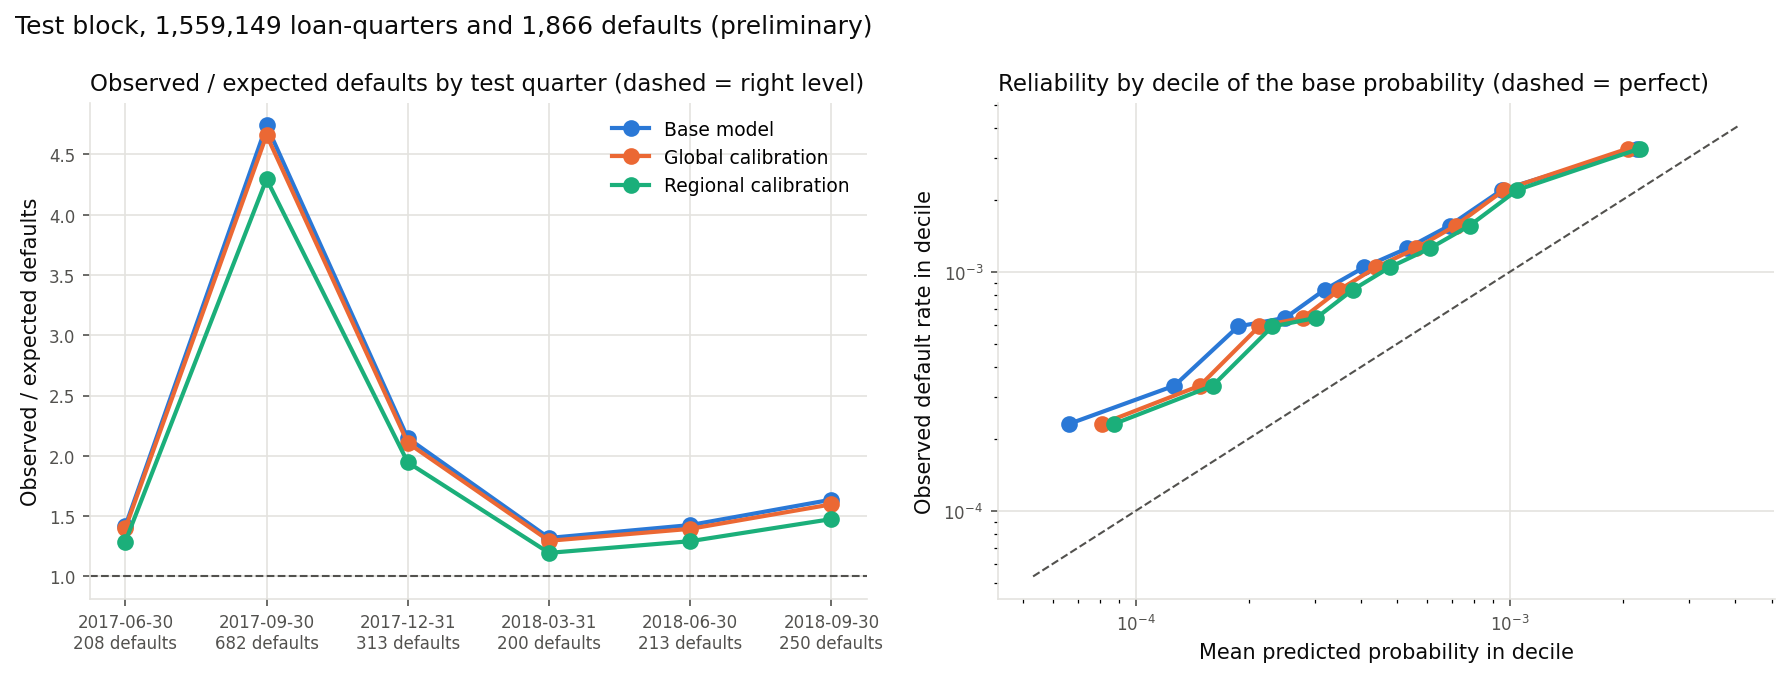

**Ranking drifts over time.** The base model (XGBoost) had ROC AUC 0.791 on validation (2015), but 0.702 on the test (2017–2018) and 0.724 without the hurricane quarter.

**The level of risk drifts too.** The default rate was 0.071% in C1, 0.096% in C2 and 0.120% in the test (0.091% without the hurricane quarter). O/E on the test is 2.10 for the base model, 2.06 for the global calibration, 1.90 for the regional calibration. All three versions under-predict the future level of default.

**Global calibration** (platt, slope b = 0.93) changes the test log loss from 0.009233 to 0.009203. It is an increasing transformation, so the ranking and ROC AUC stay the same as for the base model.

**Regional calibration** (λ = 1, shifts for 11 states) has test log loss 0.009119 against 0.009203 for the global calibration (difference -0.000084). Without the 2017-09-30 quarter the difference is -0.000023. The Brier score barely moves (-1.3e-07 and -1.8e-08): with defaults this rare it mostly reflects the base rate. Florida and Texas alone give 97% of the total log-loss gain, and the hurricane quarter gives 77% of it.

**Answer.** On this future test, regional calibration with shrinkage gives slightly more accurate probabilities than one global calibration, and the sign holds without the hurricane quarter. The gain is small and shrinks about 4 times without that quarter. Participant 4's paired bootstrap over loans will show whether it is larger than test noise.


In [ ]:
from IPython.display import Image, Markdown
display(Image(filename=str(P3_DIR / "test_calibration_preliminary.png"), width=900))
display(Markdown((P3_DIR / "answer_preliminary.md").read_text()))

**In short:** the base model is XGBoost (validation AUC 0.791). On the test its AUC drops to 0.702, and the default rate goes up from 0.07% in C1 to 0.12%, so all three versions predict too few defaults (O/E 1.90–2.10). Regional calibration has the lowest log loss (0.009119 vs 0.009203 for the global one), and the sign stays the same without the hurricane quarter (0.007010 vs 0.007034), but the gain is small and mostly comes from Florida and Texas. Whether it is more than noise is checked by the bootstrap in part 4.

# Part 4. Independent evaluation

My job was to check the results of parts 2 and 3 on my own, add the paper's H-measure and the uncertainty (bootstrap intervals), and run our practical check: how many defaults a bank would catch if it can review only 1% of its loans each quarter.

### 4.1 Part 2 test predictions
First I load all test predictions from part 2 and do the basic checks: rows, loans, defaults, duplicates and that every probability is between 0 and 1.

In [ ]:
from pathlib import Path
from zipfile import ZipFile

r_zip = Path("/content/Participant_4_Evaluation_R.zip")
if not r_zip.is_file() and Path("/content/mortgage_part2/R_test/test_scores.csv").is_file():
    import shutil   # part 2 was run in this session: pack its folder the way part 4 reads it
    shutil.make_archive("/content/Participant_4_Evaluation_R", "zip", "/content", "mortgage_part2")

with ZipFile(r_zip) as archive:
    r_files = [
        name for name in archive.namelist()
        if name.startswith("mortgage_part2/R_test/")
        and name.endswith("/test_predictions.parquet")
    ]

import pandas as pd
from io import BytesIO

with ZipFile(r_zip) as archive:
    r_data = pd.concat(
        [pd.read_parquet(BytesIO(archive.read(name))) for name in sorted(r_files)],
        ignore_index=True
    )

print("Test rows:", len(r_data))
print("Unique loans:", r_data["loan_id"].nunique())
print("Regions:", r_data["state"].nunique())
print("Defaults:", r_data["y_true"].sum())
print("Duplicate loan-quarter pairs:", r_data.duplicated(["loan_id", "report_date"]).sum())

Test rows: 1028112
Unique loans: 83014
Regions: 51
Defaults: 987
Duplicate loan-quarter pairs: 0


In [ ]:
prediction_cols = [
    col for col in r_data.columns
    if col.startswith("p_") and "raw" not in col
]

print("Main prediction columns:", len(prediction_cols))
print("Protocol:", r_data["protocol"].unique().tolist())
print("Split:", r_data["split"].unique().tolist())
print("Invalid labels:", (~r_data["y_true"].isin([0, 1])).sum())

for col in prediction_cols:
    valid = r_data[col].between(0, 1).fillna(False)
    print(col, "— invalid values:", (~valid).sum())

Main prediction columns: 13
Protocol: ['R']
Split: ['test']
Invalid labels: 0
p_constant — invalid values: 0
p_natural_logit_with_ltv — invalid values: 0
p_natural_logit_without_ltv — invalid values: 0
p_natural_gb_with_ltv — invalid values: 0
p_natural_gb_without_ltv — invalid values: 0
p_natural_xgb_with_ltv — invalid values: 0
p_natural_xgb_without_ltv — invalid values: 0
p_undersampling_logit_with_ltv — invalid values: 0
p_undersampling_logit_without_ltv — invalid values: 0
p_undersampling_gb_with_ltv — invalid values: 0
p_undersampling_gb_without_ltv — invalid values: 0
p_undersampling_xgb_with_ltv — invalid values: 0
p_undersampling_xgb_without_ltv — invalid values: 0


### 4.2 Recomputing the part 2 metrics


In [ ]:
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss, log_loss
)

model_cols = [col for col in prediction_cols if col != "p_constant"]
rows = []

for state, group in r_data.groupby("state"):
    y = group["y_true"]

    for col in model_cols:
        _, training, model, features = col.split("_", 3)
        p = group[col].to_numpy(dtype="float64")

        rows.append({
            "state": state,
            "training": training,
            "model": model,
            "features": features,
            "ROC AUC": roc_auc_score(y, p),
            "Average precision": average_precision_score(y, p),
            "Brier score": brier_score_loss(y, p),
            "Log loss": log_loss(y, p, labels=[0, 1])
        })

r_scores = pd.DataFrame(rows)
print("Results:", len(r_scores))

ca_main = r_scores.query(
    "state == 'CA' and training == 'natural' and features == 'with_ltv'"
)
display(ca_main.round(6))

Results: 612


,state,training,model,features,ROC AUC,Average precision,Brier score,Log loss
48,CA,natural,logit,with_ltv,0.767421,0.003245,0.000618,0.004885
50,CA,natural,gb,with_ltv,0.852950,0.044971,0.000630,0.004501
52,CA,natural,xgb,with_ltv,0.883721,0.015312,0.000617,0.004335


In [ ]:
with ZipFile(r_zip) as archive:
    with archive.open("mortgage_part2/R_test/test_scores.csv") as file:
        reference = pd.read_csv(file)
reference["model"] = reference["model"].str.lower().replace({
    "logistic regression": "logit",
    "gradient boosting": "gb",
    "xgboost": "xgb"
})

keys = ["state", "training", "model", "features"]
metrics = ["ROC AUC", "Average precision", "Brier score", "Log loss"]

check = r_scores.merge(
    reference[keys + metrics],
    on=keys,
    how="outer",
    suffixes=("_ours", "_team"),
    validate="one_to_one",
    indicator=True
)

print("Matched rows:", check["_merge"].eq("both").sum())
print("Unmatched rows:", check["_merge"].ne("both").sum())

for metric in metrics:
    diff = (check[f"{metric}_ours"] - check[f"{metric}_team"]).abs()
    print(f"{metric}: max difference = {diff.max():.3e}")

Matched rows: 612
Unmatched rows: 0
ROC AUC: max difference = 1.110e-16
Average precision: max difference = 9.931e-17
Brier score: max difference = 9.996e-17
Log loss: max difference = 9.975e-17


Mean within-state AUC gain over the logit for each setup, for all 51 regions and for the 27 regions that had their own tuning:

In [ ]:
with ZipFile(r_zip) as archive:
    with archive.open("mortgage_part2/R_regions/validation_scores.csv") as file:
        validation = pd.read_csv(file)

local_states = set(validation.loc[validation["tuning"] == "local", "state"])
assert len(local_states) == 27
assert local_states == set(validation.loc[validation["train_defaults"] >= 30, "state"])

groups = {
    "All 51 regions": r_scores,
    "27 regions with local tuning": r_scores[r_scores["state"].isin(local_states)]
}

rows = []
for group_name, scores in groups.items():
    for (training, features), part in scores.groupby(["training", "features"]):
        auc = part.pivot(index="state", columns="model", values="ROC AUC")
        gb_gain = auc["gb"] - auc["logit"]
        xgb_gain = auc["xgb"] - auc["logit"]

        rows.append({
            "Group": group_name,
            "Training": training,
            "Features": features,
            "GB mean AUC gain": gb_gain.mean(),
            "GB wins": f"{(gb_gain > 0).sum()}/{len(auc)}",
            "XGB mean AUC gain": xgb_gain.mean(),
            "XGB wins": f"{(xgb_gain > 0).sum()}/{len(auc)}"
        })

r_robustness = pd.DataFrame(rows)
display(r_robustness.round(4))

,Group,Training,Features,GB mean AUC gain,GB wins,XGB mean AUC gain,XGB wins
0,All 51 regions,natural,with_ltv,0.0422,36/51,0.0402,38/51
1,All 51 regions,natural,without_ltv,0.0194,35/51,0.0262,32/51
2,All 51 regions,undersampling,with_ltv,0.0365,38/51,0.0404,37/51
3,All 51 regions,undersampling,without_ltv,0.0164,35/51,0.0331,36/51
4,27 regions with local tuning,natural,with_ltv,0.0714,24/27,0.0680,24/27
5,27 regions with local tuning,natural,without_ltv,0.0551,22/27,0.0475,21/27
6,27 regions with local tuning,undersampling,with_ltv,0.0581,23/27,0.0655,22/27
7,27 regions with local tuning,undersampling,without_ltv,0.0449,23/27,0.0487,22/27


### 4.3 H-measure


In [ ]:
import numpy as np
from scipy.special import betainc, betaincc
from sklearn.isotonic import IsotonicRegression

def h_measure(y, scores):
    y = np.asarray(y, dtype=int)
    pi1 = y.mean()
    if pi1 == 0 or pi1 == 1:
        return np.nan

    pi0 = 1 - pi1
    severity = pi1 / pi0
    a, b = 2.0, 1.0 + 1.0 / severity
    cutoff = IsotonicRegression(increasing=True).fit_transform(scores, y)

    def false_alarm_loss(t):
        return a / (a + b) * betainc(a + 1, b, t)

    def missed_default_loss(t):
        return b / (a + b) * betaincc(a, b + 1, t)

    loss = (
        false_alarm_loss(cutoff[y == 0]).sum()
        + missed_default_loss(cutoff[y == 1]).sum()
    ) / len(y)

    baseline = pi0 * false_alarm_loss(pi1) + pi1 * missed_default_loss(pi1)
    return 1 - loss / baseline
rng = np.random.default_rng(66)
example_y = rng.integers(0, 2, size=10)
example_scores = rng.random(10)
assert np.isclose(h_measure(example_y, example_scores), 0.18889596344769588)

ca = r_data.loc[r_data["state"] == "CA"]
y_ca = ca["y_true"].to_numpy()

print("CA defaults:", y_ca.sum())
print("CA severity ratio:", round(y_ca.sum() / (len(y_ca) - y_ca.sum()), 8))

for model in ["logit", "gb", "xgb"]:
    scores = ca[f"p_natural_{model}_with_ltv"].to_numpy()
    print(f"{model}: H = {h_measure(y_ca, scores):.6f}")

CA defaults: 81
CA severity ratio: 0.00061948
logit: H = 0.229518
gb: H = 0.446837
xgb: H = 0.535735


In [ ]:
h_rows = []

for state, group in r_data.groupby("state"):
    y = group["y_true"].to_numpy()

    for col in model_cols:
        _, training, model, features = col.split("_", 3)
        h_rows.append({
            "state": state,
            "training": training,
            "model": model,
            "features": features,
            "H": h_measure(y, group[col].to_numpy())
        })

r_h = pd.DataFrame(h_rows)

main_h = (
    r_h.query("training == 'natural' and features == 'with_ltv'")
       .pivot(index="state", columns="model", values="H")
       .dropna()
)

print("H-measure rows:", len(r_h))
print("Regions with H for all three models:", len(main_h))

for model in ["gb", "xgb"]:
    gain = main_h[model] - main_h["logit"]
    print(f"{model}: higher H in {(gain > 0).sum()}/{len(gain)} regions, "
          f"mean H difference = {gain.mean():.6f}")

H-measure rows: 612
Regions with H for all three models: 51
gb: higher H in 35/51 regions, mean H difference = 0.078361
xgb: higher H in 35/51 regions, mean H difference = 0.067268


#### H-measure results

All 51 regions had both defaults and non-defaults in the test set, so H-measure could be calculated for every region. With the full training sample and current LTV, GB and XGBoost each achieved a higher H-measure than logistic regression in 35 of 51 regions. The mean within-region gain over logistic regression was 0.0784 for GB and 0.0673 for XGBoost.

### 4.4 Bootstrap intervals for the AUC gain
One test AUC does not show how noisy it is, especially in small states. Inside each state I resample loans  1,000 times and take the 2.5% and 97.5% quantiles of the gain over the logit. California first, then all 51 states.

In [ ]:
def bootstrap_auc(group, seed, repeats=1000):
    rng = np.random.default_rng(seed)
    loan_index, loans = pd.factorize(group["loan_id"])
    n_loans = len(loans)
    y = group["y_true"].to_numpy()

    scores = {
        model: group[f"p_natural_{model}_with_ltv"].to_numpy()
        for model in ["logit", "gb", "xgb"]
    }

    differences = np.full((repeats, 2), np.nan)

    for i in range(repeats):
        sample = rng.integers(0, n_loans, size=n_loans)
        loan_weights = np.bincount(sample, minlength=n_loans)
        weights = loan_weights[loan_index]

        defaults = weights[y == 1].sum()
        if defaults == 0 or defaults == weights.sum():
            continue

        auc = {
            model: roc_auc_score(y, p, sample_weight=weights)
            for model, p in scores.items()
        }
        differences[i] = [auc["gb"] - auc["logit"], auc["xgb"] - auc["logit"]]

    return pd.DataFrame(differences, columns=["GB − logit", "XGB − logit"])


ca_boot = bootstrap_auc(r_data.loc[r_data["state"] == "CA"], seed=20261116)

print("Valid bootstrap repeats:", len(ca_boot.dropna()), "/", len(ca_boot))
ca_intervals = ca_boot.quantile([0.025, 0.975]).T
ca_intervals.columns = ["95% CI lower", "95% CI upper"]
display(ca_intervals.round(4))

Valid bootstrap repeats: 1000 / 1000


,95% CI lower,95% CI upper
GB − logit,0.0297,0.1471
XGB − logit,0.0706,0.1658


In [ ]:
from tqdm.auto import tqdm
main_auc = (
    r_scores.query("training == 'natural' and features == 'with_ltv'")
    .pivot(index="state", columns="model", values="ROC AUC")
)

r_boot_draws = {"CA": ca_boot}
interval_rows = []

groups = r_data.groupby("state", sort=True)
for i, (state, group) in enumerate(tqdm(groups, total=groups.ngroups)):
    if state != "CA":
        r_boot_draws[state] = bootstrap_auc(group, seed=20261116 + i + 1)

    draws = r_boot_draws[state]
    for model, contrast in [("gb", "GB − logit"), ("xgb", "XGB − logit")]:
        valid = draws[contrast].dropna()
        lower, upper = valid.quantile([0.025, 0.975])

        interval_rows.append({
            "state": state,
            "model": model,
            "defaults": int(group["y_true"].sum()),
            "AUC gain": main_auc.loc[state, model] - main_auc.loc[state, "logit"],
            "CI lower": lower,
            "CI upper": upper,
            "valid repeats": len(valid)
        })

r_auc_intervals = pd.DataFrame(interval_rows)
print("Interval rows:", len(r_auc_intervals))
print("Minimum valid repeats:", r_auc_intervals["valid repeats"].min())

display(
    r_auc_intervals[r_auc_intervals["model"] == "gb"]
    .nsmallest(5, "valid repeats")
    .round(4)
)

Interval rows: 102
Minimum valid repeats: 650


,state,model,defaults,AUC gain,CI lower,CI upper,valid repeats
0,AK,gb,1,0.0839,0.0441,0.1252,650
52,MT,gb,2,-0.1815,-0.3053,-0.0688,859
56,ND,gb,2,0.0234,-0.0602,0.1136,866
92,VT,gb,2,-0.1479,-0.3137,0.0121,868
100,WY,gb,2,0.1783,-0.0078,0.3711,871


The plot shows the gain with its interval for every state, with and without current LTV:

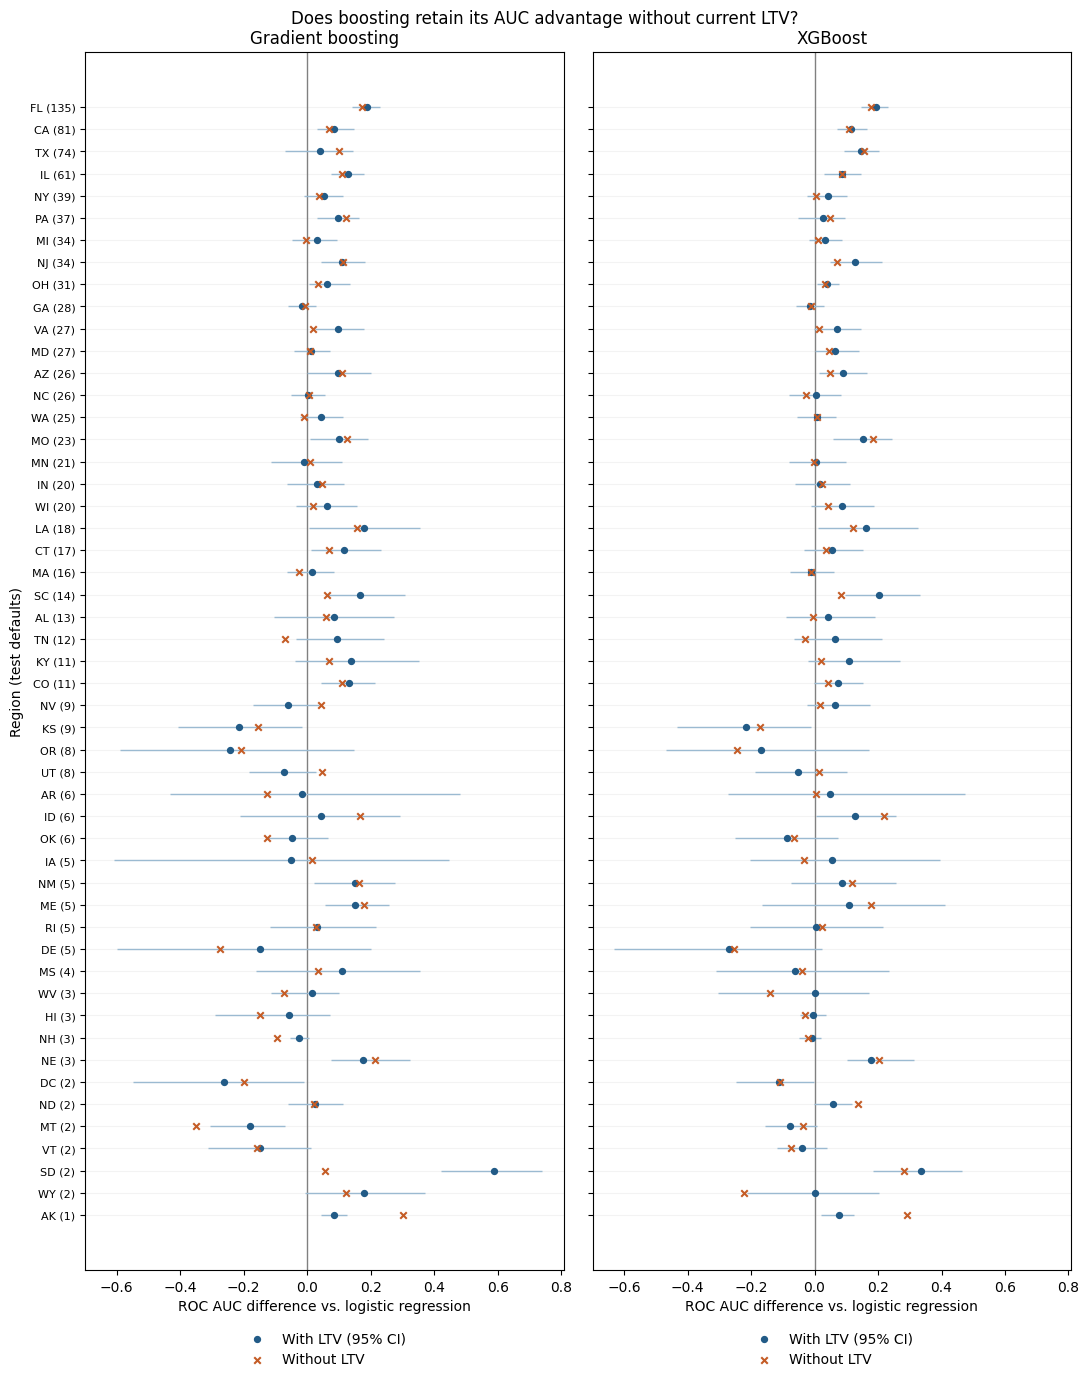

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt

out_dir = Path("/content/part4_outputs")
out_dir.mkdir(exist_ok=True)
r_auc_intervals.to_csv(out_dir / "R_auc_intervals.csv", index=False)
auc = (
    r_scores.query("training == 'natural'")
    .pivot(index=["state", "features"], columns="model", values="ROC AUC")
)
gains = auc[["gb", "xgb"]].sub(auc["logit"], axis=0)
with_ltv = gains.xs("with_ltv", level="features")
without_ltv = gains.xs("without_ltv", level="features")
defaults = r_data.groupby("state")["y_true"].sum().sort_values(ascending=False)
states = defaults.index
y = np.arange(len(states))

fig, axes = plt.subplots(1, 2, figsize=(11, 14), sharex=True, sharey=True)

for ax, model, title in zip(axes, ["gb", "xgb"], ["Gradient boosting", "XGBoost"]):
    ci = (
        r_auc_intervals.query("model == @model")
        .set_index("state")
        .loc[states]
    )

    ax.axvline(0, color="gray", linewidth=1)
    ax.hlines(y, ci["CI lower"], ci["CI upper"], color="#9bbad1", linewidth=1)
    ax.scatter(with_ltv.loc[states, model], y, s=18, color="#225b87",
               label="With LTV (95% CI)", zorder=3)
    ax.scatter(without_ltv.loc[states, model], y, s=22, color="#c45c26",
               marker="x", label="Without LTV", zorder=3)

    ax.set_title(title)
    ax.set_xlabel("ROC AUC difference vs. logistic regression")
    ax.grid(axis="y", alpha=0.15)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.04), frameon=False)

axes[0].set_yticks(y, [f"{s} ({defaults[s]})" for s in states], fontsize=8)
axes[0].set_ylabel("Region (test defaults)")
axes[0].invert_yaxis()
fig.suptitle("Does boosting retain its AUC advantage without current LTV?")
fig.tight_layout()
fig.savefig(out_dir / "R_auc_gain_by_region.png", dpi=180, bbox_inches="tight")
plt.show()

### 4.5 Calibration on the R test set


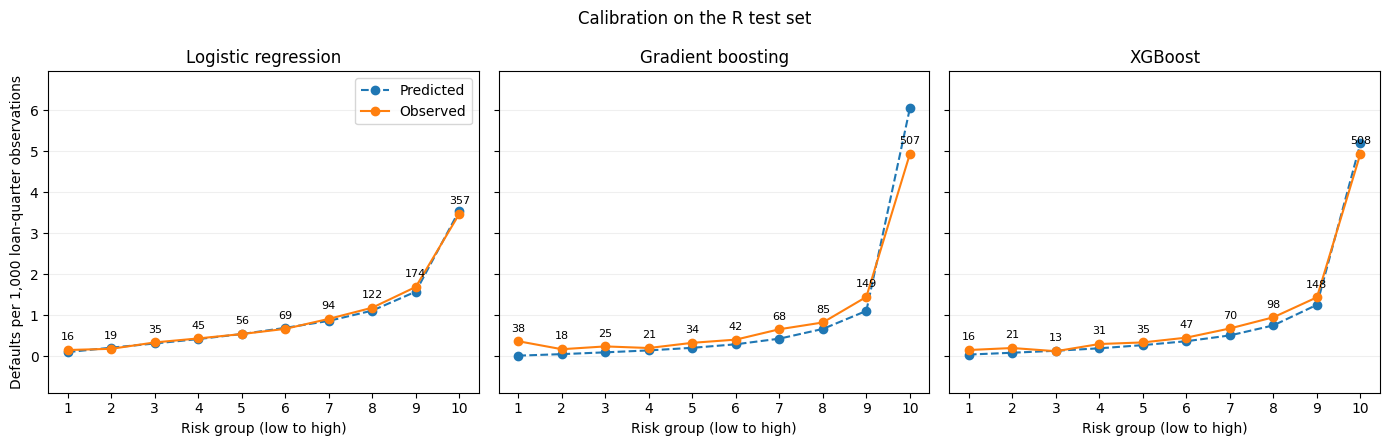

          rows  defaults
model                   
gb     1028112       987
logit  1028112       987
xgb    1028112       987


In [ ]:
models = {"logit": "Logistic regression", "gb": "Gradient boosting", "xgb": "XGBoost"}
calibration_tables = []

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)

for ax, (model, title) in zip(axes, models.items()):
    p = r_data[f"p_natural_{model}_with_ltv"]
    bins = pd.qcut(p, q=10, labels=False, duplicates="drop")

    table = (
        pd.DataFrame({"risk_group": bins + 1, "p": p, "y": r_data["y_true"]})
        .groupby("risk_group", as_index=False)
        .agg(rows=("y", "size"), defaults=("y", "sum"),
             predicted=("p", "mean"), observed=("y", "mean"))
    )
    table["model"] = model
    calibration_tables.append(table)

    x = table["risk_group"]
    ax.plot(x, 1000 * table["predicted"], "o--", label="Predicted")
    ax.plot(x, 1000 * table["observed"], "o-", label="Observed")

    for group, rate, count in zip(x, table["observed"], table["defaults"]):
        ax.annotate(str(count), (group, 1000 * rate),
                    xytext=(0, 7), textcoords="offset points",
                    ha="center", fontsize=8)

    ax.set_title(title)
    ax.set_xlabel("Risk group (low to high)")
    ax.set_xticks(x)
    ax.margins(y=0.15)
    ax.grid(axis="y", alpha=0.2)

axes[0].set_ylabel("Defaults per 1,000 loan-quarter observations")
axes[0].legend()
fig.suptitle("Calibration on the R test set")
fig.tight_layout()
fig.savefig(out_dir / "R_calibration.png", dpi=180, bbox_inches="tight")
plt.show()

r_calibration = pd.concat(calibration_tables, ignore_index=True)
r_calibration.to_csv(out_dir / "R_calibration.csv", index=False)
print(r_calibration.groupby("model")[["rows", "defaults"]].sum())

### 4.6 Removing one quarter at a time


In [ ]:
r_quarter = pd.to_datetime(r_data["report_date"]).dt.to_period("Q")
models = ["logit", "gb", "xgb"]
quarter_rows = []

for quarter in tqdm(sorted(r_quarter.unique())):
    remaining = r_data.loc[r_quarter != quarter]
    state_gains = []

    for state, group in remaining.groupby("state"):
        y = group["y_true"]
        if y.nunique() < 2:
            continue

        auc = {
            model: roc_auc_score(y, group[f"p_natural_{model}_with_ltv"])
            for model in models
        }
        state_gains.append({
            "state": state,
            "gb": auc["gb"] - auc["logit"],
            "xgb": auc["xgb"] - auc["logit"]
        })

    gains = pd.DataFrame(state_gains).set_index("state")
    baseline = main_auc.loc[gains.index]

    for model in ["gb", "xgb"]:
        full_gain = (baseline[model] - baseline["logit"]).mean()
        remaining_gain = gains[model].mean()
        quarter_rows.append({
            "Excluded quarter": str(quarter),
            "Model": model,
            "Regions": len(gains),
            "Full-test gain": full_gain,
            "Gain without quarter": remaining_gain,
            "Change": remaining_gain - full_gain
        })

r_quarter_check = pd.DataFrame(quarter_rows)
r_quarter_check.to_csv(out_dir / "R_quarter_sensitivity.csv", index=False)

print("Range of mean AUC gains after excluding one quarter:")
display(r_quarter_check.groupby("Model")["Gain without quarter"]
        .agg(["min", "max"]).round(4))

print("Quarter whose exclusion changed the result most for each model:")
largest = r_quarter_check.groupby("Model")["Change"].apply(lambda x: x.abs().idxmax())
display(r_quarter_check.loc[largest].round(4))

Range of mean AUC gains after excluding one quarter:


,min,max
Model,,
gb,0.0345,0.0511
xgb,0.0330,0.0460


Quarter whose exclusion changed the result most for each model:


,Excluded quarter,Model,Regions,Full-test gain,Gain without quarter,Change
34,2017Q2,gb,51,0.0422,0.0511,0.0089
47,2018Q4,xgb,51,0.0402,0.0330,-0.0072


#### Result

We removed each of the 24 quarters in turn. The mean within-region ROC AUC gain over logistic regression remained positive in every case. It ranged from 0.0345 to 0.0511 for GB and from 0.0330 to 0.0460 for XGBoost.

### 4.7 Checking the part 3 predictions


In [ ]:
from pathlib import Path
from zipfile import ZipFile
from io import BytesIO
import pandas as pd

e_zip = Path("/content/participant_3_outputs.zip")
with ZipFile(e_zip) as archive:
    e_data = pd.read_parquet(
        BytesIO(archive.read("part3_outputs/predictions_E_part3.parquet"))
    )

e_data["report_date"] = pd.to_datetime(e_data["report_date"])
e_data["label_end_date"] = pd.to_datetime(e_data["label_end_date"])

summary = (
    e_data.groupby("split_E")
    .agg(
        rows=("y_true", "size"),
        defaults=("y_true", "sum"),
        quarters=("report_date", "nunique"),
        first_date=("report_date", "min"),
        last_date=("report_date", "max")
    )
)
display(summary)

prob_cols = ["p_base", "p_global", "p_regional"]
valid_probs = (e_data[prob_cols] > 0) & (e_data[prob_cols] < 1)
horizon_days = (e_data["label_end_date"] - e_data["report_date"]).dt.days

print("Duplicate loan-quarter pairs:",
      e_data.duplicated(["loan_id", "report_date"]).sum())
print("Invalid labels:", (~e_data["y_true"].isin([0, 1])).sum())
print("Invalid probabilities:", (~valid_probs.fillna(False)).sum().sum())
print("Rows outside the 90–92 day horizon:",
      (~horizon_days.between(90, 92)).sum())

e_test = e_data.loc[e_data["split_E"] == "test"].reset_index(drop=True)


,rows,defaults,quarters,first_date,last_date
split_E,,,,,
calibration_fit,446273,319,2,2016-03-31,2016-06-30
calibration_select,232387,224,1,2016-12-31,2016-12-31
test,1559149,1866,6,2017-06-30,2018-09-30


Duplicate loan-quarter pairs: 0
Invalid labels: 0
Invalid probabilities: 0
Rows outside the 90–92 day horizon: 0


In [ ]:
import hashlib
import json
import numpy as np
from scipy.special import expit, logit

with ZipFile(e_zip) as archive:
    raw = archive.read("part3_outputs/frozen_procedure.json")
    saved_hash = archive.read("part3_outputs/frozen_procedure.sha256").decode().strip()

hash_ok = hashlib.sha256(raw).hexdigest() == saved_hash
print("SHA-256 matches:", hash_ok)
assert hash_ok, "The procedure file does not match its saved checksum."

procedure = json.loads(raw)
cal = procedure["global_calibration"]
regional = procedure["regional_calibration"]
shifts = regional["shifts"]
assert set(shifts) == set(regional["eligible_states"])
clip = procedure["logit_clip"]
p_base = e_data["p_base"].to_numpy(dtype=float)
global_logit = cal["a"] + cal["b"] * logit(np.clip(p_base, clip, 1 - clip))

states = e_data["state"].astype(str)
state_shift = states.map(shifts).fillna(0.0).to_numpy()
global_rebuilt = expit(global_logit)
regional_rebuilt = expit(global_logit + state_shift)

outside = ~states.isin(shifts)
print("Regions with / without a shift:", len(shifts), "/", states[outside].nunique())
print("Max difference, global:",
      f"{np.max(np.abs(global_rebuilt - e_data['p_global'])):.3e}")
print("Max difference, regional:",
      f"{np.max(np.abs(regional_rebuilt - e_data['p_regional'])):.3e}")
print("Changed rows outside the 11 states:",
      (e_data.loc[outside, "p_global"] != e_data.loc[outside, "p_regional"]).sum())

SHA-256 matches: True
Regions with / without a shift: 11 / 40
Max difference, global: 0.000e+00
Max difference, regional: 0.000e+00
Changed rows outside the 11 states: 0


#### Test metrics

In [ ]:
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score

def evaluate_e(data, breakdown, group):
    y = data["y_true"].to_numpy()
    defaults = int(y.sum())
    rows = []

    for model in ["p_base", "p_global", "p_regional"]:
        p = data[model].to_numpy(dtype=float)
        rows.append({
            "breakdown": breakdown,
            "group": group,
            "model": model,
            "rows": len(y),
            "defaults": defaults,
            "observed rate": y.mean(),
            "mean prediction": p.mean(),
            "O/E": defaults / p.sum(),
            "Brier": brier_score_loss(y, p),
            "log loss": log_loss(y, p, labels=[0, 1]),
            "ROC AUC": roc_auc_score(y, p) if 0 < defaults < len(y) else np.nan
        })
    return rows

shock_date = pd.Timestamp("2017-09-30")
without_shock = e_test.loc[e_test["report_date"] != shock_date]

rows = evaluate_e(e_test, "overall", "Full test")
rows += evaluate_e(without_shock, "overall", "Without 2017-09-30")

for date, group in e_test.groupby("report_date"):
    rows += evaluate_e(group, "quarter", date.strftime("%Y-%m-%d"))

states = e_test["state"].astype(str)
state_group = states.where(states.isin(shifts), "Other 40 regions")
for name, group in e_test.groupby(state_group):
    rows += evaluate_e(group, "region", name)

e_metrics = pd.DataFrame(rows)
e_metrics.to_csv(out_dir / "E_test_metrics.csv", index=False)

overall = e_metrics.loc[e_metrics["breakdown"] == "overall"]
display(overall[["group", "model", "defaults", "O/E", "Brier", "log loss", "ROC AUC"]]
        .round({"O/E": 3, "Brier": 9, "log loss": 9, "ROC AUC": 4}))

,group,model,defaults,O/E,Brier,log loss,ROC AUC
0,Full test,p_base,1866,2.096,0.001195,0.009233,0.7022
1,Full test,p_global,1866,2.057,0.001195,0.009203,0.7022
2,Full test,p_regional,1866,1.899,0.001195,0.009119,0.7135
3,Without 2017-09-30,p_base,1184,1.586,0.000904,0.007048,0.7239
4,Without 2017-09-30,p_global,1184,1.556,0.000904,0.007034,0.7239
5,Without 2017-09-30,p_regional,1184,1.437,0.000904,0.007010,0.7250


#### Paired bootstrap for the differences
2,000 resamples of loan IDs; every sampled loan keeps its whole test history, and all three versions are scored on the same resample.

In [ ]:
from threadpoolctl import threadpool_limits

def bootstrap_e_losses(data, sample_name, repeats=2000, seed=20261116):
    loan_index, loans = pd.factorize(data["loan_id"])
    n_loans = len(loans)
    y = data["y_true"].to_numpy()
    rows_per_loan = np.bincount(loan_index, minlength=n_loans)
    losses = {}
    for model in ["p_base", "p_global", "p_regional"]:
        p = data[model].to_numpy(dtype=float)
        logloss = np.where(y == 1, -np.log(p), -np.log1p(-p))
        brier = (p - y) ** 2

        for metric, values in [("log loss", logloss), ("Brier", brier)]:
            losses[model, metric] = np.bincount(
                loan_index, weights=values, minlength=n_loans
            )

    totals = [rows_per_loan]
    labels = []
    for a, b in [("p_regional", "p_global"), ("p_global", "p_base")]:
        for metric in ["log loss", "Brier"]:
            totals.append(losses[a, metric] - losses[b, metric])
            labels.append((f"{a} − {b}", metric))

    totals = np.vstack(totals)
    point = totals[1:].sum(axis=1) / len(data)
    draws = np.empty((repeats, len(labels)))
    rng = np.random.default_rng(seed)

    with threadpool_limits(limits=1, user_api="blas"):
        for i in tqdm(range(repeats), desc=sample_name):
            sample = rng.integers(0, n_loans, size=n_loans)
            weights = np.bincount(sample, minlength=n_loans).astype(float)
            sampled_totals = totals @ weights
            draws[i] = sampled_totals[1:] / sampled_totals[0]

    result = pd.DataFrame(labels, columns=["comparison", "metric"])
    result.insert(0, "sample", sample_name)
    result["difference"] = point
    result["CI lower"], result["CI upper"] = np.quantile(draws, [0.025, 0.975], axis=0)
    result["share below zero"] = (draws < 0).mean(axis=0)
    return result

e_loss_intervals = pd.concat([
    bootstrap_e_losses(e_test, "Full test"),
    bootstrap_e_losses(without_shock, "Without 2017-09-30")
], ignore_index=True)

e_loss_intervals.to_csv(out_dir / "E_loss_intervals.csv", index=False)
display(e_loss_intervals.style.format({
    "difference": "{:.3e}", "CI lower": "{:.3e}", "CI upper": "{:.3e}",
    "share below zero": "{:.1%}"
}))

,sample,comparison,metric,difference,CI lower,CI upper,share below zero
0,Full test,p_regional − p_global,log loss,-8.417e-05,-9.403e-05,-7.463e-05,100.0%
1,Full test,p_regional − p_global,Brier,-1.261e-07,-1.603e-07,-9.645e-08,100.0%
2,Full test,p_global − p_base,log loss,-3.006e-05,-3.397e-05,-2.611e-05,100.0%
3,Full test,p_global − p_base,Brier,-1.623e-08,-3.146e-08,6.289e-10,96.8%
4,Without 2017-09-30,p_regional − p_global,log loss,-2.335e-05,-3.129e-05,-1.542e-05,100.0%
5,Without 2017-09-30,p_regional − p_global,Brier,-1.776e-08,-4.684e-08,1.013e-08,90.0%
6,Without 2017-09-30,p_global − p_base,log loss,-1.478e-05,-1.829e-05,-1.110e-05,100.0%
7,Without 2017-09-30,p_global − p_base,Brier,-1.879e-08,-3.450e-08,-1.956e-09,98.5%


### 4.9 Calibration plots

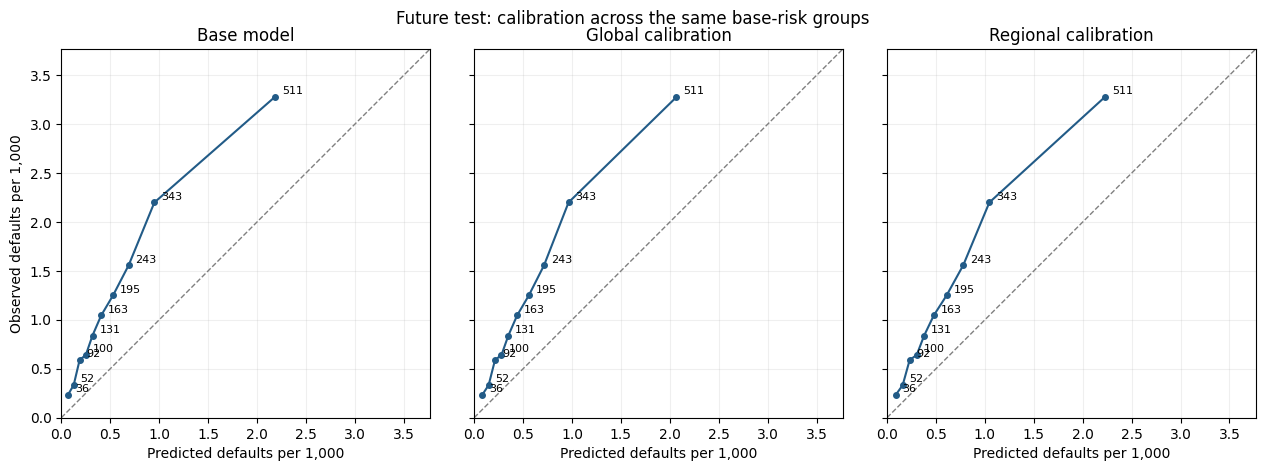

Risk groups: 10
Total defaults: 1866


In [ ]:
risk_group = pd.qcut(e_test["p_base"], q=10, labels=False, duplicates="drop") + 1

e_reliability = (
    e_test.groupby(risk_group.rename("risk_group"))
    .agg(
        rows=("y_true", "size"),
        defaults=("y_true", "sum"),
        observed=("y_true", "mean"),
        p_base=("p_base", "mean"),
        p_global=("p_global", "mean"),
        p_regional=("p_regional", "mean")
    )
    .reset_index()
)
e_reliability.to_csv(out_dir / "E_reliability.csv", index=False)

models = {
    "p_base": "Base model",
    "p_global": "Global calibration",
    "p_regional": "Regional calibration"
}
rates = 1000 * e_reliability[["observed", *models]]
upper = 1.15 * rates.max().max()

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), sharex=True, sharey=True)

for ax, (model, title) in zip(axes, models.items()):
    ax.plot([0, upper], [0, upper], "--", color="gray", linewidth=1)
    ax.plot(rates[model], rates["observed"], "o-", color="#225b87", markersize=4)

    for x, y, count in zip(rates[model], rates["observed"], e_reliability["defaults"]):
        ax.annotate(str(count), (x, y), xytext=(5, 2),
                    textcoords="offset points", fontsize=8)

    ax.set(xlim=(0, upper), ylim=(0, upper), title=title,
           xlabel="Predicted defaults per 1,000")
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Observed defaults per 1,000")
fig.suptitle("Future test: calibration across the same base-risk groups")
fig.tight_layout()
fig.savefig(out_dir / "E_reliability.png", dpi=180, bbox_inches="tight")
plt.show()

print("Risk groups:", len(e_reliability))
print("Total defaults:", e_reliability["defaults"].sum())

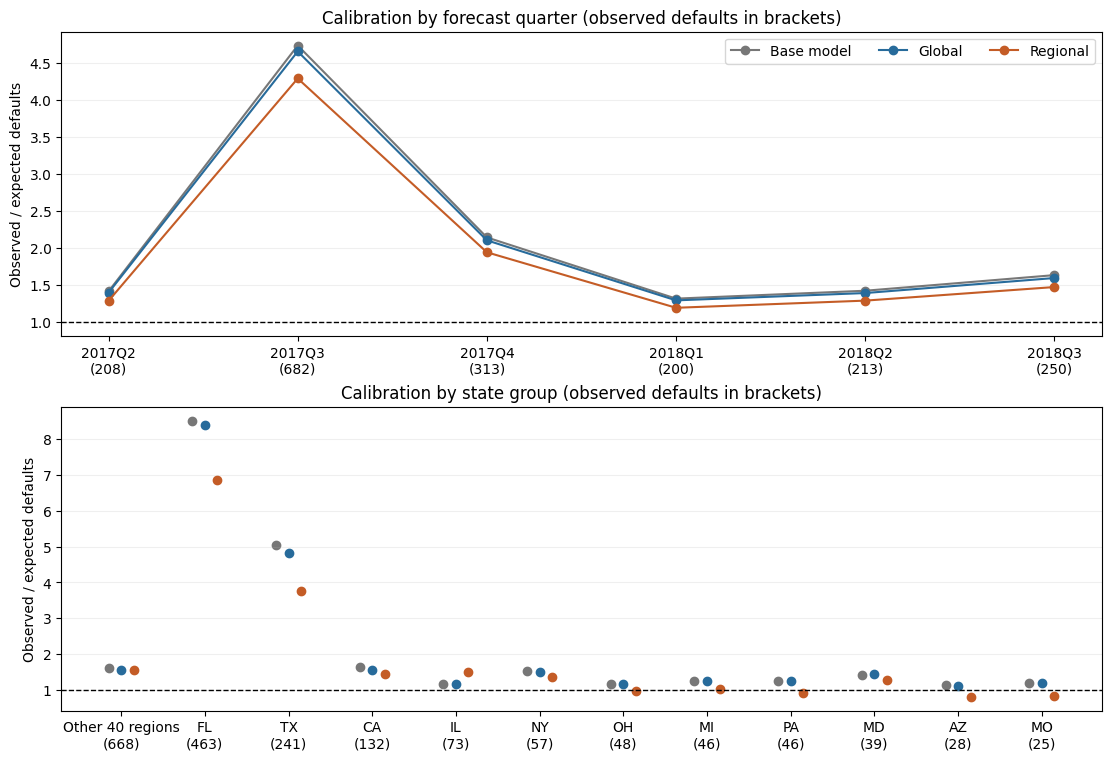

In [ ]:
colors = {"p_base": "#777777", "p_global": "#276b9b", "p_regional": "#c45c26"}
names = {"p_base": "Base model", "p_global": "Global", "p_regional": "Regional"}

fig, axes = plt.subplots(2, 1, figsize=(11, 7.5), layout="constrained")

for ax, breakdown in zip(axes, ["quarter", "region"]):
    data = e_metrics.loc[e_metrics["breakdown"] == breakdown]
    oe = data.pivot(index="group", columns="model", values="O/E")
    counts = data.drop_duplicates("group").set_index("group")["defaults"]

    if breakdown == "quarter":
        oe = oe.sort_index()
    else:
        oe = oe.loc[counts.sort_values(ascending=False).index]

    x = np.arange(len(oe))
    for offset, model in zip([-0.15, 0, 0.15], names):
        if breakdown == "quarter":
            ax.plot(x, oe[model], "o-", color=colors[model], label=names[model])
        else:
            ax.scatter(x + offset, oe[model], color=colors[model], label=names[model])

    labels = [
        str(pd.Period(g, freq="Q")) if breakdown == "quarter" else g
        for g in oe.index
    ]
    ax.set_xticks(x, [f"{label}\n({counts[g]})" for label, g in zip(labels, oe.index)])
    ax.axhline(1, color="black", linestyle="--", linewidth=1)
    ax.set_ylabel("Observed / expected defaults")
    ax.grid(axis="y", alpha=0.2)

axes[0].set_title("Calibration by forecast quarter (observed defaults in brackets)")
axes[1].set_title("Calibration by state group (observed defaults in brackets)")
axes[0].legend(ncol=3)
fig.savefig(out_dir / "E_calibration_by_quarter_and_region.png", dpi=180)
plt.show()

### 4.10 Review budget: top 1% per quarter


In [ ]:
forecast_cols = ["p_base", "p_global", "p_regional"]
budgets = {5: "0.5%", 10: "1%", 20: "2%"}
quarter_orders = {}
budget_rows = []
y_test = e_test["y_true"].to_numpy()

for date, quarter in e_test.groupby("report_date", sort=True):
    orders = {}
    for model in forecast_cols:
        ranked = quarter.sort_values([model, "loan_id"], ascending=[False, True])
        orders[model] = ranked.index.to_numpy()
    quarter_orders[date] = orders

    total_defaults = int(quarter["y_true"].sum())

    for per_1000, budget in budgets.items():
        k = (per_1000 * len(quarter) + 999) // 1000
        assert np.array_equal(
            np.sort(orders["p_base"][:k]),
            np.sort(orders["p_global"][:k])
        ), f"Base and global lists differ for {date}, budget {budget}"

        for model in forecast_cols:
            selected = orders[model][:k]
            budget_rows.append({
                "quarter": date,
                "budget": budget,
                "model": model,
                "reviews": k,
                "found": int(y_test[selected].sum()),
                "defaults": total_defaults
            })

e_budget_quarters = pd.DataFrame(budget_rows)
e_budget_quarters["recall"] = e_budget_quarters["found"] / e_budget_quarters["defaults"]

e_budget_total = (
    e_budget_quarters.groupby(["budget", "model"], as_index=False)
    [["reviews", "found", "defaults"]].sum()
)
e_budget_total["recall"] = e_budget_total["found"] / e_budget_total["defaults"]

e_budget_quarters.to_csv(out_dir / "E_budget_by_quarter.csv", index=False)
e_budget_total.to_csv(out_dir / "E_budget_total.csv", index=False)
display(e_budget_total.style.format({"recall": "{:.2%}"}))

,budget,model,reviews,found,defaults,recall
0,0.5%,p_base,7799,41,1866,2.20%
1,0.5%,p_global,7799,41,1866,2.20%
2,0.5%,p_regional,7799,43,1866,2.30%
3,1%,p_base,15595,78,1866,4.18%
4,1%,p_global,15595,78,1866,4.18%
5,1%,p_regional,15595,78,1866,4.18%
6,2%,p_base,31186,152,1866,8.15%
7,2%,p_global,31186,152,1866,8.15%
8,2%,p_regional,31186,144,1866,7.72%


In [ ]:
top1 = e_budget_quarters.query("budget == '1%'")
quarter_summary = (
    top1.pivot(index=["quarter", "reviews", "defaults"],
               columns="model", values="found")
    .rename(columns={"p_global": "Global found", "p_regional": "Regional found"})
    .reset_index()
    .drop(columns="p_base")
    .sort_values("quarter")
)
quarter_summary["Difference"] = (
    quarter_summary["Regional found"] - quarter_summary["Global found"]
)
replaced = []
for date, k in zip(quarter_summary["quarter"], quarter_summary["reviews"]):
    orders = quarter_orders[date]
    global_list = set(orders["p_global"][:k])
    regional_list = set(orders["p_regional"][:k])
    replaced.append(len(regional_list - global_list))

quarter_summary["Places replaced"] = replaced
quarter_summary["Share replaced"] = quarter_summary["Places replaced"] / quarter_summary["reviews"]
quarter_summary.to_csv(out_dir / "E_top1_quarter_comparison.csv", index=False)

display(quarter_summary.style.format({
    "quarter": lambda d: str(pd.Period(d, freq="Q")),
    "Share replaced": "{:.1%}"
}))

without_shock = quarter_summary.loc[quarter_summary["quarter"] != shock_date]
print("Difference without 2017Q3:", without_shock["Difference"].sum())

model,quarter,reviews,defaults,Global found,Regional found,Difference,Places replaced,Share replaced
0,2017Q2,2456,208,11,13,2,406,16.5%
1,2017Q3,2509,682,21,23,2,436,17.4%
2,2017Q4,2571,313,11,11,0,444,17.3%
3,2018Q1,2623,200,13,10,-3,438,16.7%
4,2018Q2,2688,213,7,9,2,491,18.3%
5,2018Q3,2748,250,15,12,-3,552,20.1%


Difference without 2017Q3: -2


In [ ]:
loan_index, loans = pd.factorize(e_test["loan_id"])
y = e_test["y_true"].to_numpy(dtype=int)
dates = sorted(quarter_orders)
ranked = {}
for date in dates:
    ranked[date] = {}
    for model in ["p_global", "p_regional"]:
        order = quarter_orders[date][model]
        ranked[date][model] = (loan_index[order], y[order])


def found_in_top_k(ids, outcomes, weights, k):
    stop = min(2 * k, len(ids))
    counts = weights[ids[:stop]]
    while counts.sum() < k:
        stop = min(2 * stop, len(ids))
        counts = weights[ids[:stop]]

    return np.repeat(outcomes[:stop], counts)[:k].sum()


def quarterly_differences(weights):
    differences = []
    for date in dates:
        global_ids, global_y = ranked[date]["p_global"]
        regional_ids, regional_y = ranked[date]["p_regional"]

        n = weights[global_ids].sum()
        k = (n + 99) // 100

        global_found = found_in_top_k(global_ids, global_y, weights, k)
        regional_found = found_in_top_k(regional_ids, regional_y, weights, k)
        differences.append(regional_found - global_found)

    return differences
observed = quarter_summary.set_index("quarter").loc[dates, "Difference"]
np.testing.assert_array_equal(
    quarterly_differences(np.ones(len(loans), dtype=int)),
    observed.to_numpy()
)

B = 2000
rng = np.random.default_rng(20261116)
top1_draws = np.empty((B, len(dates)), dtype=int)

for i in tqdm(range(B), desc="Top 1% bootstrap"):
    sample = rng.integers(0, len(loans), size=len(loans))
    weights = np.bincount(sample, minlength=len(loans))
    top1_draws[i] = quarterly_differences(weights)

total_difference = top1_draws.sum(axis=1)
lower, upper = np.quantile(total_difference, [0.025, 0.975])

print("Observed difference:", observed.sum())
print("95% bootstrap interval:", lower, "to", upper)
print("Regional found more:", f"{(total_difference > 0).mean():.1%}")
print("Equal number found:", f"{(total_difference == 0).mean():.1%}")
print("Global found more:", f"{(total_difference < 0).mean():.1%}")

pd.DataFrame(top1_draws, columns=dates).to_csv(
    out_dir / "E_top1_bootstrap_draws.csv", index=False
)

Observed difference: 0
95% bootstrap interval: -10.0 to 8.0
Regional found more: 35.8%
Equal number found: 8.6%
Global found more: 55.6%


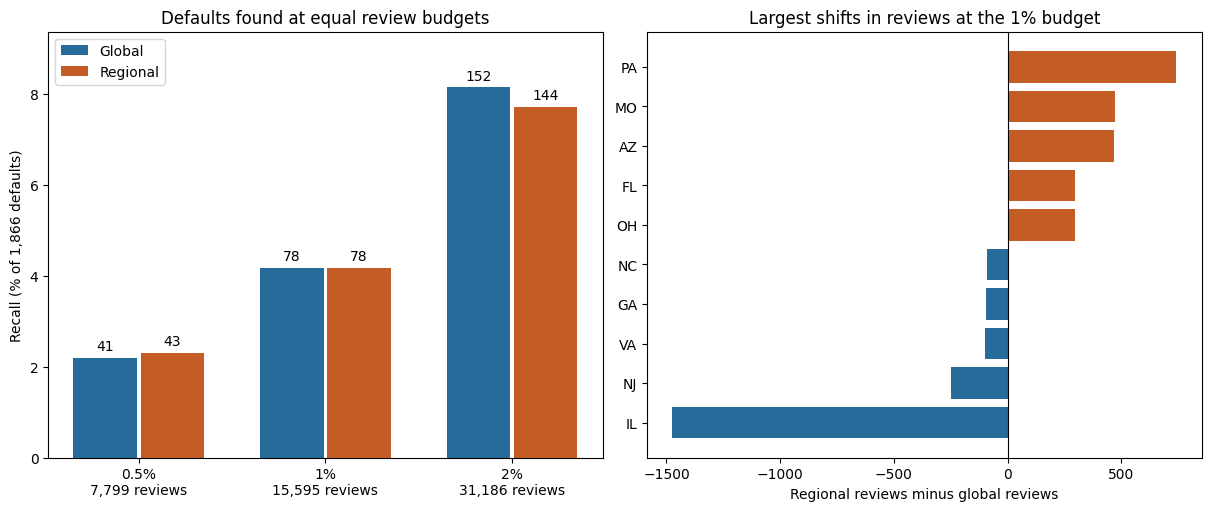

,Change in reviews
state,
IL,-1474
NJ,-250
VA,-98
GA,-96
NC,-92
OH,296
FL,297
AZ,468
MO,471


In [ ]:
states_test = e_test["state"].to_numpy()
state_counts = pd.DataFrame(
    0, index=sorted(e_test["state"].unique()), columns=["p_global", "p_regional"]
)

for date, k in zip(quarter_summary["quarter"], quarter_summary["reviews"]):
    for model in state_counts.columns:
        selected = quarter_orders[date][model][:k]
        counts = pd.Series(states_test[selected]).value_counts()
        state_counts.loc[counts.index, model] += counts

state_counts["change"] = state_counts["p_regional"] - state_counts["p_global"]
state_counts.index.name = "state"
assert (state_counts[["p_global", "p_regional"]].sum() == 15595).all()
assert state_counts["change"].sum() == 0
state_counts.to_csv(out_dir / "E_top1_reviews_by_state.csv")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
budget_order = ["0.5%", "1%", "2%"]
x = np.arange(len(budget_order))

for model, label, color, offset in [
    ("p_global", "Global", "#276b9b", -0.18),
    ("p_regional", "Regional", "#c45c26", 0.18)
]:
    data = e_budget_total.query("model == @model").set_index("budget").loc[budget_order]
    bars = ax1.bar(x + offset, 100 * data["recall"], 0.34, label=label, color=color)
    ax1.bar_label(bars, labels=data["found"].astype(str), padding=3)

reviews = e_budget_total.query("model == 'p_global'").set_index("budget")["reviews"]
ax1.set_xticks(x, [f"{b}\n{reviews[b]:,} reviews" for b in budget_order])
ax1.set_ylabel("Recall (% of 1,866 defaults)")
ax1.set_title("Defaults found at equal review budgets")
ax1.margins(y=0.15)
ax1.legend()

change = state_counts["change"].sort_values()
shown = pd.concat([change[change < 0].head(5), change[change > 0].tail(5)])
ax2.barh(shown.index, shown, color=np.where(shown > 0, "#c45c26", "#276b9b"))
ax2.axvline(0, color="black", linewidth=0.8)
ax2.set_xlabel("Regional reviews minus global reviews")
ax2.set_title("Largest shifts in reviews at the 1% budget")

fig.savefig(out_dir / "E_review_budget_and_states.png", dpi=180, bbox_inches="tight")
plt.show()

display(shown.rename("Change in reviews").to_frame())

#### Saving the results
Saves all tables and figures, checks that none is missing or empty and zips them as `participant_4_results.zip`.

In [ ]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

out_dir = Path("/content/part4_outputs")
keys = ["state", "training", "model", "features"]
r_final = r_scores.merge(r_h, on=keys, validate="one_to_one")
assert len(r_final) == 612
assert len(r_robustness) == 8
assert len(r_auc_intervals) == 102
r_final.to_csv(out_dir / "R_test_metrics.csv", index=False)
r_robustness.to_csv(out_dir / "R_robustness.csv", index=False)
boot_diff = top1_draws.sum(axis=1)
assert len(boot_diff) == 2000
ci_low, ci_high = np.quantile(boot_diff, [0.025, 0.975])

pd.DataFrame([{
    "comparison": "regional minus global",
    "budget": "1% per quarter",
    "reviews_per_method": quarter_summary["reviews"].sum(),
    "global_found": quarter_summary["Global found"].sum(),
    "regional_found": quarter_summary["Regional found"].sum(),
    "observed_difference": quarter_summary["Difference"].sum(),
    "ci_95_lower": ci_low,
    "ci_95_upper": ci_high,
    "places_replaced": quarter_summary["Places replaced"].sum(),
    "bootstrap_repeats": len(boot_diff),
    "seed": 20261116
}]).to_csv(out_dir / "E_top1_bootstrap_summary.csv", index=False)
expected = [
    "R_test_metrics.csv", "R_robustness.csv", "R_auc_intervals.csv",
    "R_quarter_sensitivity.csv", "R_calibration.csv",
    "R_auc_gain_by_region.png", "R_calibration.png",
    "E_test_metrics.csv", "E_loss_intervals.csv", "E_reliability.csv",
    "E_reliability.png", "E_calibration_by_quarter_and_region.png",
    "E_budget_by_quarter.csv", "E_budget_total.csv",
    "E_top1_quarter_comparison.csv", "E_top1_bootstrap_draws.csv",
    "E_top1_bootstrap_summary.csv", "E_top1_reviews_by_state.csv",
    "E_review_budget_and_states.png"
]

r_pooled = pd.DataFrame([
    {
        "prediction": col,
        "test_rows": len(r_data),
        "defaults": int(r_data["y_true"].sum()),
        "pooled ROC AUC": roc_auc_score(r_data["y_true"], r_data[col])
    }
    for col in model_cols
])
r_pooled.to_csv(out_dir / "R_pooled_auc.csv", index=False)
expected.append("R_pooled_auc.csv")
display(r_pooled)

missing = [
    name for name in expected
    if not (out_dir / name).is_file() or (out_dir / name).stat().st_size == 0
]
assert not missing, f"Missing or empty files: {missing}"

archive_path = Path("/content/participant_4_results.zip")
with ZipFile(archive_path, "w", compression=ZIP_DEFLATED) as archive:
    for name in expected:
        archive.write(out_dir / name, arcname=name)

with ZipFile(archive_path) as archive:
    assert archive.testzip() is None
    print(f"Archive verified: {len(archive.namelist())} files")

files.download(str(archive_path))

,prediction,test_rows,defaults,pooled ROC AUC
0,p_natural_logit_with_ltv,1028112,987,0.745659
1,p_natural_logit_without_ltv,1028112,987,0.746494
2,p_natural_gb_with_ltv,1028112,987,0.798693
3,p_natural_gb_without_ltv,1028112,987,0.794433
4,p_natural_xgb_with_ltv,1028112,987,0.810782
5,p_natural_xgb_without_ltv,1028112,987,0.798306
6,p_undersampling_logit_with_ltv,1028112,987,0.745995
7,p_undersampling_logit_without_ltv,1028112,987,0.748133
8,p_undersampling_gb_with_ltv,1028112,987,0.792422
9,p_undersampling_gb_without_ltv,1028112,987,0.785171


Archive verified: 20 files


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>